# TOJ – Observer Model (SDT)
**List of contents:**\
1- Generall TOJ (without trial-leading)\
2- Serial Dependence based on Prior Stimulus\
3- Serial Dependence based on Prior Response\
4- Visualizing Serial Dependence Statistical Results

In [2]:
###############################################################
# Load required libraries
###############################################################

library(tidyverse)
library(readxl)
library(minpack.lm)
library(rstatix)
library(ggpubr)
library(writexl)
library(ggplot2)
library(dplyr)
library(ggbeeswarm)
library(DEoptim)

###############################################################\
###############################################################
# Generall TOJ (without trial-leading)
**List of contents:**\
1-1 Load data\
1-2 Fit psychometric model\
1-3 Check fits\
1-4 Save Results

## 1-1 Load data

In [9]:
data <- read_xlsx("files/TOJ_general_data.xlsx")

In [10]:
head(data)

participant,SOA,resp,rt
<dbl>,<dbl>,<chr>,<dbl>
1,-400,a,1.788303
1,-400,a,1.537577
1,-400,a,1.554352
1,-400,a,1.353832
1,-400,a,1.504235
1,-400,a,1.771497


In [11]:
colnames(data)[1] <- 'ID'
colnames(data)[3] <- 'Visual_first'

In [12]:
data$Visual_first <- ifelse(data$Visual_first=='v', 1, 0)

## 1-2 Fit psychometric model

In [13]:
# model:
# P(visual first) = Φ(SOA | mean=criterion, sd=SD)

model <- function(data){
  loss_function <- function(params){
    SD <- params[1]
    criterion <- params[2]
    predicted <-  pnorm(data$SOA, mean = criterion, sd = SD)
    sum((predicted - data$Visual_first)^2)
  }

  DEoptim(
    loss_function,
    lower = c(.001, -500),
    upper = c(1200, 500)
  )
}

psy_results <- data.frame()

for(subj in unique(data$ID)){
    d1 <- data %>% filter(ID == subj)
    fit <- model(d1)$optim$bestmem
    psy_results <- rbind(
        psy_results,
        data.frame(
          ID = subj,
          SD = fit[1],
          criterion = fit[2]
))
}

rownames(psy_results) <- NULL

Iteration: 1 bestvalit: 123.285657 bestmemit:  176.984714  -65.115024
Iteration: 2 bestvalit: 123.285657 bestmemit:  176.984714  -65.115024
Iteration: 3 bestvalit: 123.285657 bestmemit:  176.984714  -65.115024
Iteration: 4 bestvalit: 123.285657 bestmemit:  176.984714  -65.115024
Iteration: 5 bestvalit: 123.285657 bestmemit:  176.984714  -65.115024
Iteration: 6 bestvalit: 121.830466 bestmemit:  304.240242  -68.218806
Iteration: 7 bestvalit: 121.351599 bestmemit:  266.415024  -76.055010
Iteration: 8 bestvalit: 121.351599 bestmemit:  266.415024  -76.055010
Iteration: 9 bestvalit: 120.858967 bestmemit:  225.555865  -43.015870
Iteration: 10 bestvalit: 120.709207 bestmemit:  232.695753  -52.703038
Iteration: 11 bestvalit: 120.709207 bestmemit:  232.695753  -52.703038
Iteration: 12 bestvalit: 120.709207 bestmemit:  232.695753  -52.703038
Iteration: 13 bestvalit: 120.707524 bestmemit:  244.865354  -56.881550
Iteration: 14 bestvalit: 120.707524 bestmemit:  244.865354  -56.881550
Iteration: 15 b

## 1-3 Check fits

In [14]:
# check if the parameter range in fitting is appropriate
sort(psy_results$SD)
sort(psy_results$criterion)

[1] 100.3546 108.6277 123.7126 128.6307 144.1133 181.4626 187.4369 189.5935
 [9] 197.5471 213.5215 213.5455 221.0994 226.7672 240.7688 255.4255 263.3387
[17] 340.3783 433.3554

[1] -172.201928 -118.285440 -106.287612 -101.185727  -90.866481  -52.585879
 [7]  -51.164074  -36.333387  -26.256731  -15.004029   -7.222641   -5.639777
[13]   -1.107875    1.981056    2.617239   42.528529   98.595574  140.660224

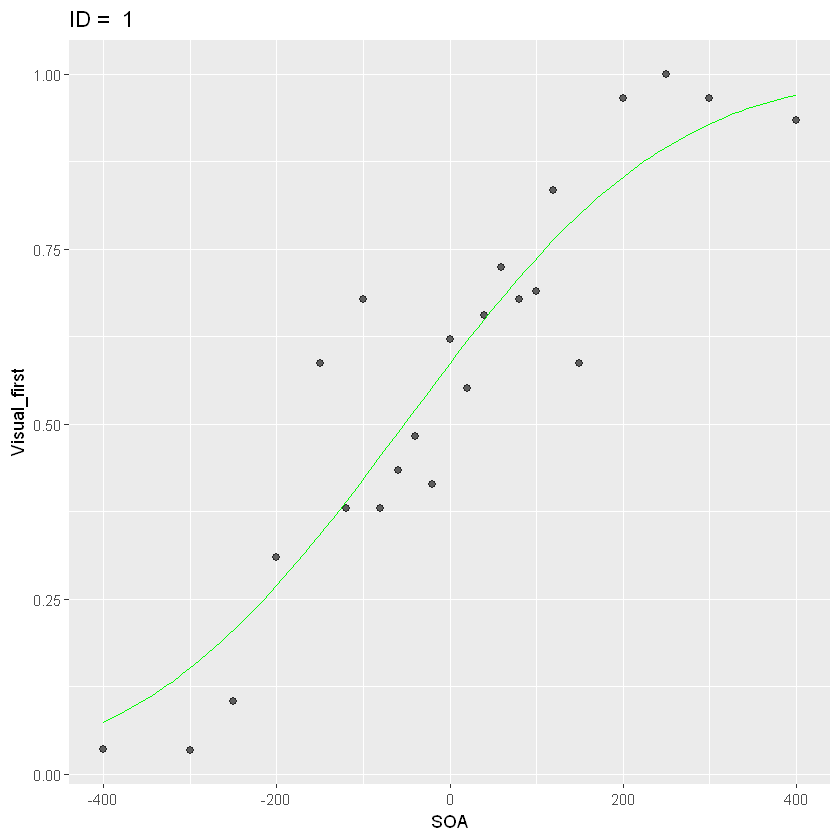

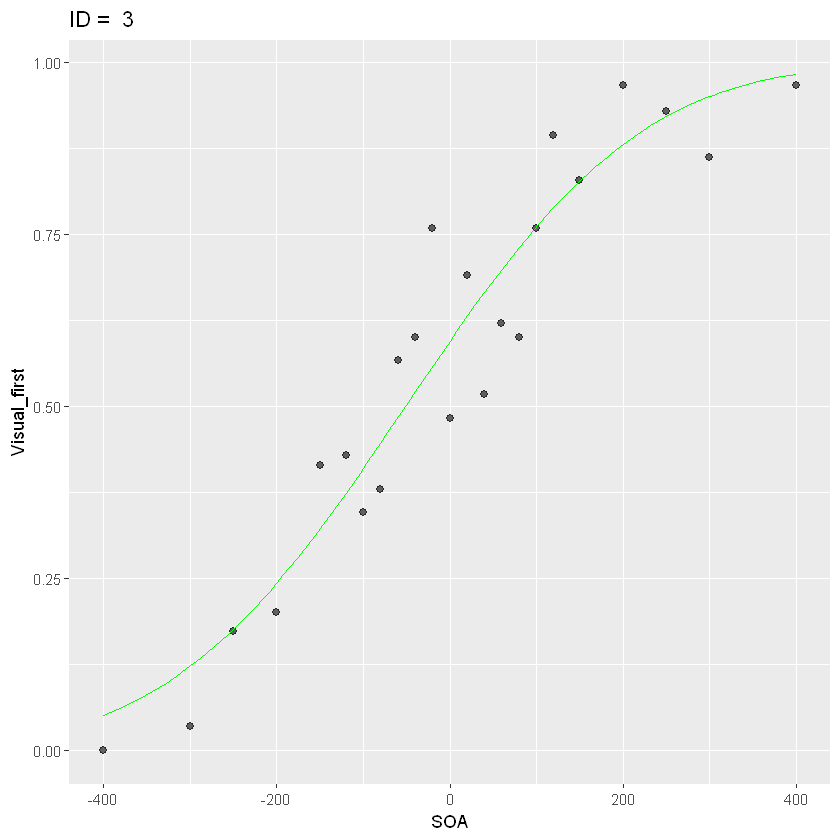

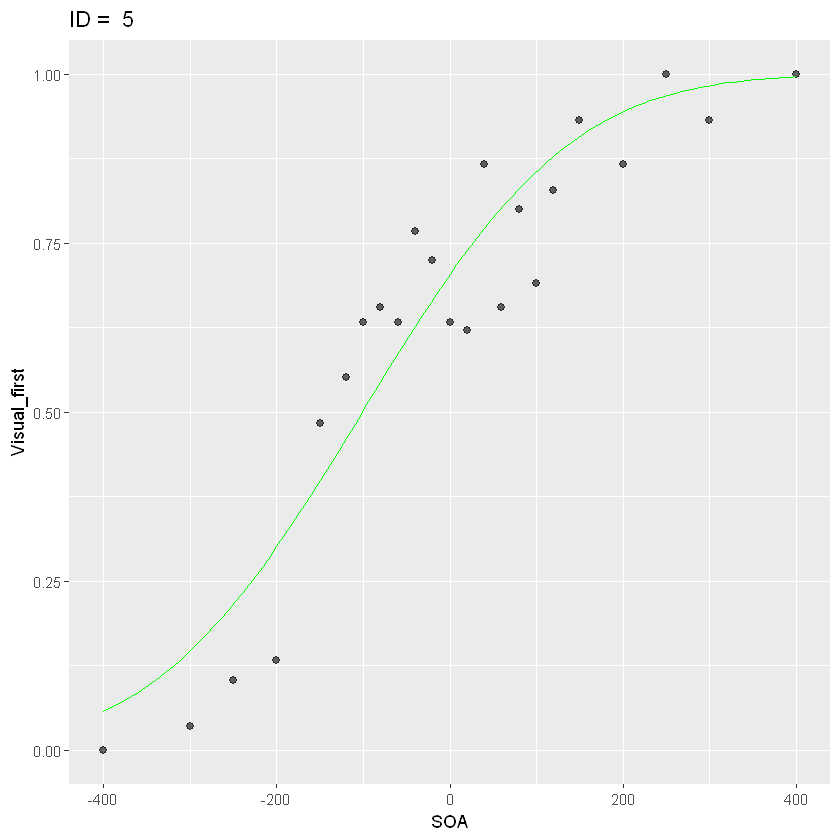

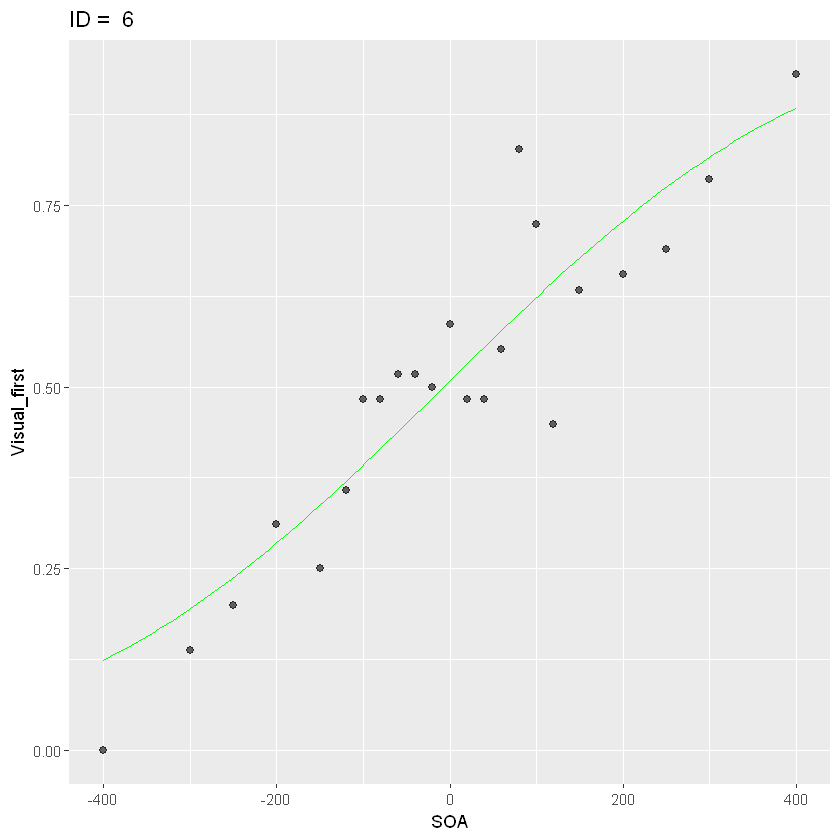

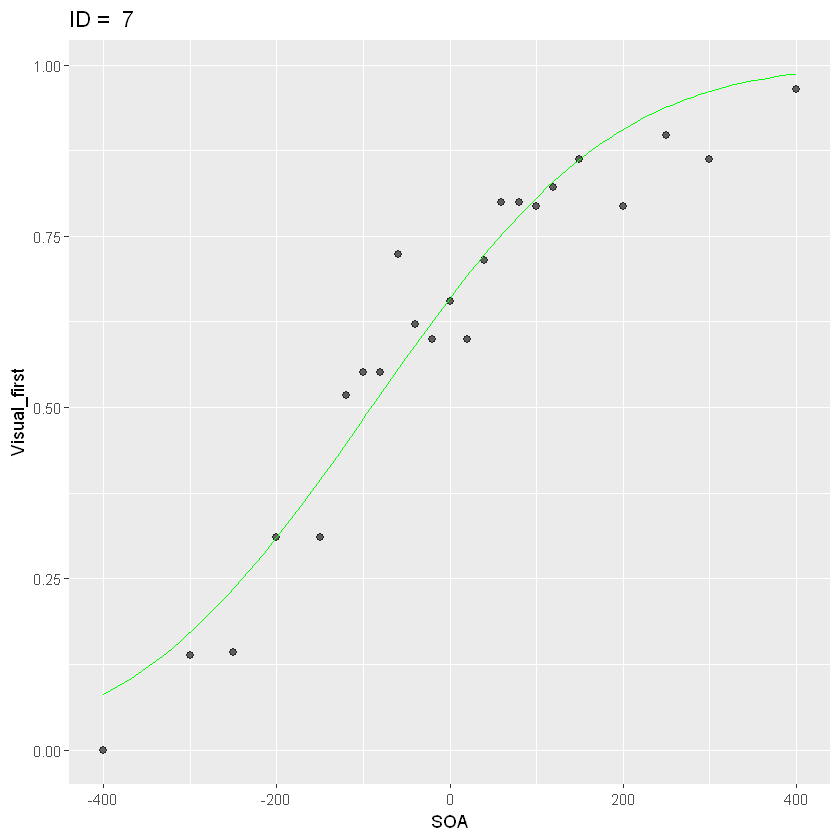

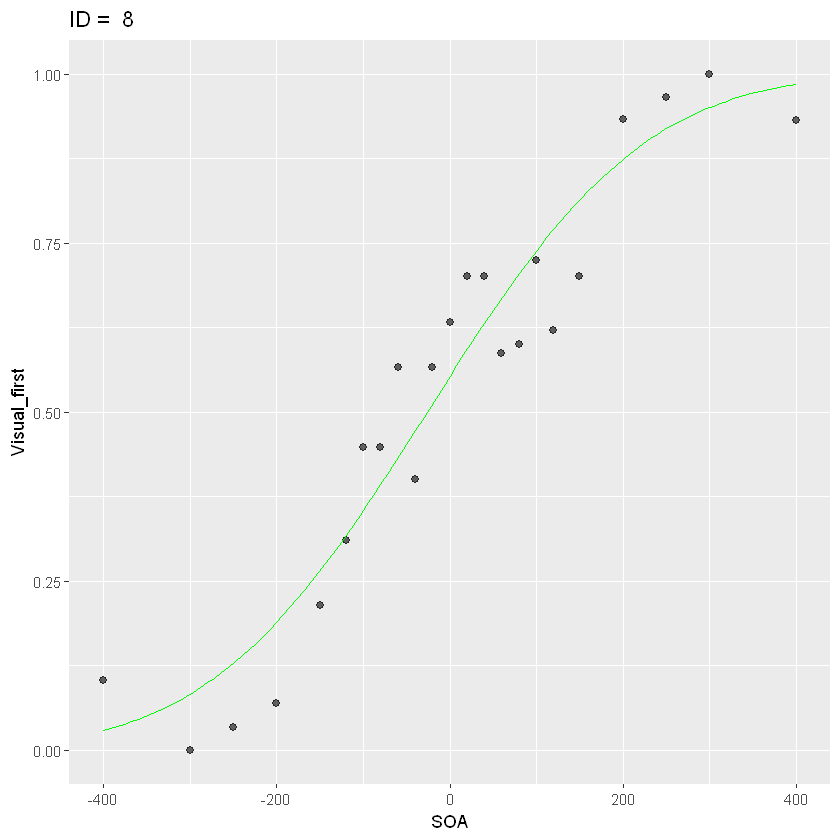

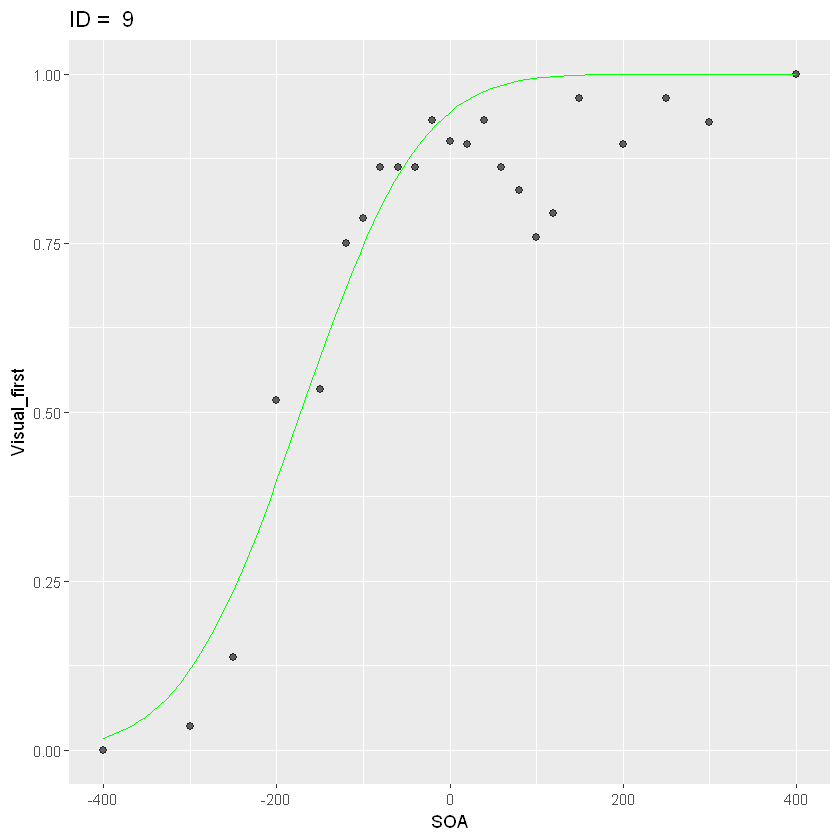

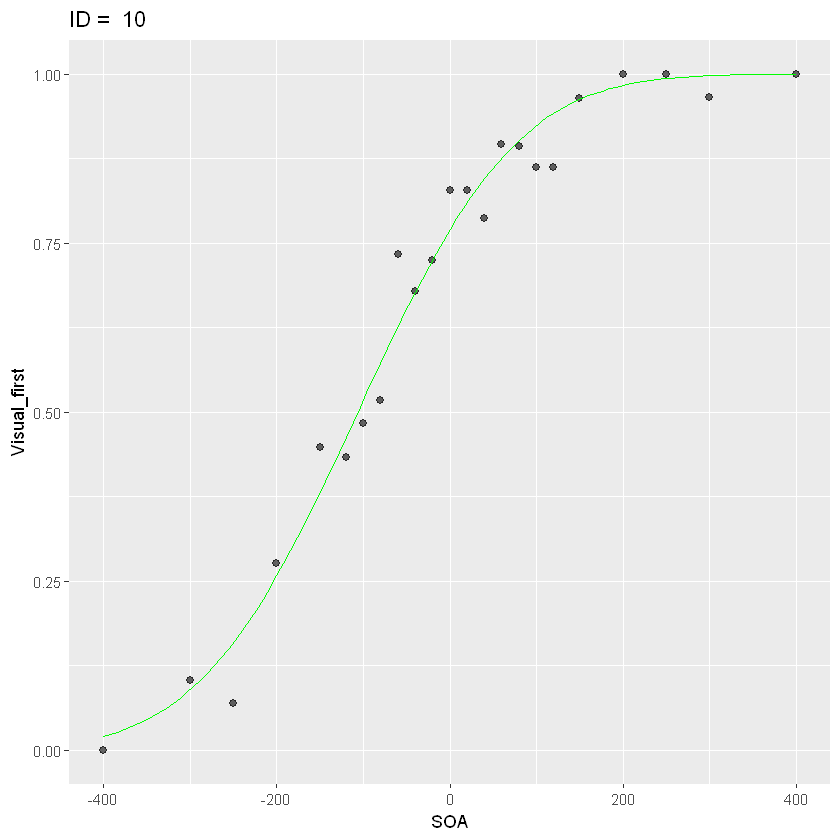

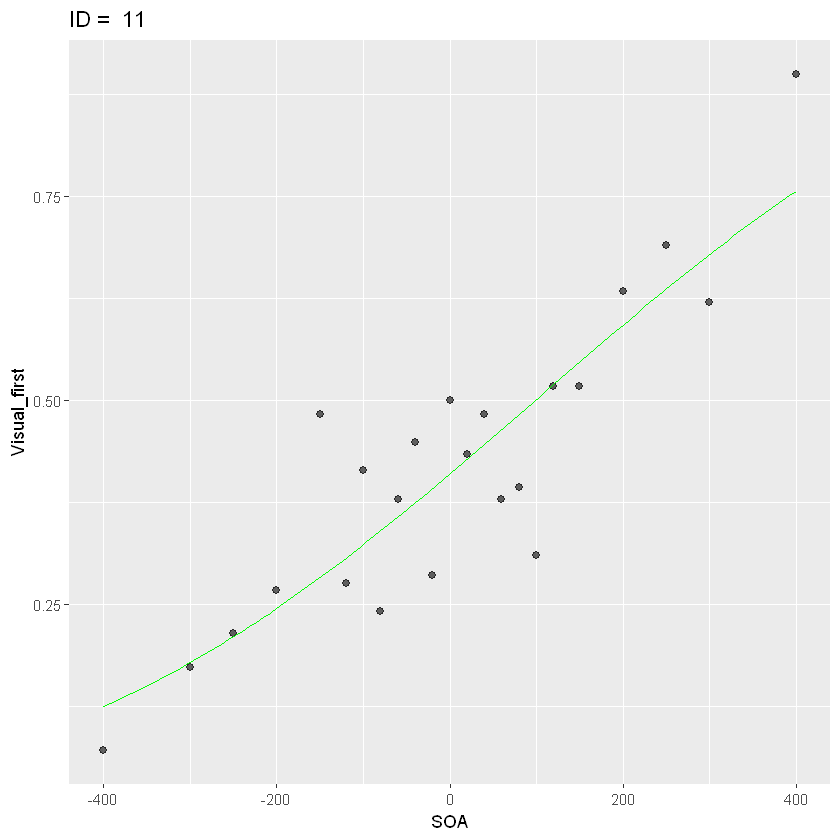

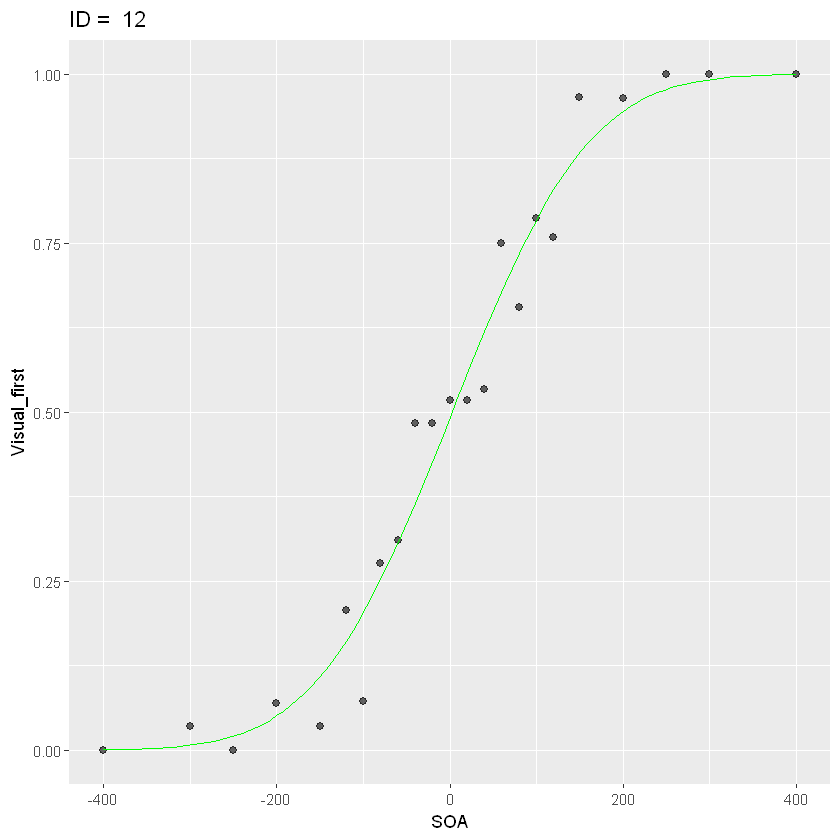

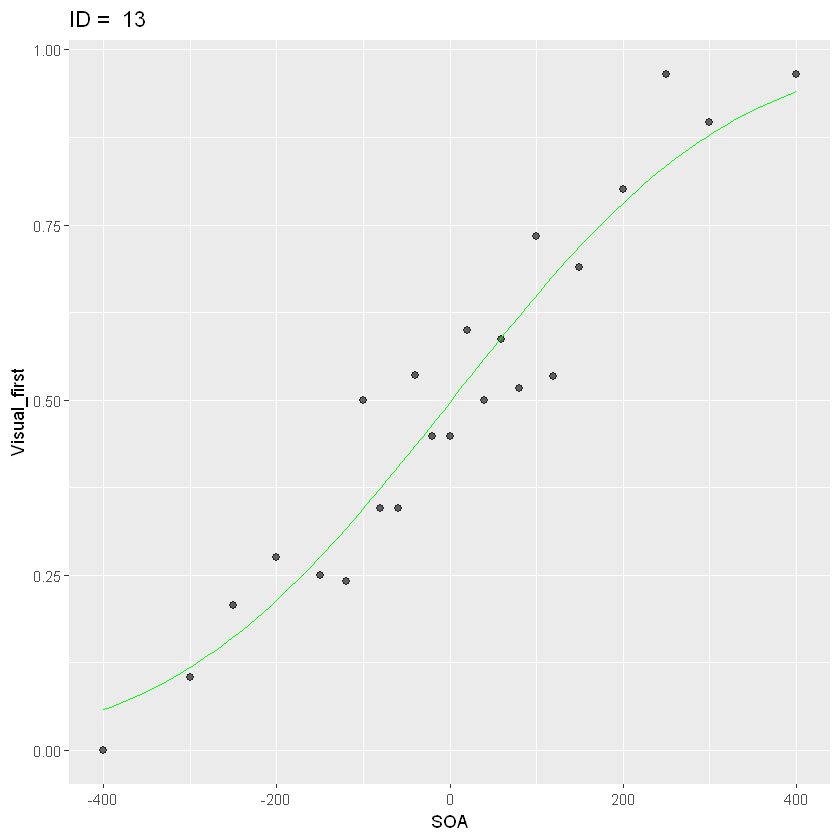

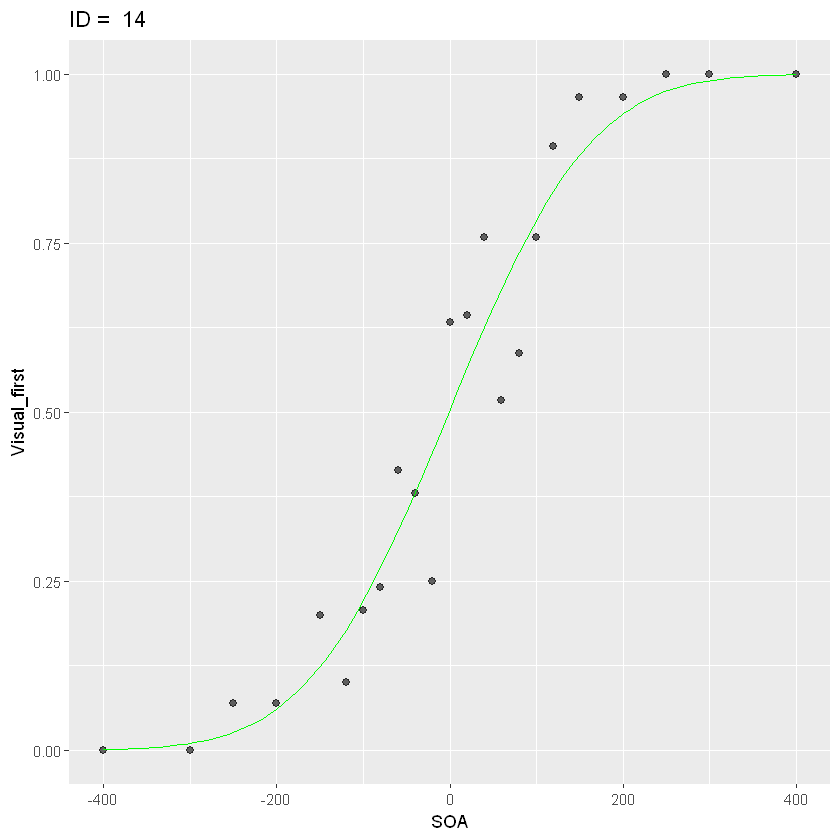

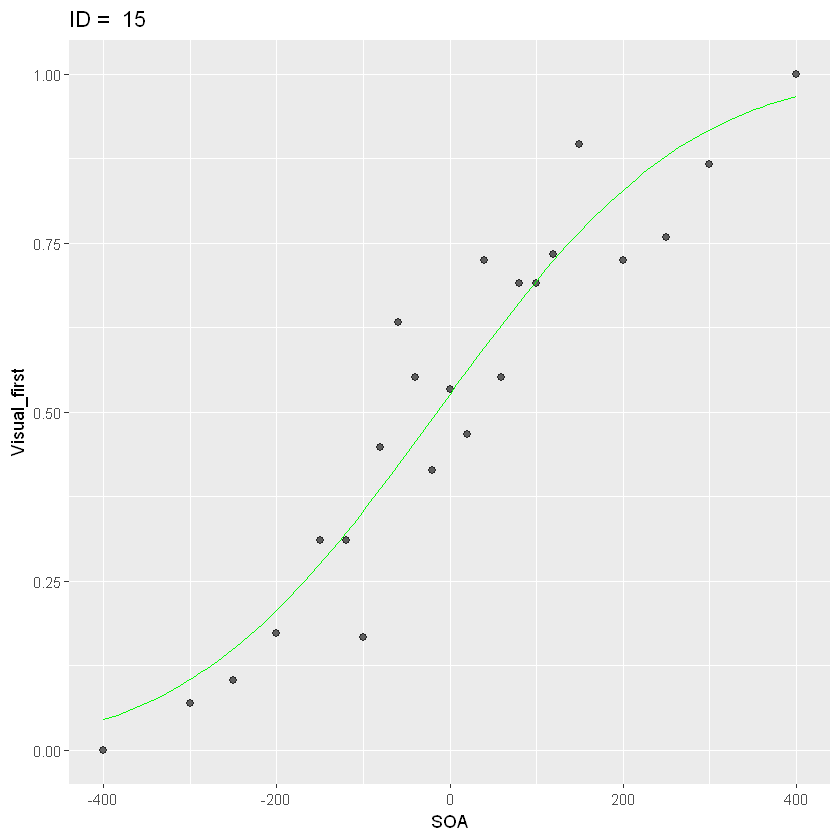

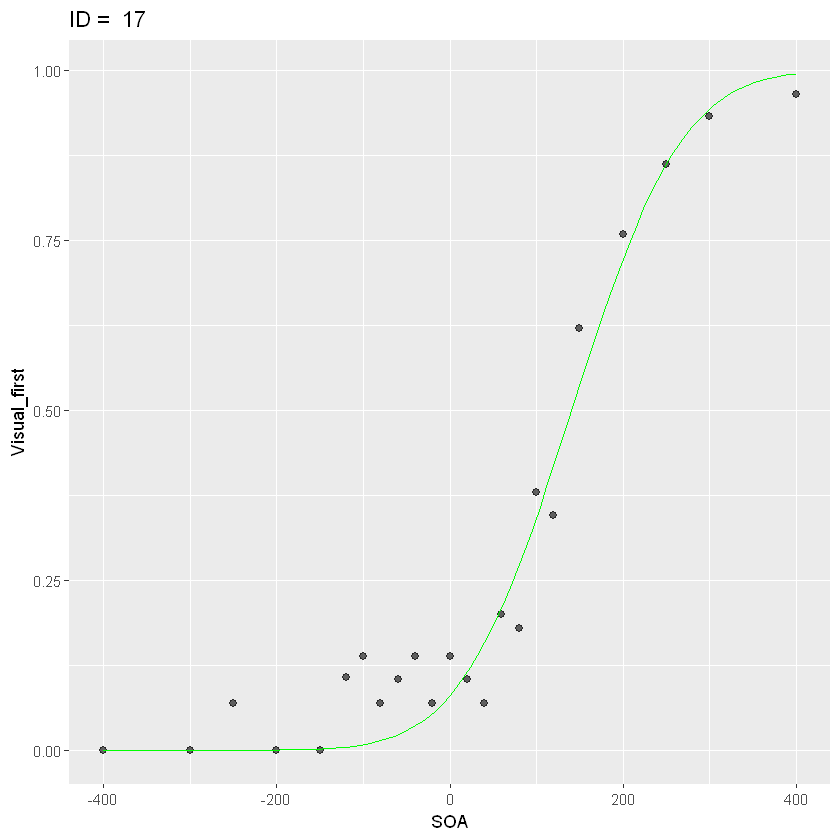

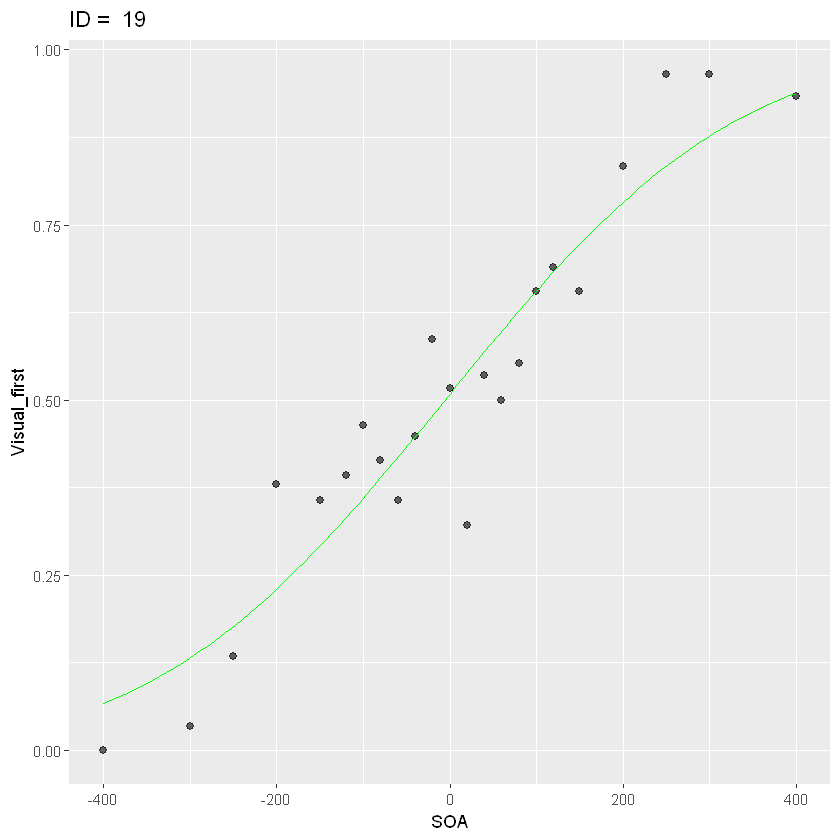

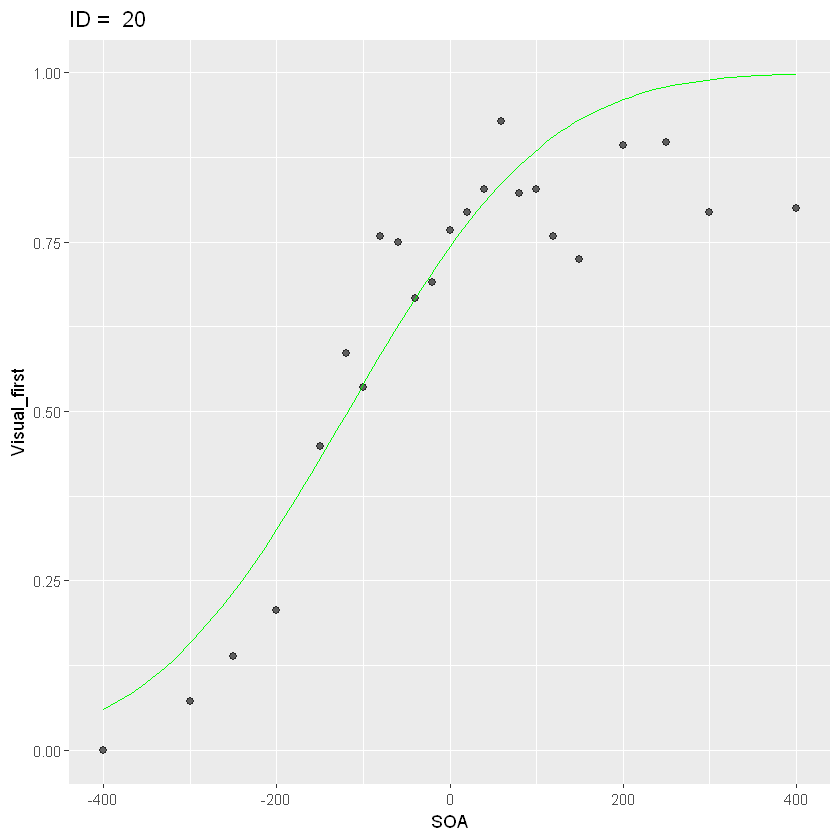

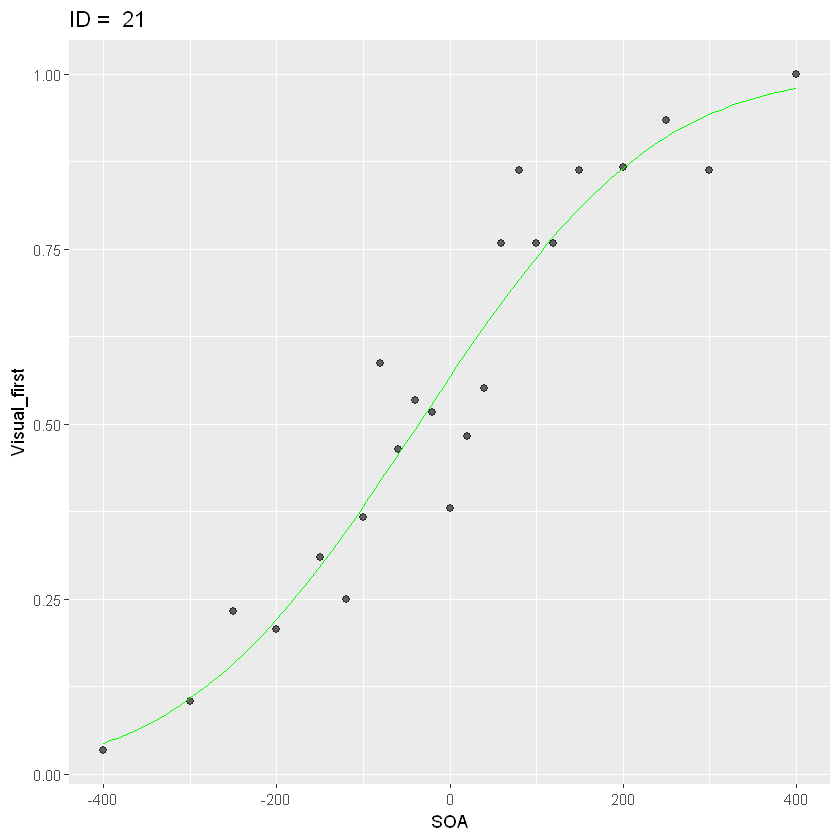

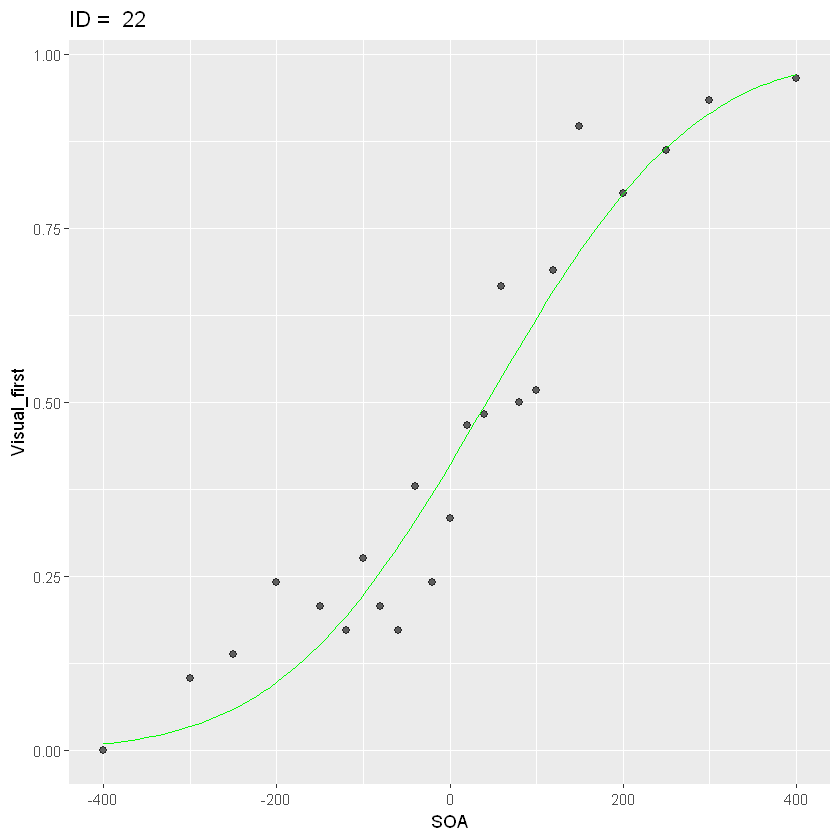

In [15]:
# plot of fits

ff <- function(x,SD,criterion){
    pnorm(x, mean = criterion, sd = SD)
}

df <- data %>% group_by(ID, SOA) %>%   
    summarise(
                Visual_first = mean(Visual_first == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(data$ID)){

    d1 <- df %>% filter(ID == subj)
        sd <- (psy_results %>% filter(ID == subj))$SD
        cri <- (psy_results %>% filter(ID == subj))$criterion
        print(ggplot(d1, aes(x = SOA, y = Visual_first)) +
                geom_point(size = 2, alpha = 0.6) +
                geom_function(fun=ff, args = list(SD = sd, criterion = cri), color='green') +
                labs(title = paste('ID = ',subj)))
            
}

In [16]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  return(1 - SS_res / SS_tot)
}

psy_results$R2 <- NA

for(i in 1:nrow(psy_results)){
  id <- psy_results$ID[i]
  subdata <- df %>% filter(ID == id)
  pred <- ff(subdata$SOA, psy_results$SD[i], psy_results$criterion[i])
  psy_results$R2[i] <- R2(subdata$Visual_first, pred)
}

head(psy_results)

,ID,SD,criterion,R2
,<dbl>,<dbl>,<dbl>,<dbl>
1,1,240.7688,-52.585879,0.8458825
2,3,213.5215,-51.164074,0.9057424
3,5,189.5935,-101.185727,0.8894951
4,6,340.3783,-7.222641,0.8343942
5,7,221.0994,-90.866481,0.9354355
6,8,197.5471,-26.256731,0.9175639


In [17]:
sort(psy_results$R2)

[1] 0.7758563 0.8343942 0.8458825 0.8468226 0.8894951 0.8902021 0.8918730
 [8] 0.8942107 0.9057424 0.9175639 0.9182453 0.9185552 0.9238809 0.9354355
[15] 0.9430291 0.9607173 0.9732165 0.9774443

## 1-4 Save Results

In [18]:
colnames(psy_results)[1] <- 'participant'

In [8]:
write_xlsx(psy_results,"files/TOJ_general_observer_parameters.xlsx")

###############################################################\
###############################################################
# 2- Serial Dependence based on Prior Stimulus
**List of contents:**\
2-1 Load data\
2-2 Fit psychometric model\
2-3 Check fits\
2-4 Plot group-level fits\
2-5 Statistical test of SD\
2-6 Statistical test of criterion

###############################################################
## 2-1 Load data

In [19]:
###############################################################
# Load TOJ serial dependence dataset
###############################################################

data <- read_xlsx("files/TOJ_prior_stimulus_data.xlsx")
head(data)

participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,auditory_leading,-400,a,1.537577
1,auditory_leading,-400,a,1.454046
1,auditory_leading,-400,a,1.503926
1,auditory_leading,-400,a,1.504481
1,auditory_leading,-400,a,1.069864
1,auditory_leading,-400,a,1.638146


In [20]:
###############################################################
# Prepare behavioral variables
###############################################################

data <- data %>%
  rename(
    ID = 1,
    Visual_first = 4,
    prior_stimulus = 2
  ) %>%
  mutate(
    Visual_first = ifelse(Visual_first == "v", 1, 0),
  )
head(data)

ID,prior_stimulus,SOA,Visual_first,rt
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-400,0,1.537577
1,auditory_leading,-400,0,1.454046
1,auditory_leading,-400,0,1.503926
1,auditory_leading,-400,0,1.504481
1,auditory_leading,-400,0,1.069864
1,auditory_leading,-400,0,1.638146


###############################################################
## 2-2 Fit psychometric model

In [21]:
# model:
# P(visual first) = Φ(SOA | mean=criterion, sd=SD)

model <- function(data){
  loss_function <- function(params){
    SD <- params[1]
    criterion <- params[2]
    predicted <-  pnorm(data$SOA, mean = criterion, sd = SD)
    sum((predicted - data$Visual_first)^2)
  }

  DEoptim(
    loss_function,
    lower = c(.001, -500),
    upper = c(1000, 500)
  )
}

model_results <- data.frame()

for(subj in unique(data$ID)){
    d1 <- data %>% filter(ID == subj)
    for(ps in unique(data$prior_stimulus)){
        d2 <- d1 %>% filter(prior_stimulus == ps)
        fit <- model(d2)$optim$bestmem
        model_results <- rbind(
            model_results,
            data.frame(
              ID = subj,
              prior_stimulus = ps,
              SD = fit[1],
              criterion = fit[2]
    )
  )
}}

rownames(model_results) <- NULL

Iteration: 1 bestvalit: 50.968384 bestmemit:  332.272296   45.519511
Iteration: 2 bestvalit: 49.674314 bestmemit:  273.173503    6.671755
Iteration: 3 bestvalit: 49.674314 bestmemit:  273.173503    6.671755
Iteration: 4 bestvalit: 49.674314 bestmemit:  273.173503    6.671755
Iteration: 5 bestvalit: 49.674314 bestmemit:  273.173503    6.671755
Iteration: 6 bestvalit: 49.572717 bestmemit:  249.905344  -14.641436
Iteration: 7 bestvalit: 49.572717 bestmemit:  249.905344  -14.641436
Iteration: 8 bestvalit: 49.572717 bestmemit:  249.905344  -14.641436
Iteration: 9 bestvalit: 49.572717 bestmemit:  249.905344  -14.641436
Iteration: 10 bestvalit: 49.572717 bestmemit:  249.905344  -14.641436
Iteration: 11 bestvalit: 49.572717 bestmemit:  249.905344  -14.641436
Iteration: 12 bestvalit: 49.566662 bestmemit:  258.836696   -0.244102
Iteration: 13 bestvalit: 49.566662 bestmemit:  258.836696   -0.244102
Iteration: 14 bestvalit: 49.548843 bestmemit:  251.791150   -1.510726
Iteration: 15 bestvalit: 49.5

In [22]:
head(model_results)

,ID,prior_stimulus,SD,criterion
,<dbl>,<chr>,<dbl>,<dbl>
1,1,auditory_leading,247.7728,-5.969773
2,1,visual_leading,223.0294,-50.496364
3,3,auditory_leading,247.8573,-72.150489
4,3,visual_leading,214.2533,-43.846748
5,5,auditory_leading,170.8916,-96.650679
6,5,visual_leading,200.5958,-104.856409


###############################################################
## 2-3 Check fits

In [23]:
# check if the data is complete
nrow(model_results)

[1] 36

In [24]:
# check if the parameter range in fitting is appropriate
sort(model_results$SD)
sort(model_results$criterion)

[1]  61.09162  81.03301 105.16322 105.20099 120.86371 122.98874 123.30015
 [8] 124.19715 133.03873 156.01888 170.89164 172.30020 177.94546 181.91089
[15] 186.83785 200.28615 200.59580 206.15543 214.25327 216.31023 219.49462
[22] 221.58756 223.02936 226.24890 227.83732 232.57999 236.73257 242.21240
[29] 247.77283 247.85732 270.19869 275.26662 353.06105 440.53293 449.55614
[36] 459.51432

[1] -169.120181 -169.053502 -130.805320 -129.557200 -127.084679 -104.856409
 [7]  -96.650679  -94.865311  -88.952828  -82.221733  -80.521432  -72.150489
[13]  -54.305399  -50.496364  -43.846748  -43.488015  -36.046672  -30.973359
[19]  -29.976340  -24.951976  -15.931495  -15.499223   -9.194006   -6.084655
[25]   -5.969773   19.633001   19.716203   20.258870   24.663259   25.339749
[31]   40.034706   64.703122   77.957470  140.854966  148.560667  199.829809

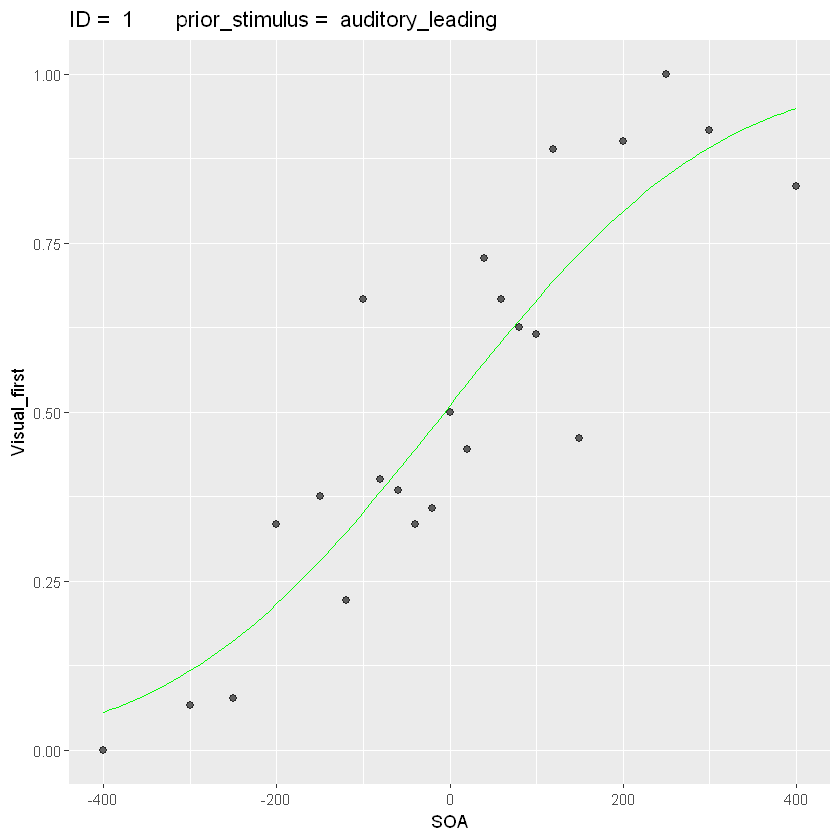

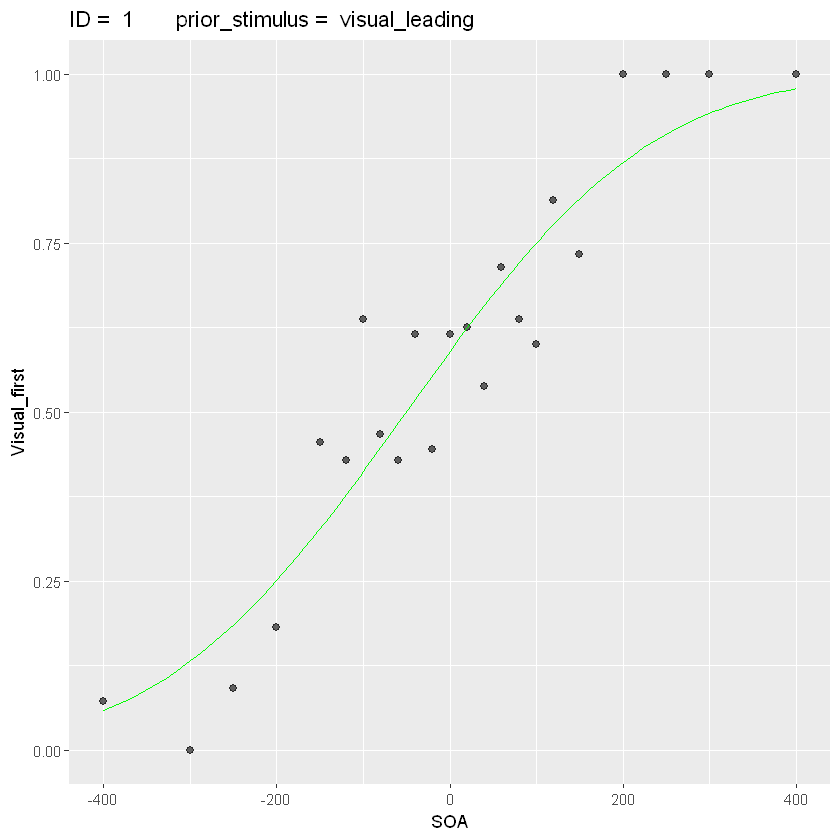

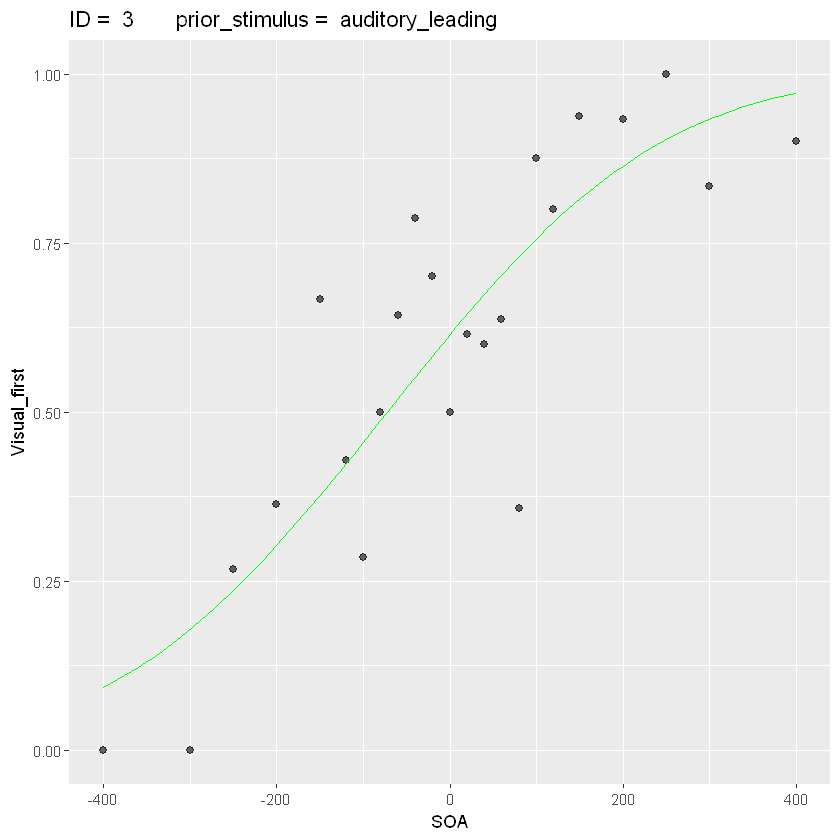

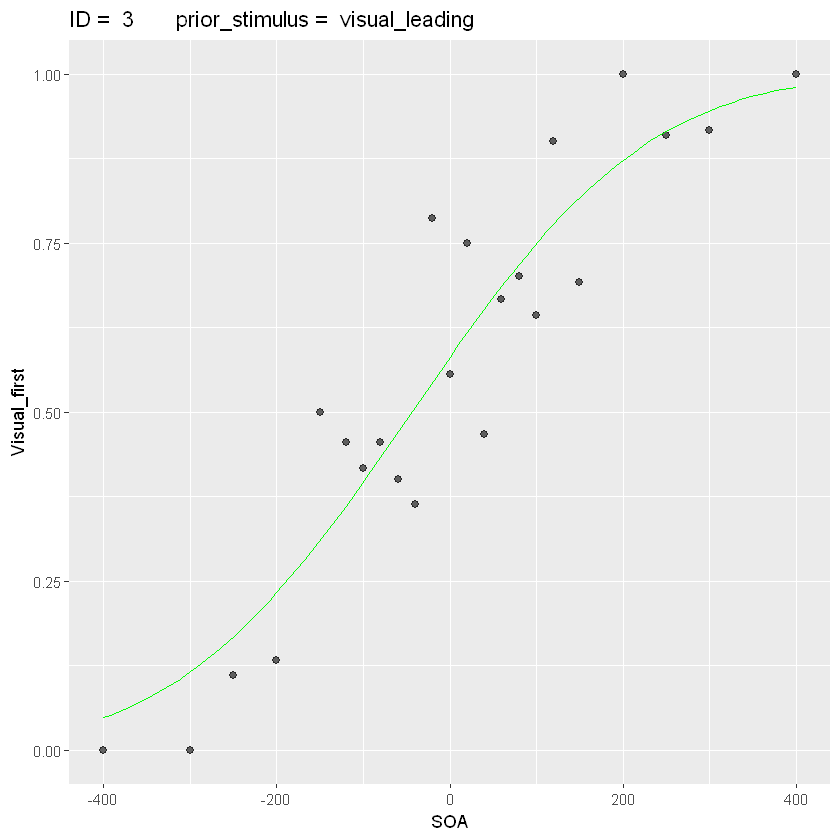

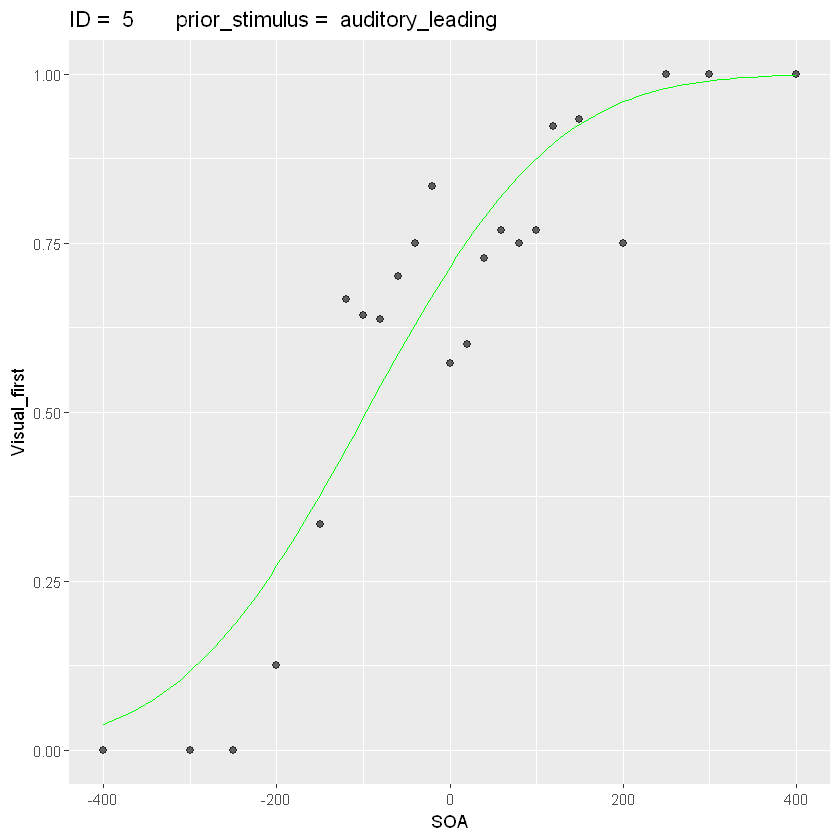

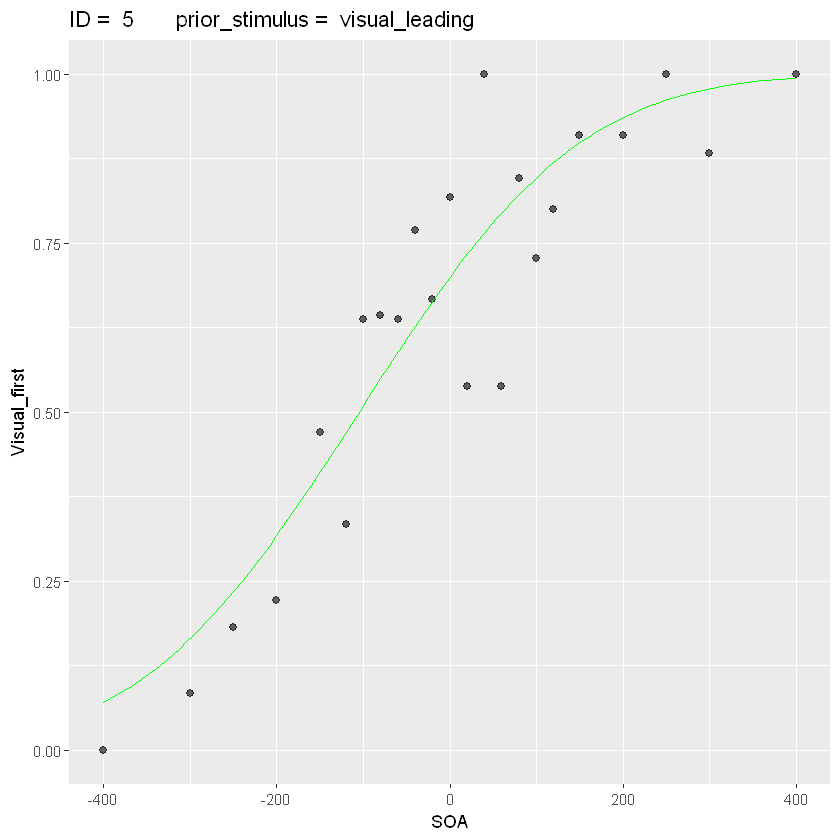

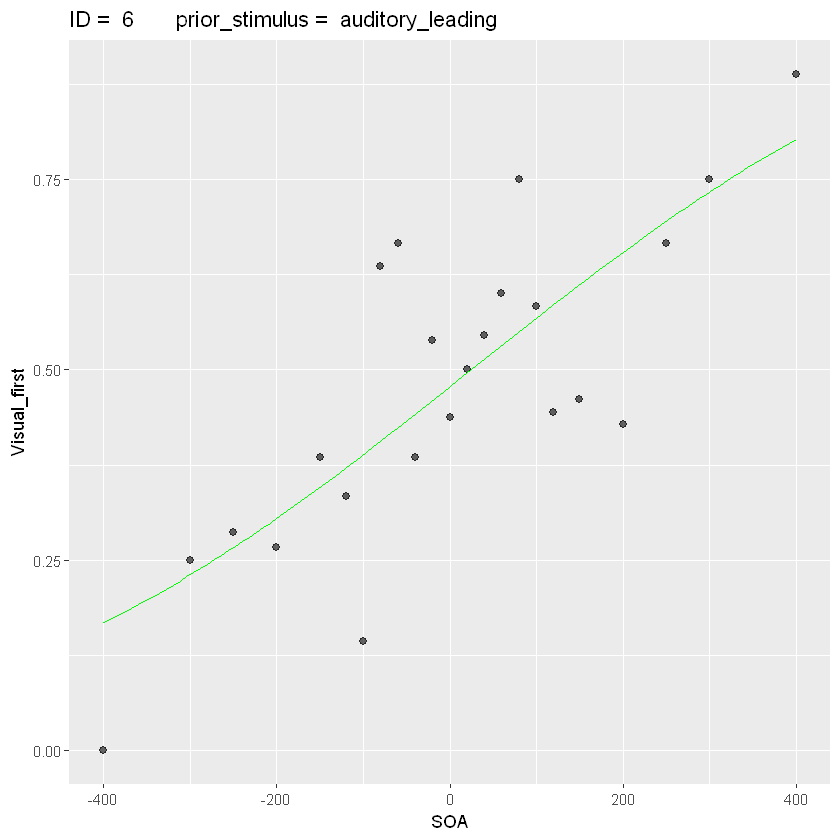

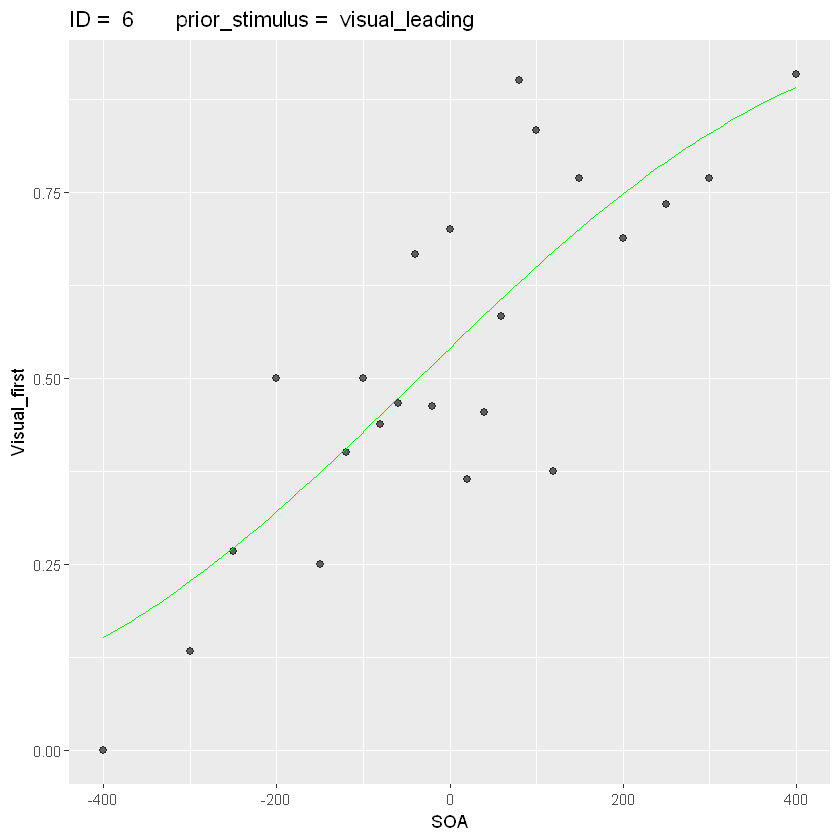

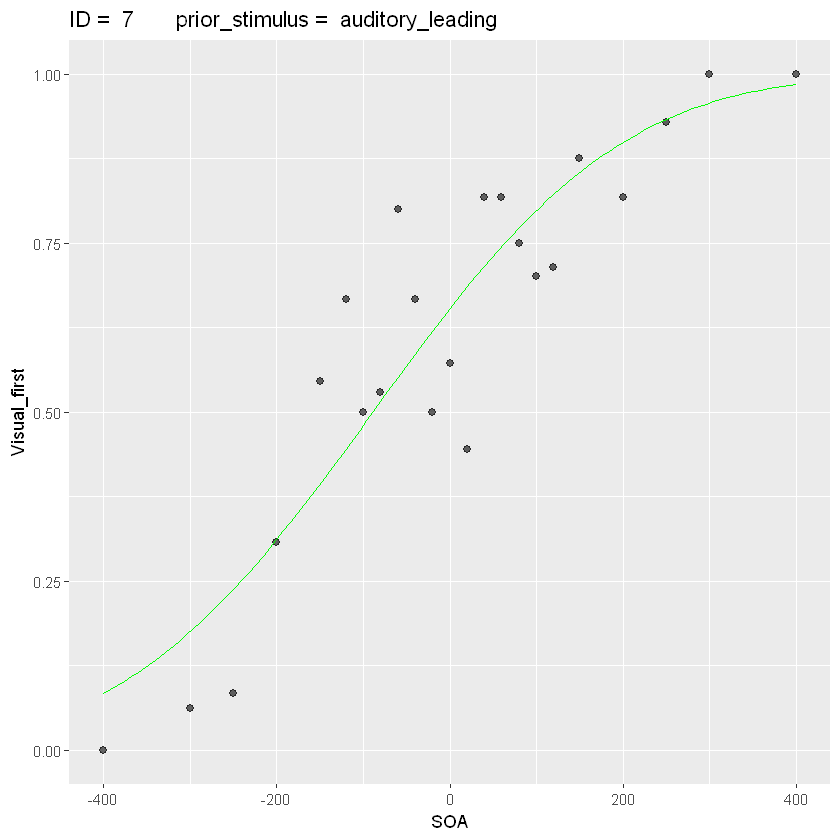

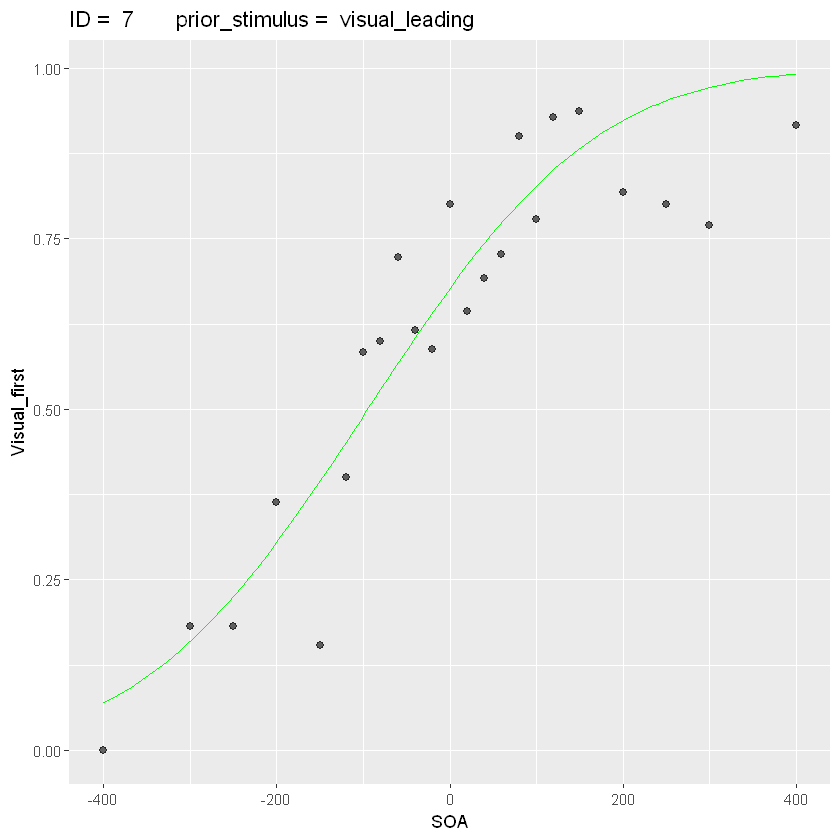

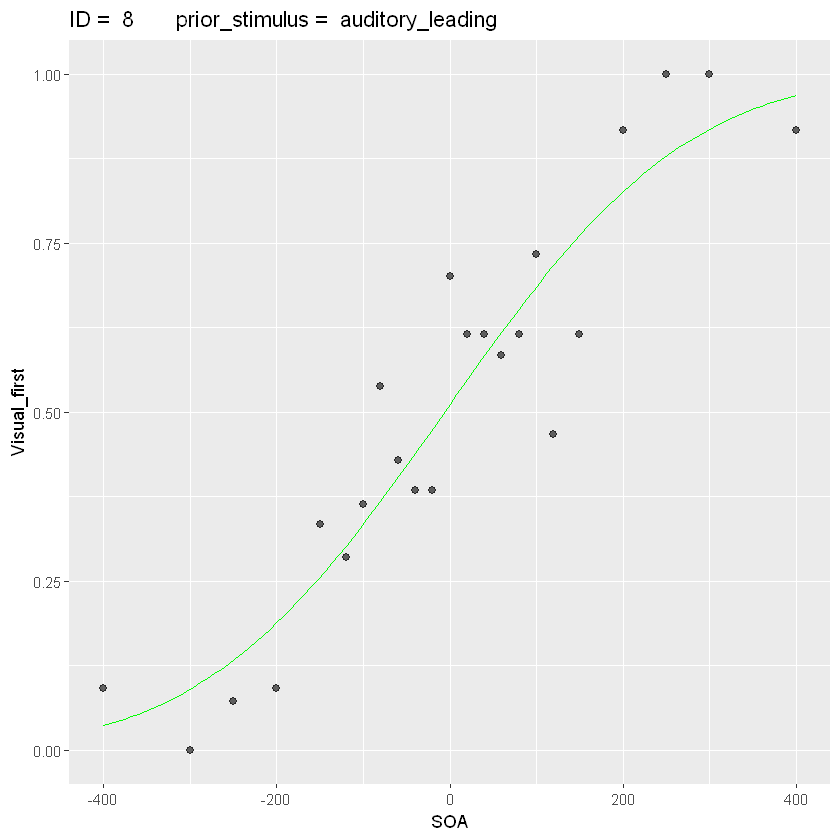

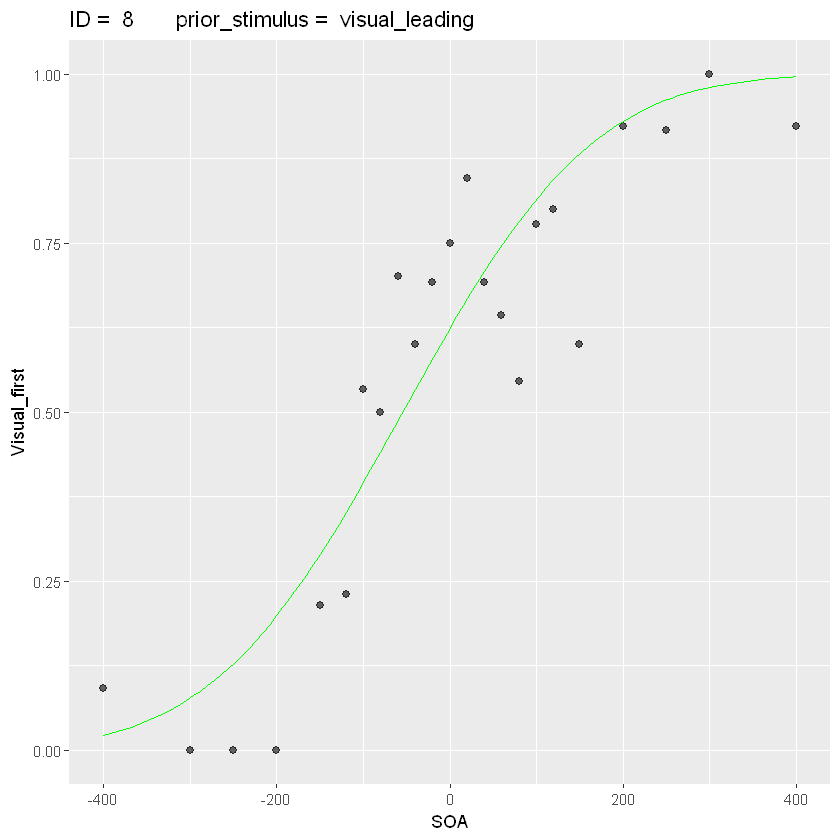

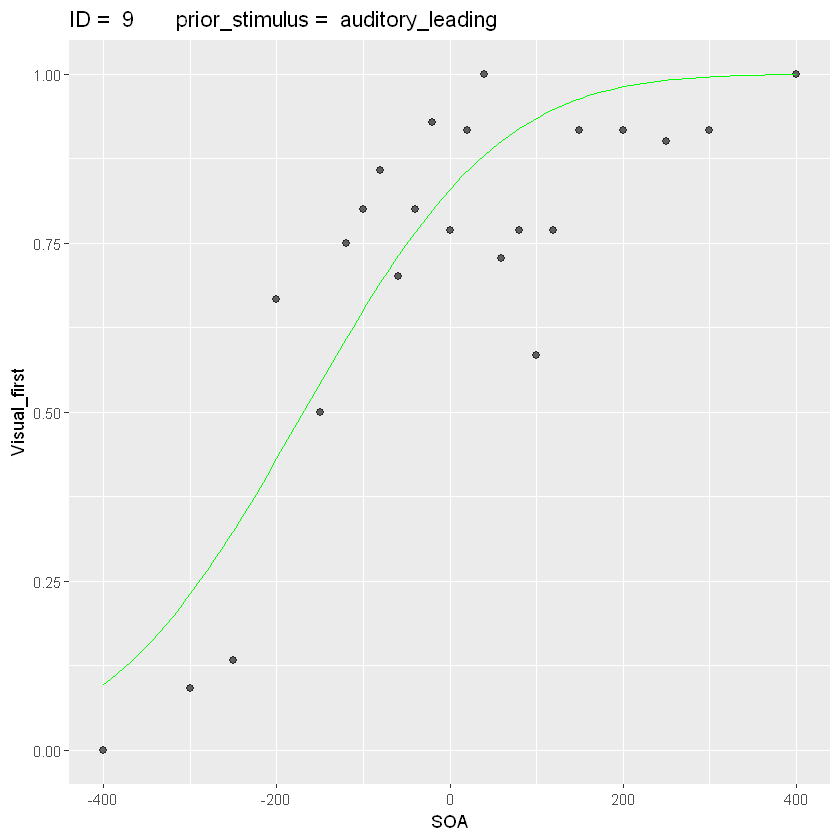

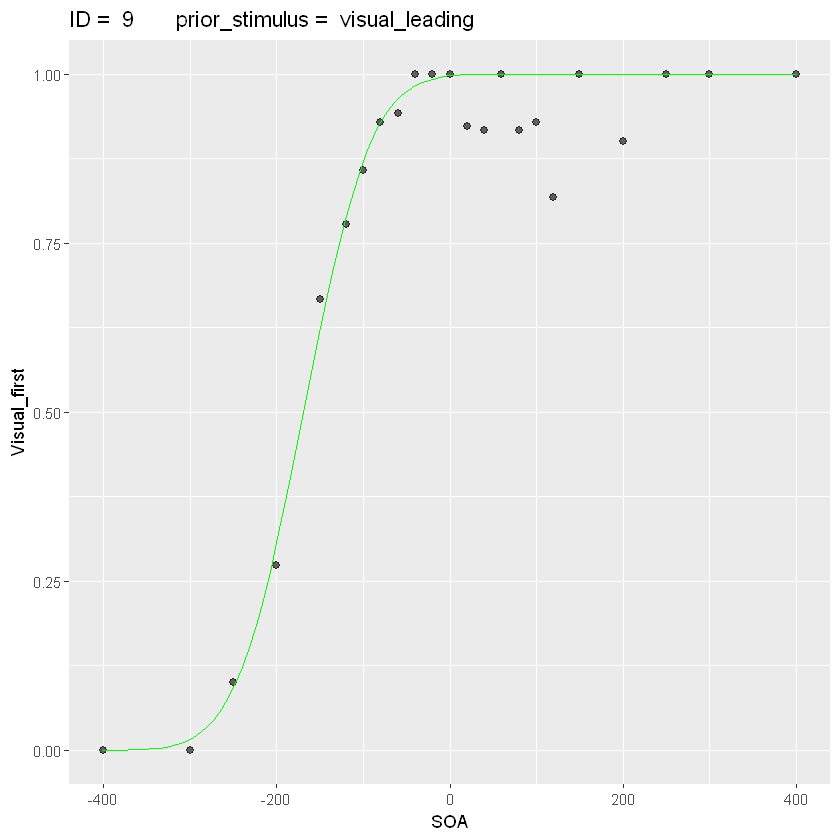

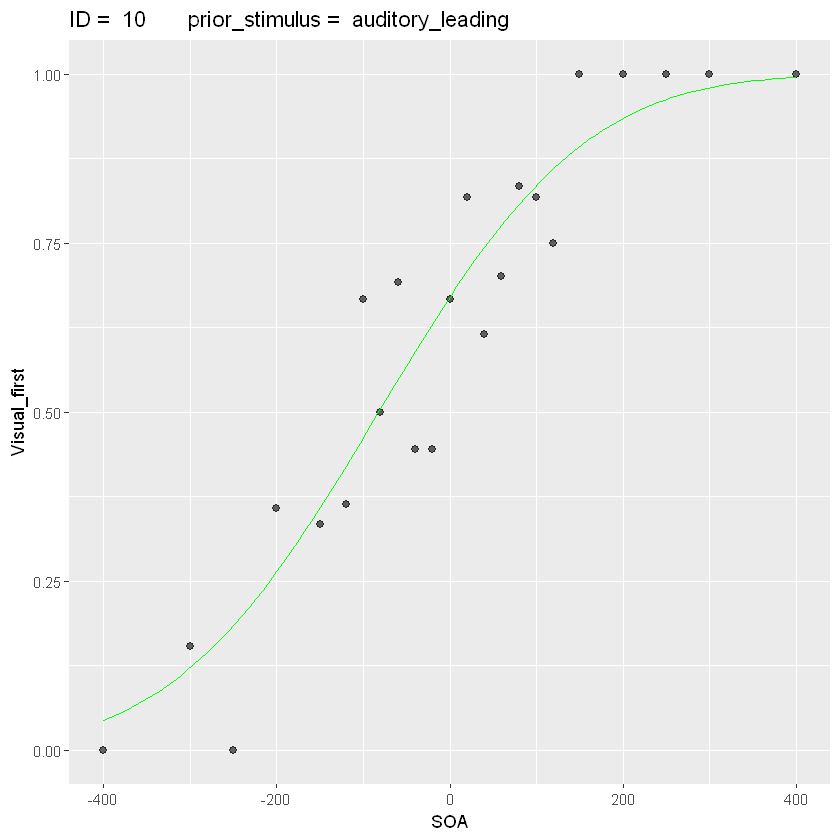

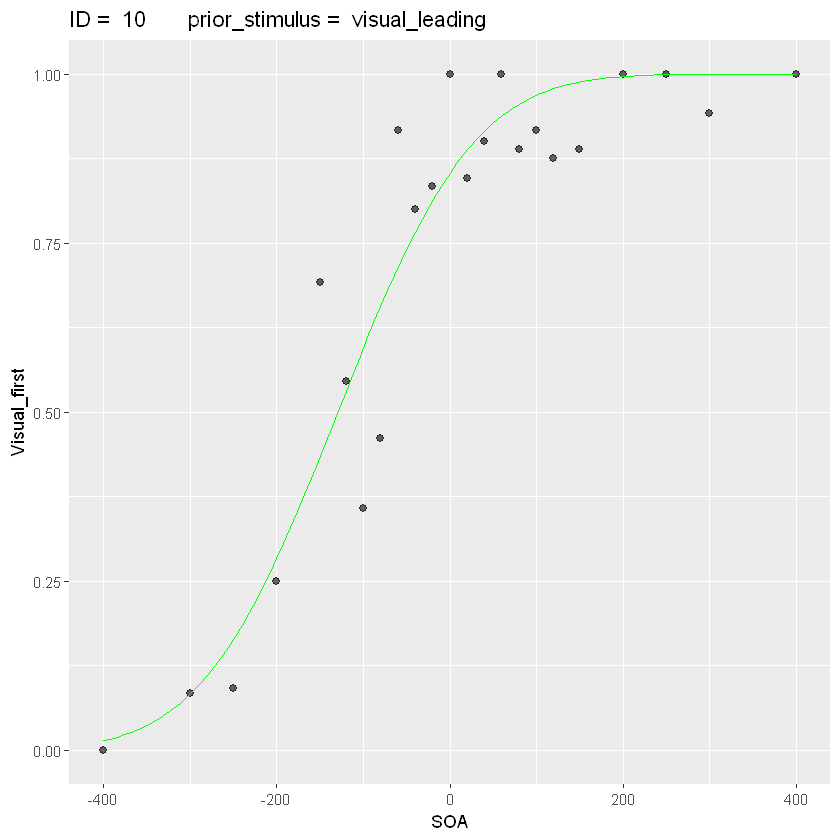

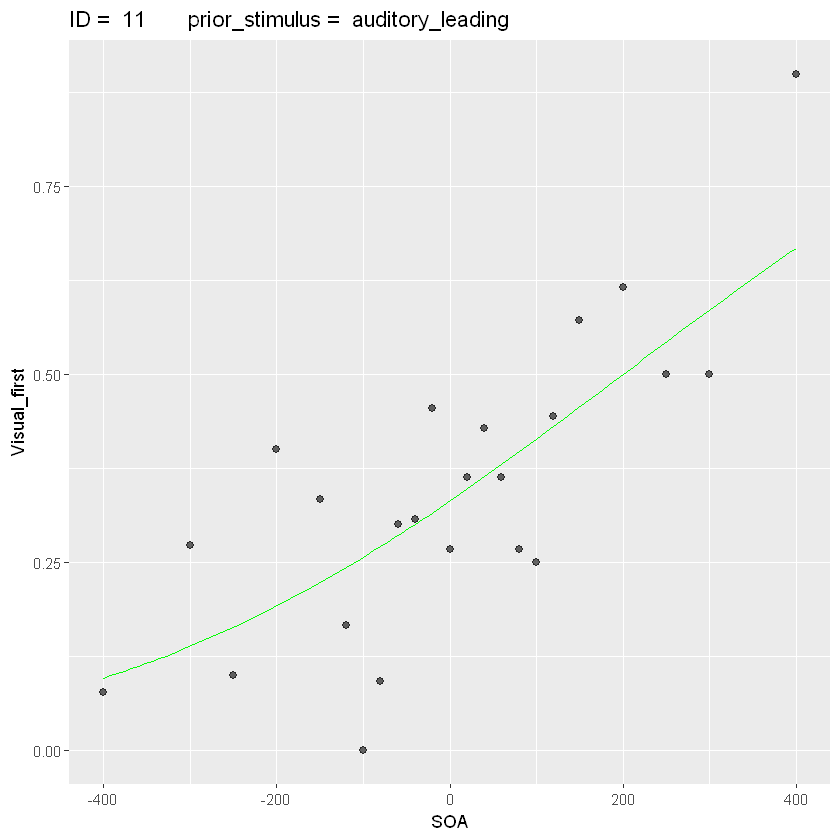

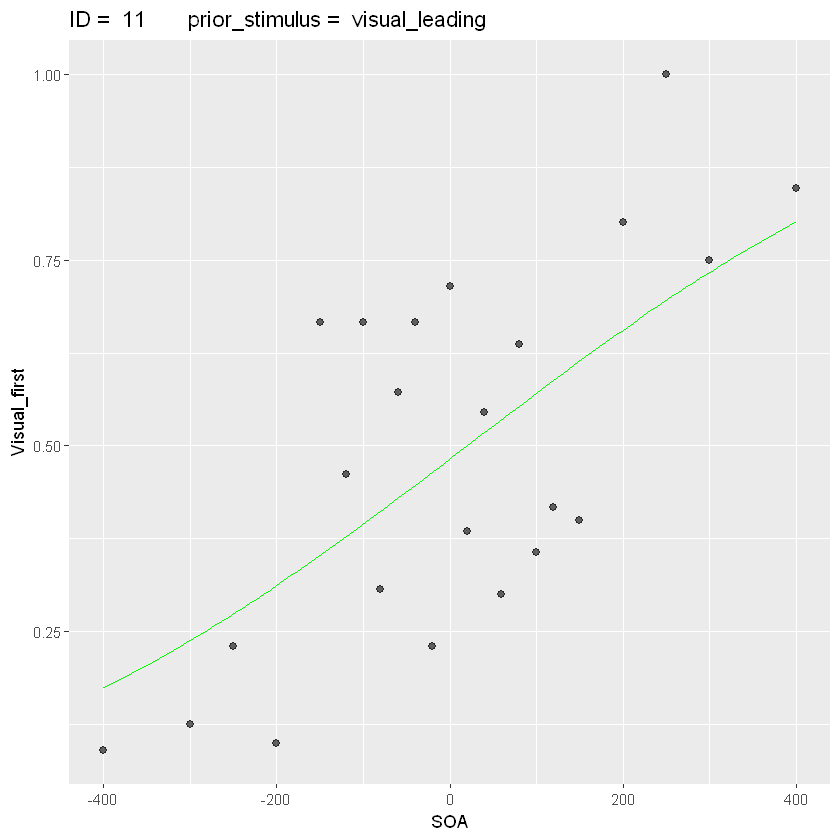

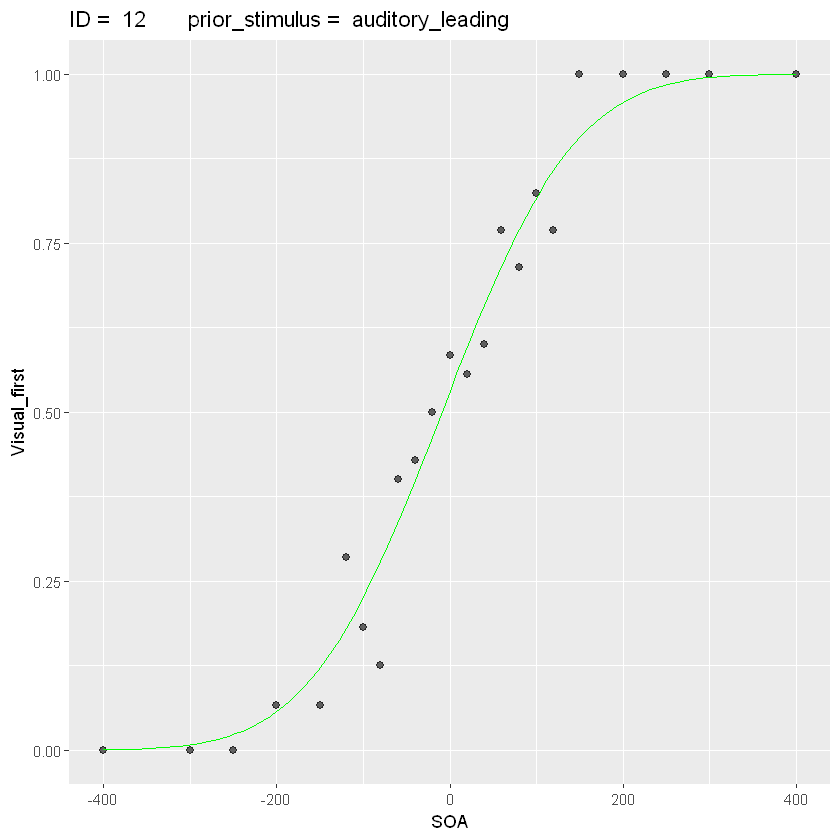

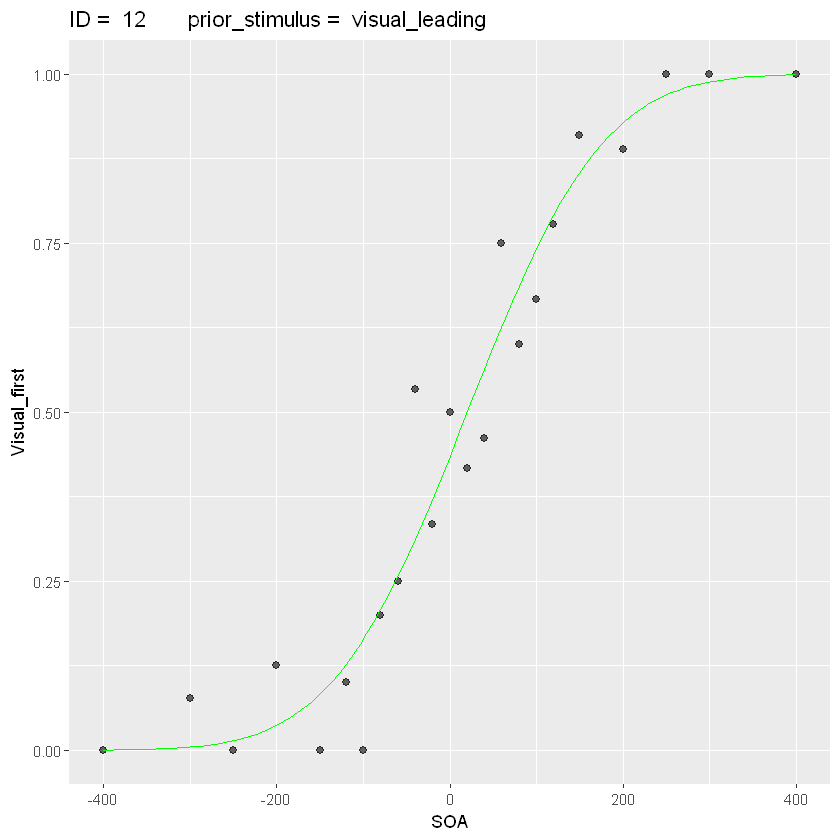

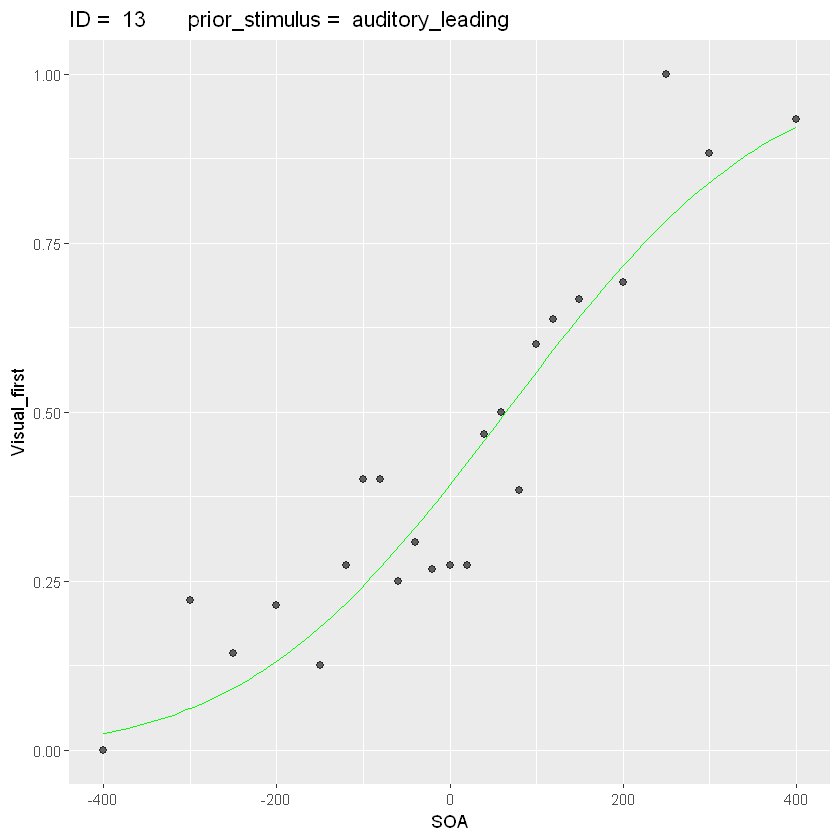

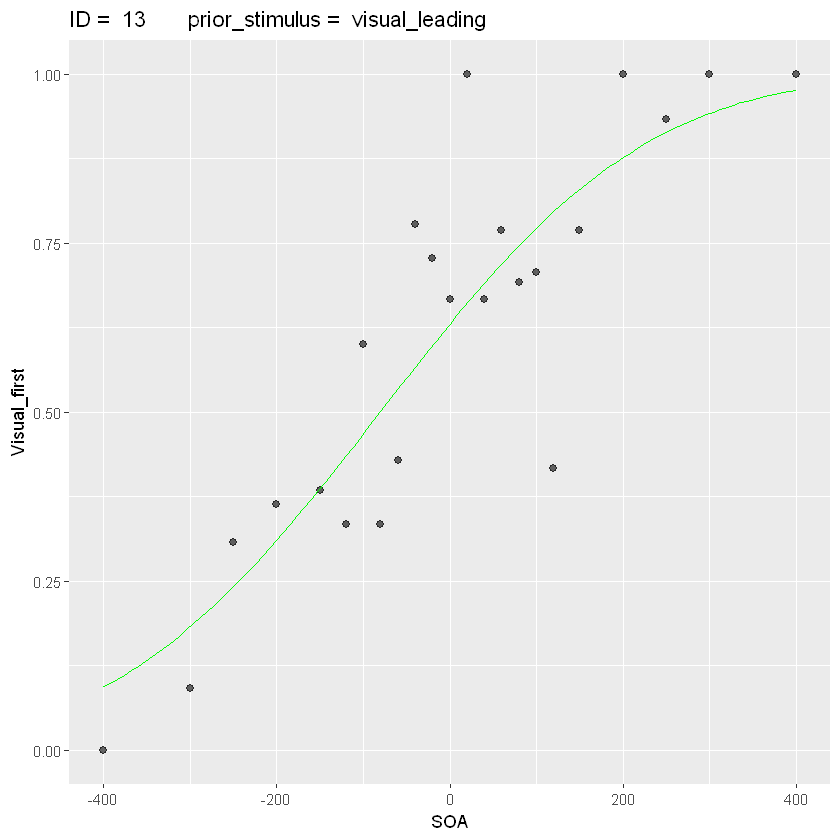

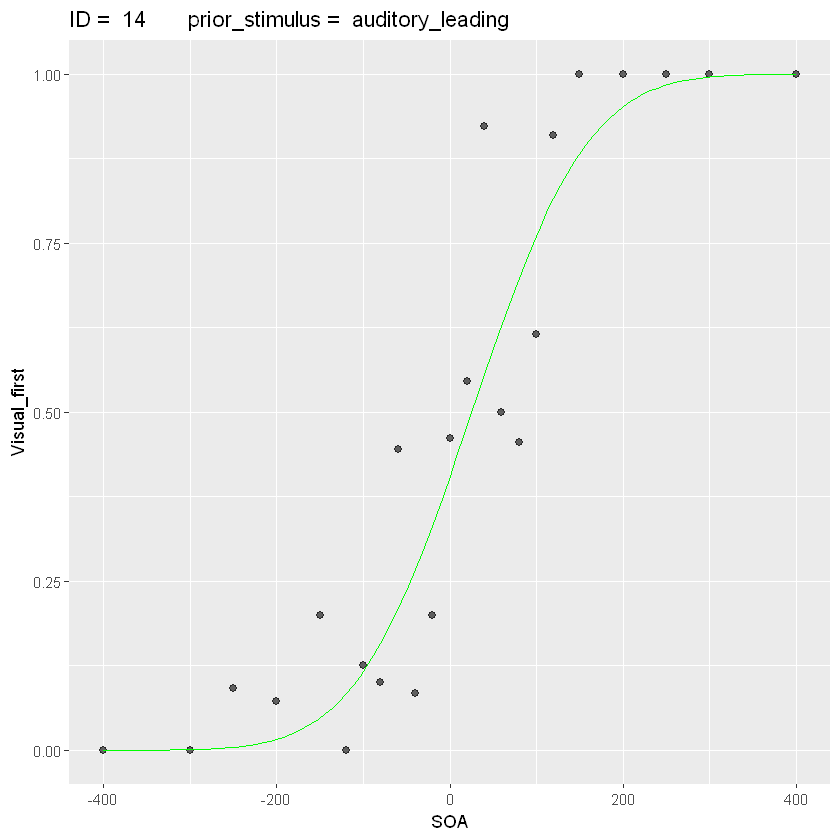

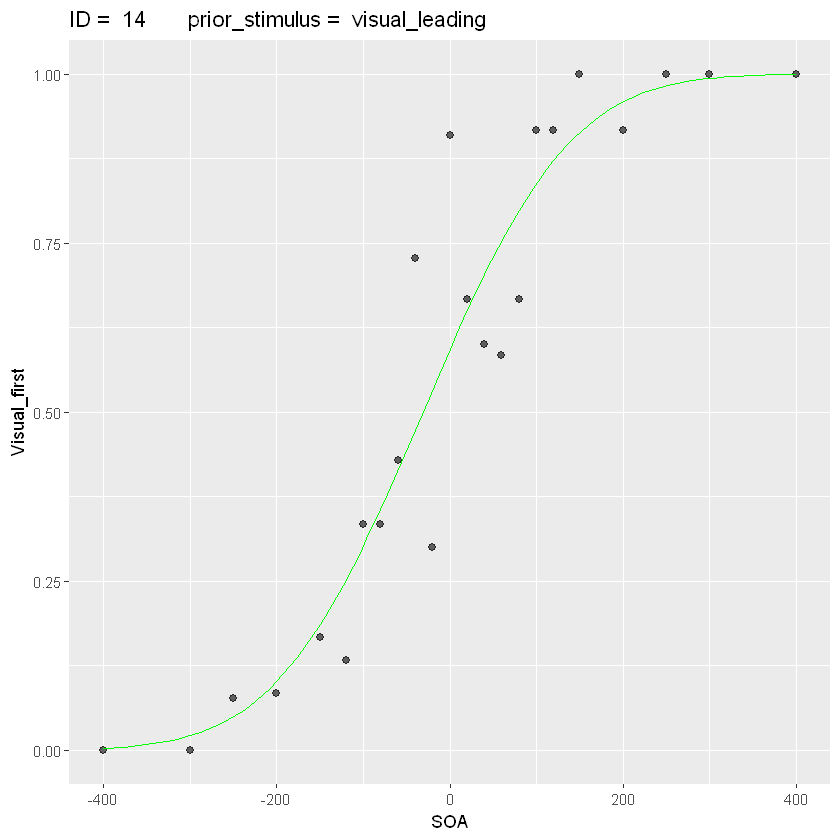

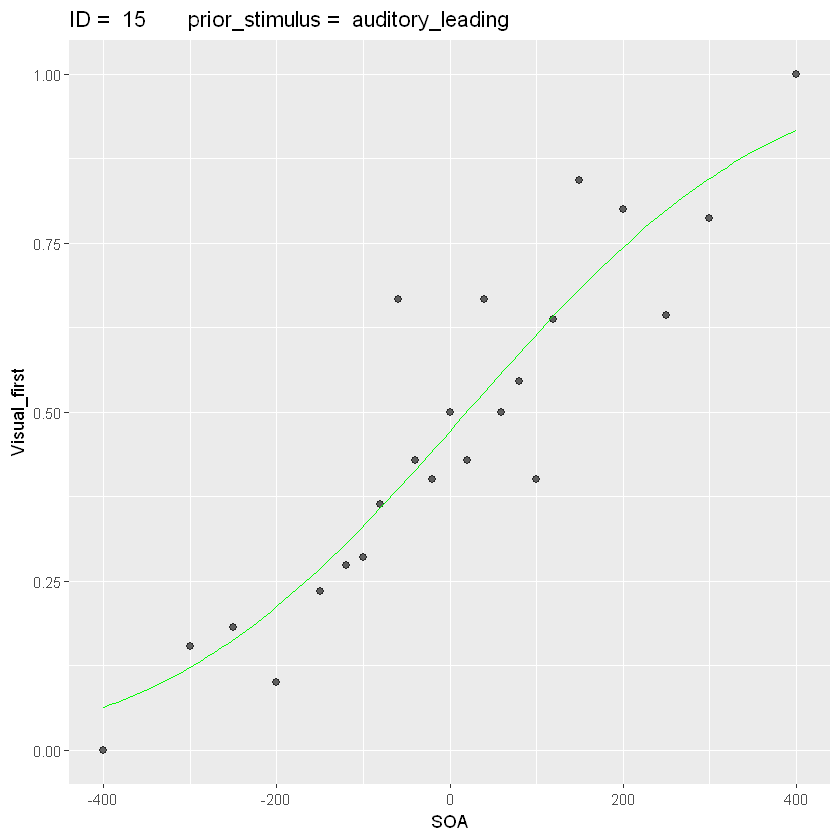

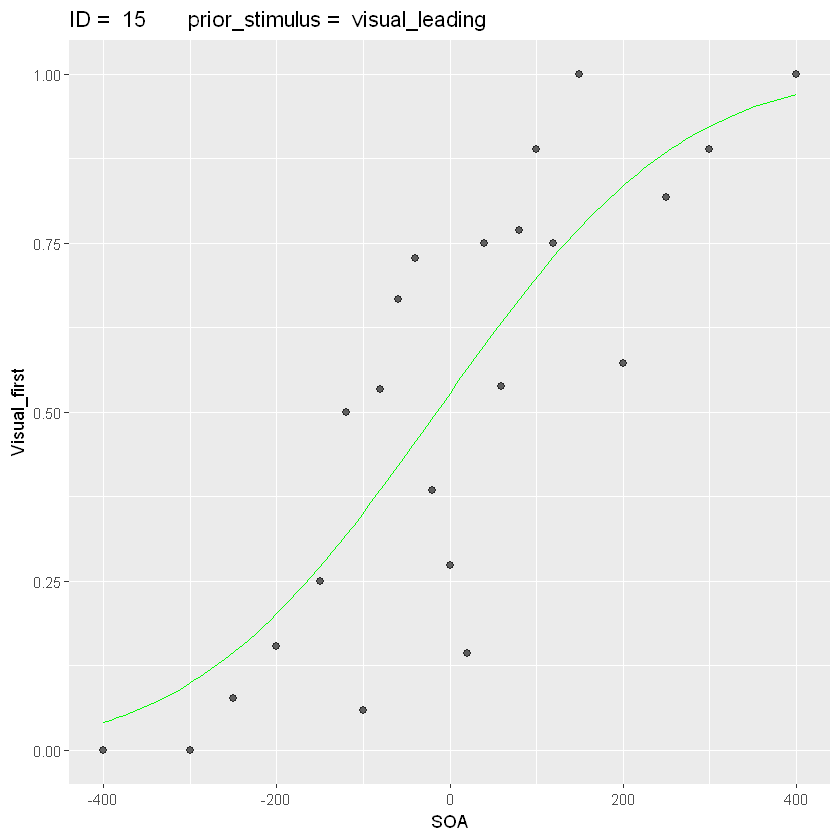

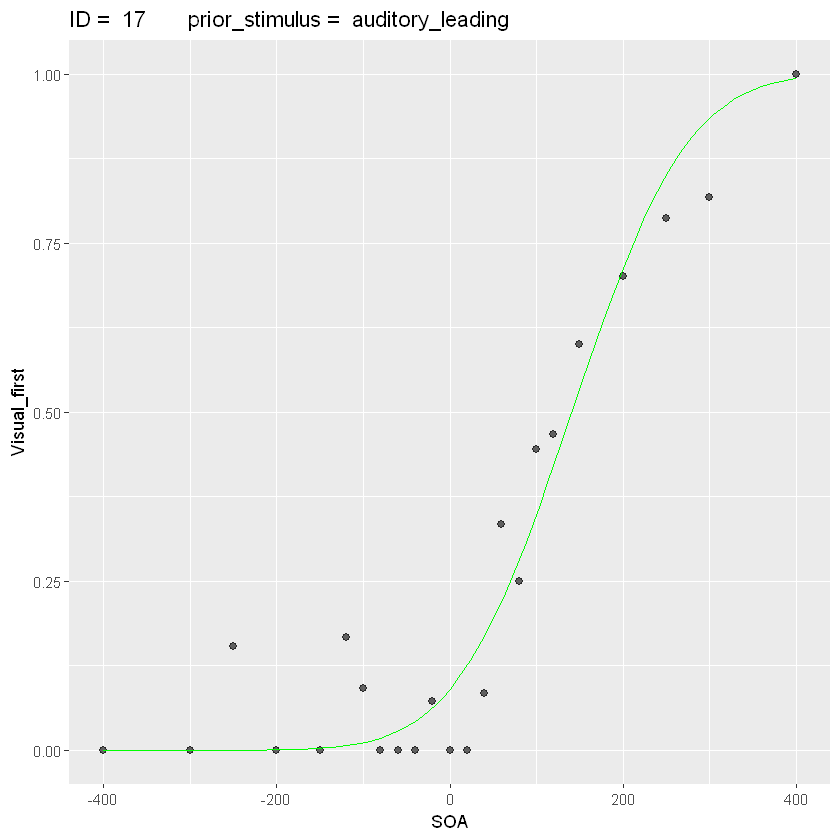

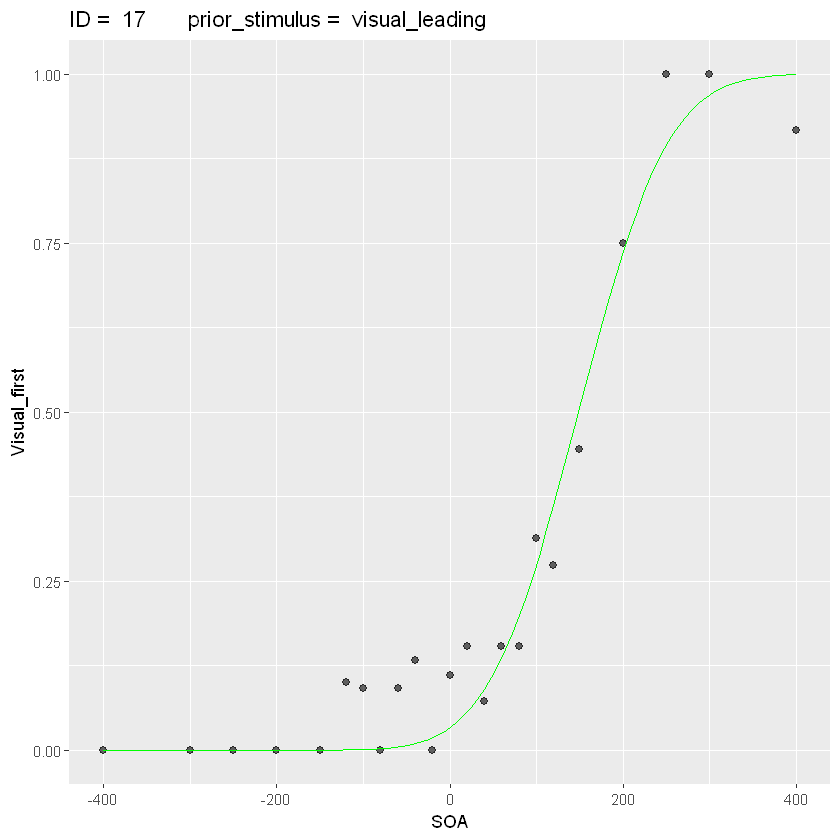

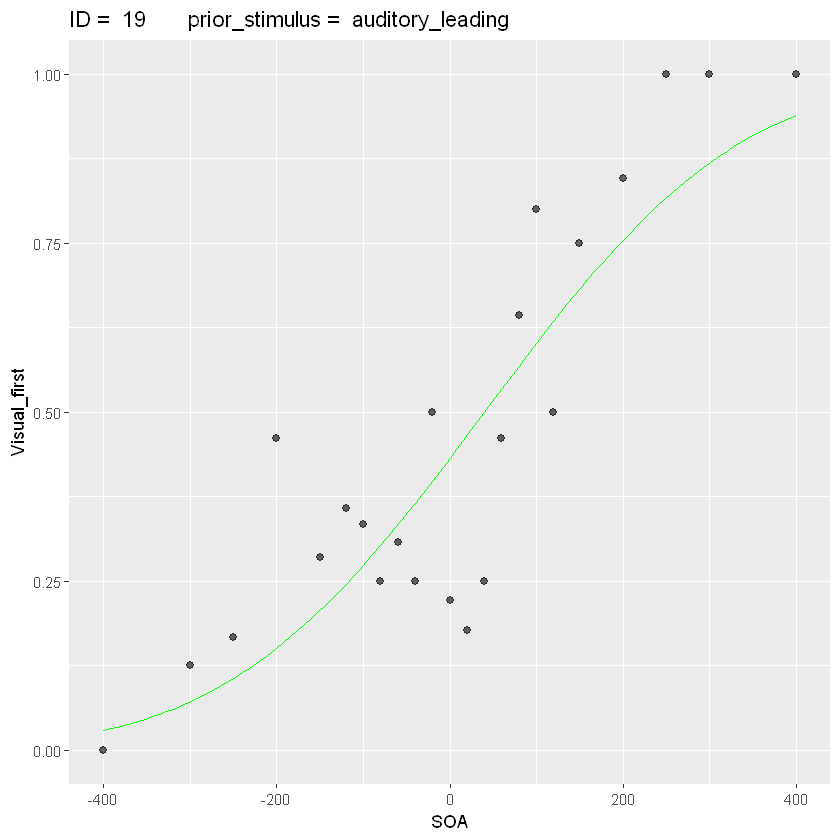

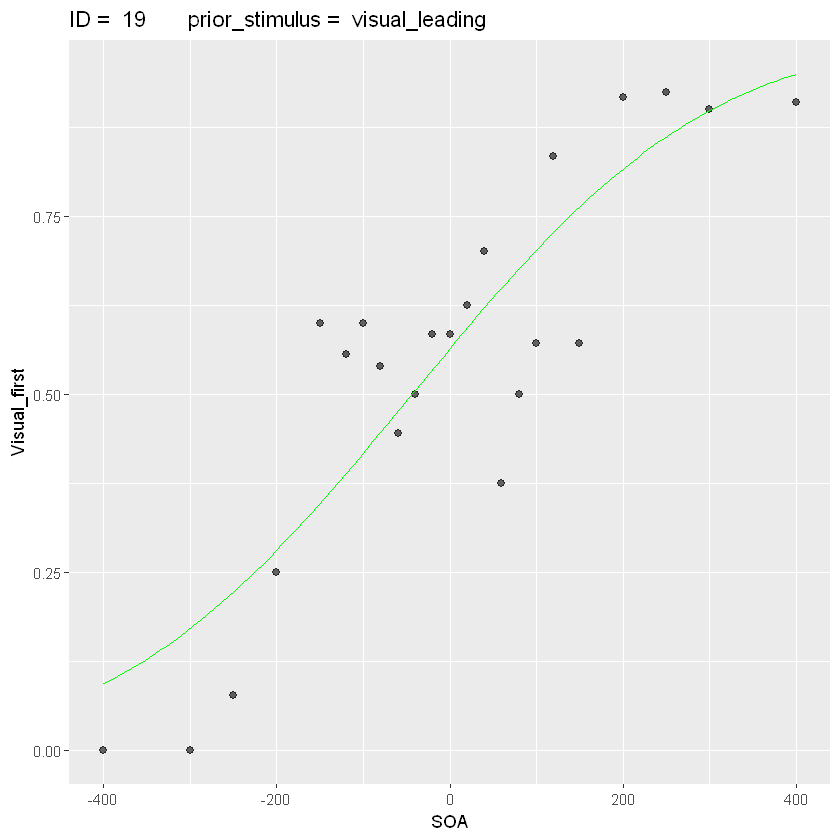

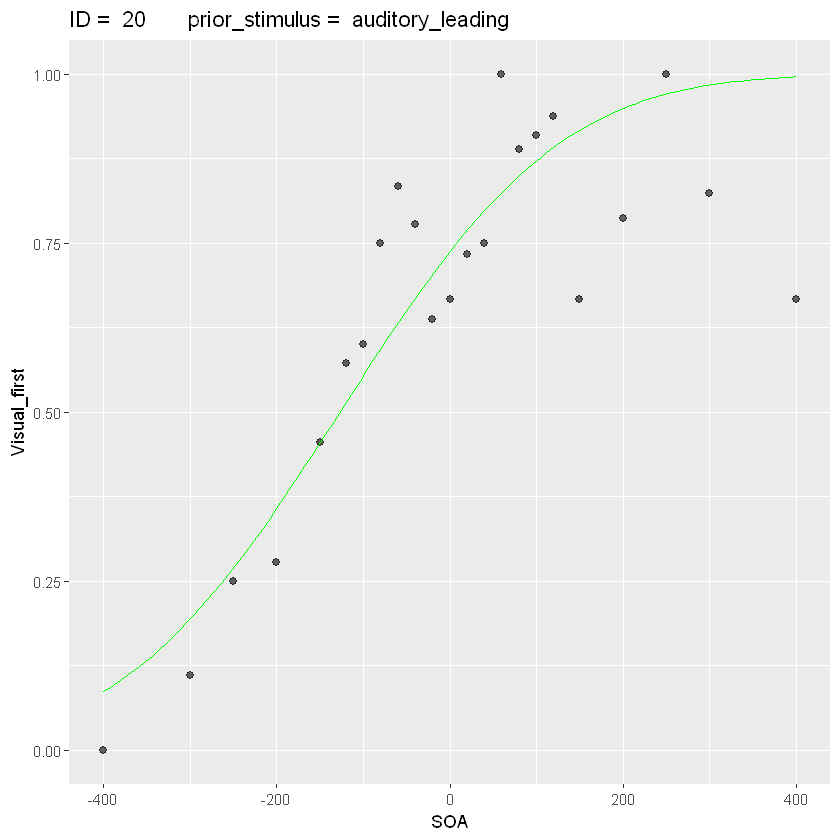

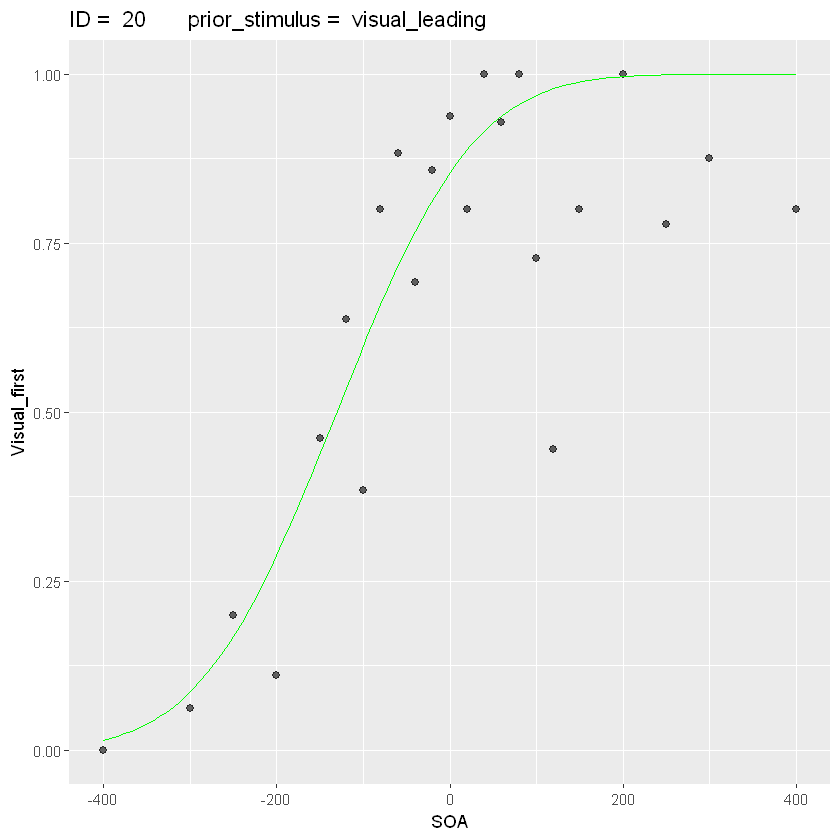

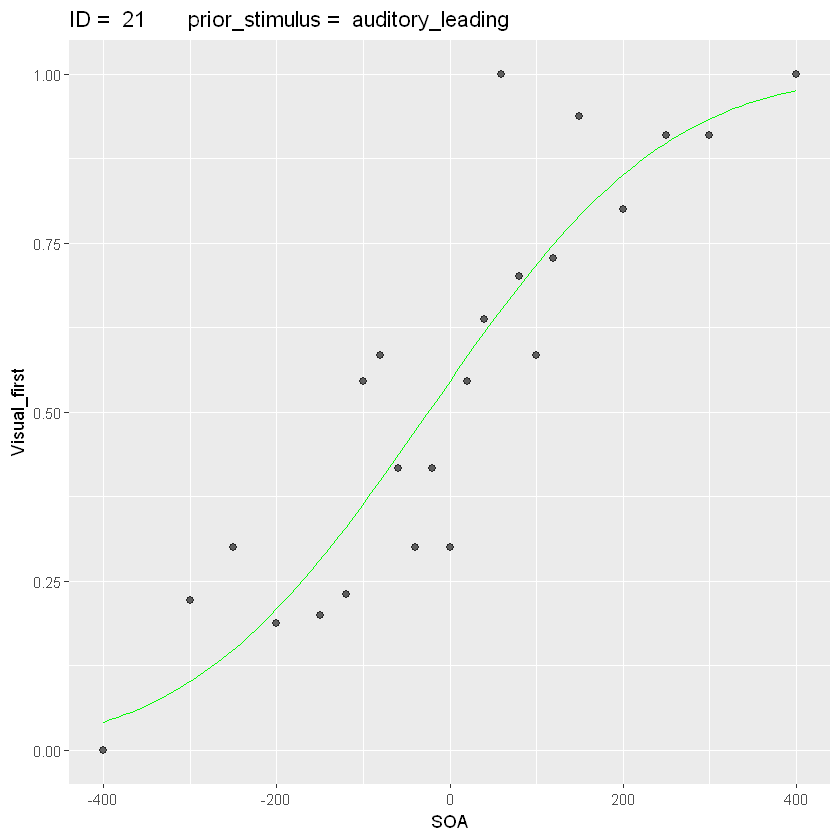

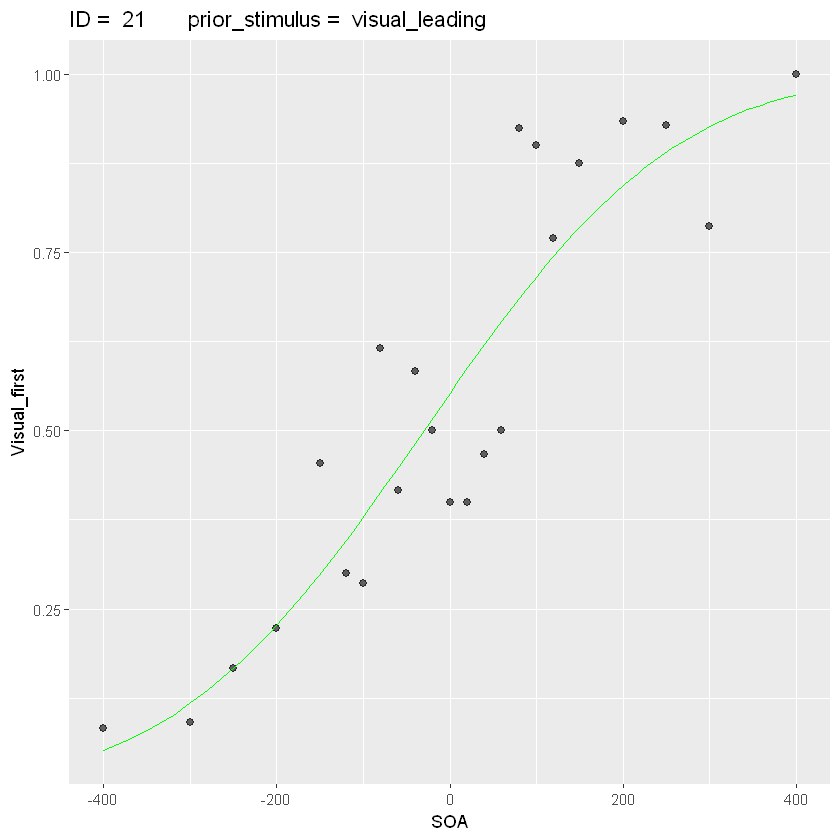

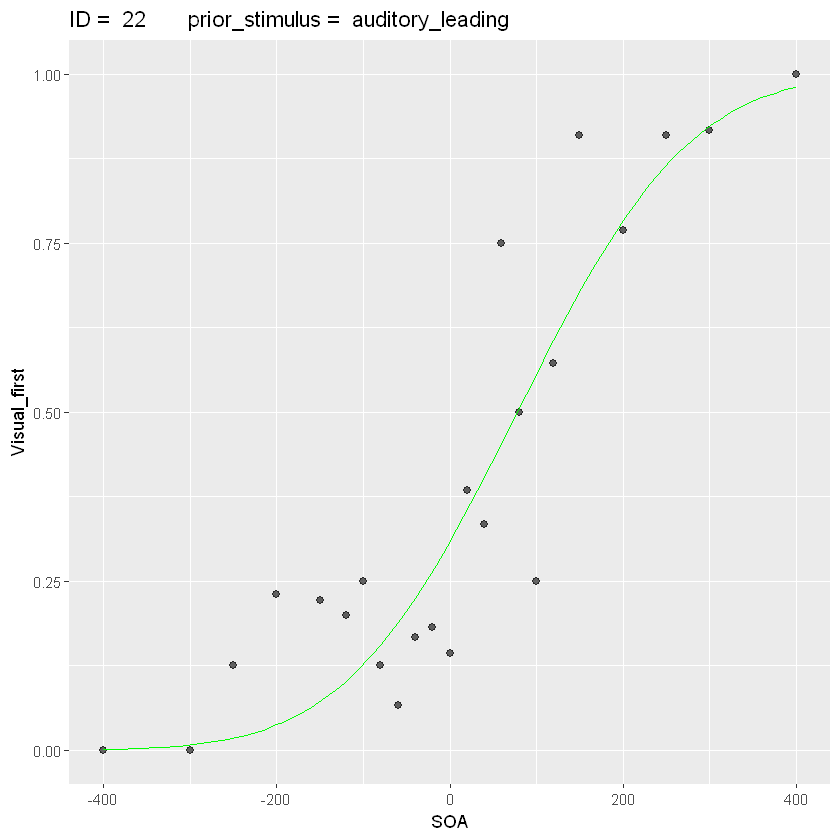

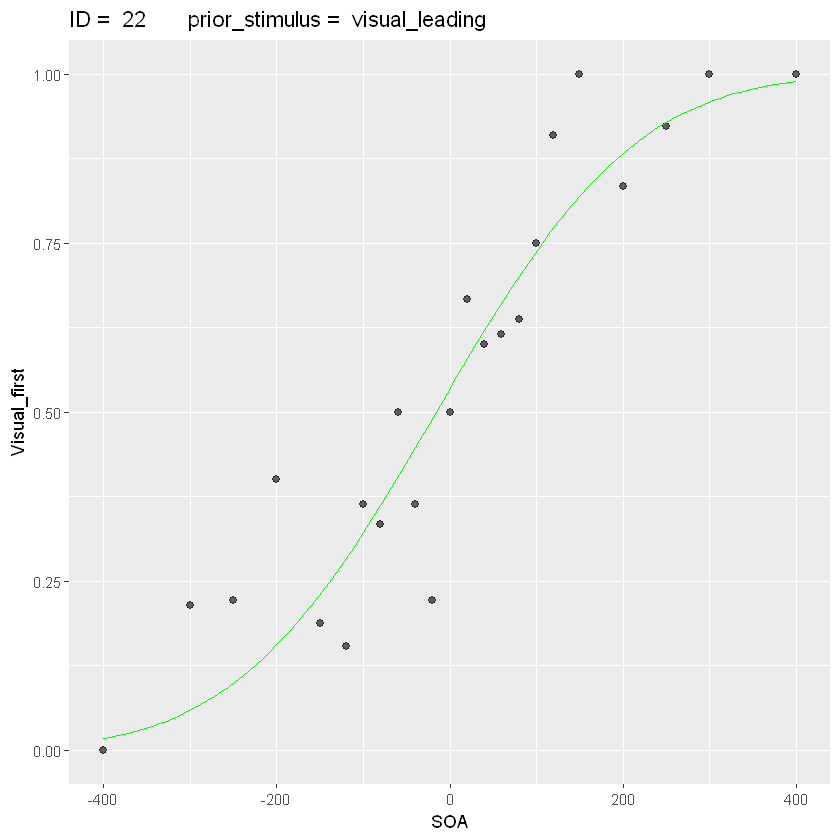

In [25]:
# plot of fits
ff <- function(x,SD,criterion){
    pnorm(x, mean = criterion, sd = SD)
}

df <- data %>% group_by(ID, prior_stimulus, SOA) %>%   
    summarise(
                Visual_first = mean(Visual_first == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(data$ID)){

    d1 <- df %>% filter(ID == subj)
    for(ps in unique(data$prior_stimulus)){
        d2 <- d1 %>% filter(prior_stimulus == ps)

        sd <- (model_results %>% filter(ID == subj) %>% filter(prior_stimulus == ps))$SD
        cri <- (model_results %>% filter(ID == subj) %>% filter(prior_stimulus == ps))$criterion
        print(ggplot(d2, aes(x = SOA, y = Visual_first)) +
                geom_point(size = 2, alpha = 0.6) +
                geom_function(fun=ff, args = list(SD = sd, criterion = cri), color='green') +
                labs(title = paste('ID = ',subj,'      prior_stimulus = ',ps)))
            
}}

In [26]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  return(1 - SS_res / SS_tot)
}

model_results$R2 <- NA

for(i in 1:nrow(model_results)){
  id <- model_results$ID[i]
  ps <- model_results$prior_stimulus[i]
  subdata <- df %>% filter(ID == id) %>% filter(prior_stimulus == ps)
  pred <- ff(subdata$SOA, model_results$SD[i], model_results$criterion[i])
  model_results$R2[i] <- R2(subdata$Visual_first, pred)
}

head(model_results)

,ID,prior_stimulus,SD,criterion,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,1,auditory_leading,247.7728,-5.969773,0.7920425
2,1,visual_leading,223.0294,-50.496364,0.8909576
3,3,auditory_leading,247.8573,-72.150489,0.7408402
4,3,visual_leading,214.2533,-43.846748,0.8660589
5,5,auditory_leading,170.8916,-96.650679,0.8573197
6,5,visual_leading,200.5958,-104.856409,0.8487369


In [28]:
model_results %>% arrange(R2)

ID,prior_stimulus,SD,criterion,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
11,visual_leading,449.55614,19.716203,0.4727659
11,auditory_leading,459.51432,199.829809,0.6135272
6,auditory_leading,440.53293,24.663259,0.6223421
6,visual_leading,353.06105,-36.046672,0.6804864
15,visual_leading,221.58756,-15.499223,0.6903330
20,visual_leading,124.19715,-130.805320,0.7031428
9,auditory_leading,177.94546,-169.053502,0.7367434
3,auditory_leading,247.85732,-72.150489,0.7408402
19,visual_leading,270.19869,-43.488015,0.7561083


In [99]:
# save parameter values
write_xlsx(
  model_results,
  "files/TOJ_prior_stimulus_observer_parameters.xlsx"
)

###############################################################
## 2-4 Plot group-level fits

In [29]:
model_results <- read_xlsx("files/TOJ_prior_stimulus_observer_parameters.xlsx")
head(model_results)

ID,prior_stimulus,SD,criterion
<dbl>,<chr>,<dbl>,<dbl>
1,auditory_leading,247.7728,-5.969777
1,visual_leading,223.0294,-50.496361
3,auditory_leading,247.8573,-72.150489
3,visual_leading,214.2533,-43.846748
5,auditory_leading,170.8916,-96.650677
5,visual_leading,200.5958,-104.856408


In [4]:
# compute predicted psychometric curves

ff <- function(x,SD,criterion){
    pnorm(x, mean = criterion, sd = SD)
}

df_predicted <- data.frame()

for(subj in unique(model_results$ID)){
    for(ps in unique(model_results$prior_stimulus)){
        sd <- (model_results %>% filter(ID == subj) %>% filter(prior_stimulus == ps))$SD
        cri <- (model_results %>% filter(ID == subj) %>% filter(prior_stimulus == ps))$criterion
        df <- data.frame(ID=subj, prior_stimulus=ps, SOA = -400:400, visual_first=ff(-400:400,sd,cri))
        df_predicted <- rbind(df_predicted, df)
}}

df_predicted_summary <- df_predicted %>%
  group_by(prior_stimulus, SOA) %>%
  summarise(
    mean_visual_first = mean(visual_first),
    se = sd(visual_first) / sqrt(n()),
    .groups = "drop"
  )

In [8]:
# Compute observed psychometric data

df_summary <- data %>%
  group_by(ID, prior_stimulus, SOA) %>%
  summarise(
    mvf = mean(Visual_first),
    .groups = "drop"
  ) %>% group_by(prior_stimulus, SOA) %>%
  summarise(
    mean_visual_first = mean(mvf),
    se = sd(mvf) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

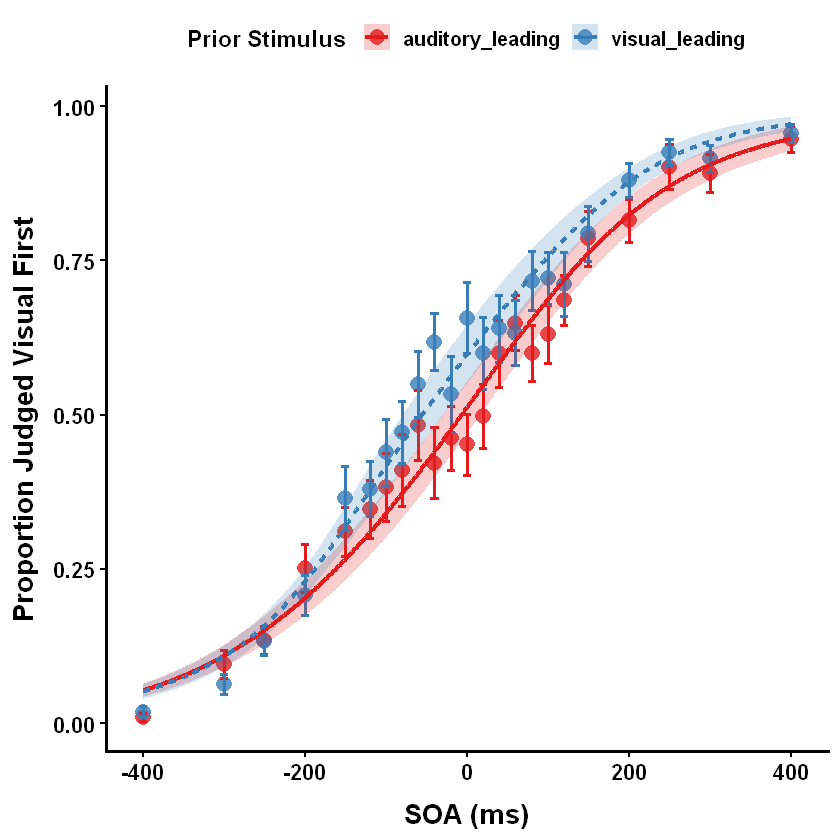

In [9]:
# =========================================================
# Visualize observed TOJ responses and fitted psychometric
# curves as a function of SOA and prior stimulus condition.
# =========================================================

pdf(file="figures/TOJ_prior_stimulus_observer_response.pdf", width = 10, height = 8)

p_toj_prior_stim <- 
  ggplot() +
  # Plot observed data points
  geom_point(
    data = df_summary,
    aes(x = SOA, y = mean_visual_first, color = prior_stimulus),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +

  # Add error bars for observed data
  geom_errorbar(
    data = df_summary,
    aes(
      x = SOA,
      ymin = mean_visual_first - se,
      ymax = mean_visual_first + se,
      color = prior_stimulus
    ),
    width = 10,
    linewidth = 1
  ) +

  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_visual_first - se,
      ymax = mean_visual_first + se,
      fill = prior_stimulus,
      group = prior_stimulus
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_visual_first,
      color = prior_stimulus,
      linetype = prior_stimulus,
      group = prior_stimulus
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Proportion Judged Visual First",
    color = "Prior Stimulus",
    linetype = "Prior Stimulus",
    fill = "Prior Stimulus"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_toj_prior_stim
dev.off()
# Display the plot
print(p_toj_prior_stim)


###############################################################
## 2-5 Statistical test of SD

In [30]:
psy_results <- read_xlsx("files/TOJ_prior_stimulus_observer_parameters.xlsx")
head(psy_results)

ID,prior_stimulus,SD,criterion
<dbl>,<chr>,<dbl>,<dbl>
1,auditory_leading,247.7728,-5.969777
1,visual_leading,223.0294,-50.496361
3,auditory_leading,247.8573,-72.150489
3,visual_leading,214.2533,-43.846748
5,auditory_leading,170.8916,-96.650677
5,visual_leading,200.5958,-104.856408


In [31]:
psy_results2 <- psy_results %>% group_by(ID) %>% summarise(
    diff = SD[prior_stimulus == "visual_leading"] - SD[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(psy_results2)

ID,diff
<dbl>,<dbl>
1,-24.74348
3,-33.60405
5,29.70417
6,-87.47188
7,-20.09346
8,-47.19442


In [32]:
#summary
psy_results %>% group_by(prior_stimulus) %>%  get_summary_stats(SD)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,SD,18,105.163,459.514,217.902,172.655,245.013,72.358,52.648,223.640,96.043,22.638,47.761
visual_leading,SD,18,61.092,449.556,203.376,126.408,226.635,100.228,78.326,200.464,94.250,22.215,46.869


In [33]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-116.854,37.619,-22.131,-52.058,10.015,62.073,48.337,-23.176,44.268,10.434,22.014


In [34]:
#identify outliers
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [35]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [36]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.958439,0.5717929


Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>."
Warning message:
"The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>."


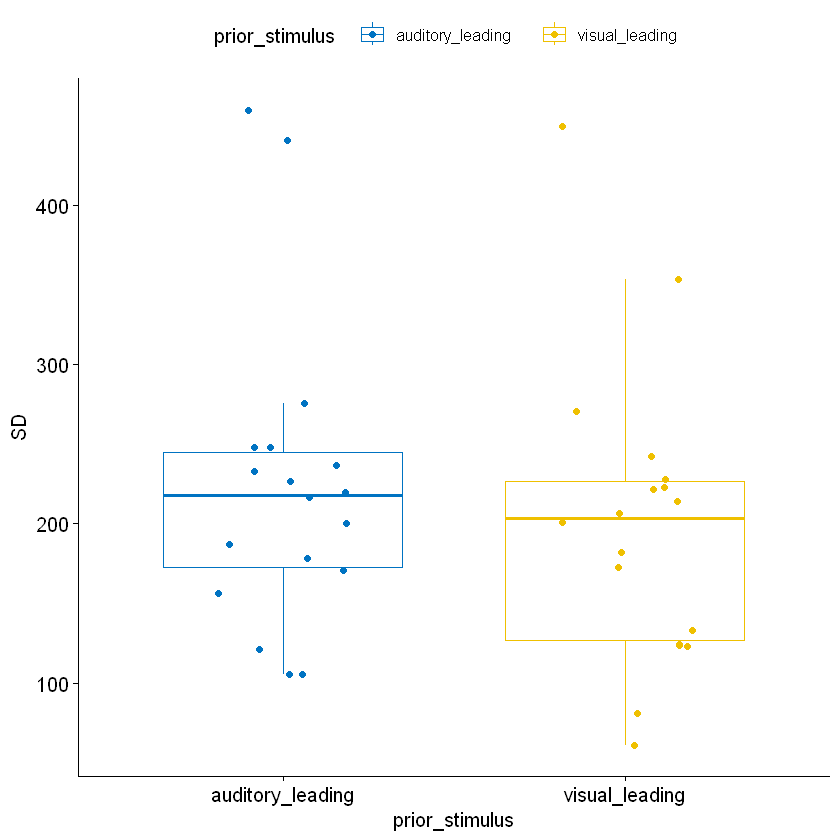

In [37]:
#plot
ggboxplot(
  psy_results, x = "prior_stimulus", y = "SD",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

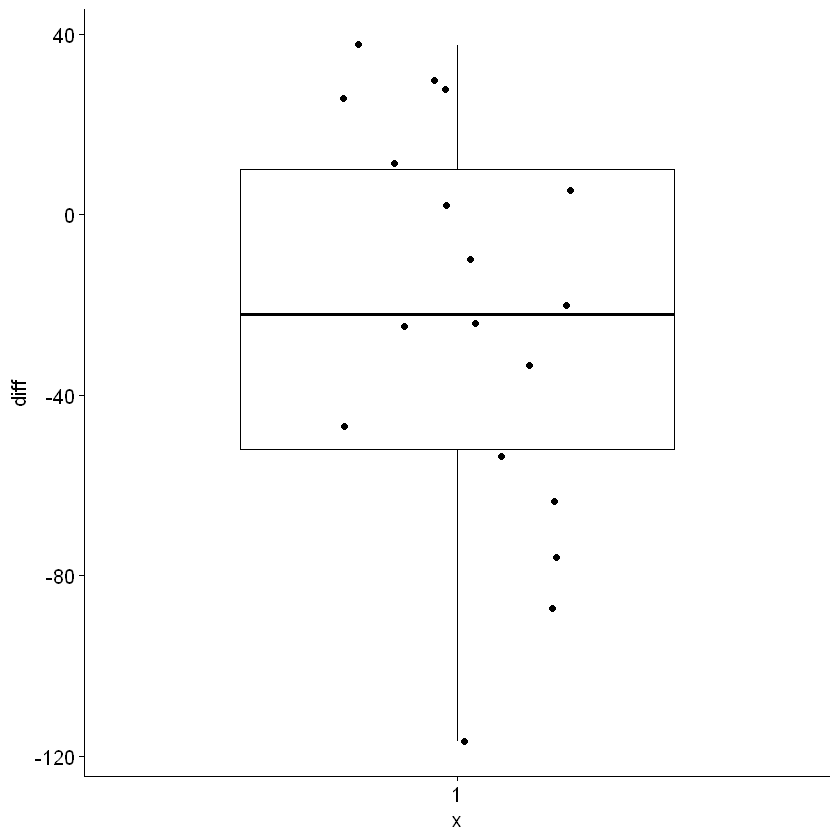

In [38]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [39]:
psy_results %>% t_test(SD ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,23.17615,SD,auditory_leading,visual_leading,18,18,2.221208,0.0402,17,1.162273,45.19003,T-test,two.sided


In [40]:
psy_results %>% cohens_d(SD ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,SD,auditory_leading,visual_leading,0.5235438,18,18,moderate


###############################################################
## 2-6 Statisttical test of criterion

In [41]:
psy_results <- read_xlsx("files/TOJ_prior_stimulus_observer_parameters.xlsx")
head(psy_results)

ID,prior_stimulus,SD,criterion
<dbl>,<chr>,<dbl>,<dbl>
1,auditory_leading,247.7728,-5.969777
1,visual_leading,223.0294,-50.496361
3,auditory_leading,247.8573,-72.150489
3,visual_leading,214.2533,-43.846748
5,auditory_leading,170.8916,-96.650677
5,visual_leading,200.5958,-104.856408


In [42]:
psy_results2 <- psy_results %>% group_by(ID) %>% summarise(
    diff = criterion[prior_stimulus == "visual_leading"] - criterion[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(psy_results2)

ID,diff
<dbl>,<dbl>
1,-44.526584
3,28.303741
5,-8.205731
6,-60.709928
7,-5.912483
8,-48.220744


In [43]:
#summary
psy_results %>% group_by(prior_stimulus) %>%  get_summary_stats(criterion)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,criterion,18,-169.054,199.830,-6.027,-79.704,36.361,116.065,101.450,-4.961,93.167,21.96,46.331
visual_leading,criterion,18,-169.120,148.561,-43.667,-91.279,-19.443,71.837,48.201,-46.764,70.895,16.71,35.255


In [44]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-180.114,29.453,-39.829,-59.611,-4.047,55.564,52.568,-41.803,56.556,13.33,28.125


In [45]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
11,-180.1136,TRUE,FALSE
13,-145.2246,TRUE,FALSE


In [46]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [47]:
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9106722,0.08841391


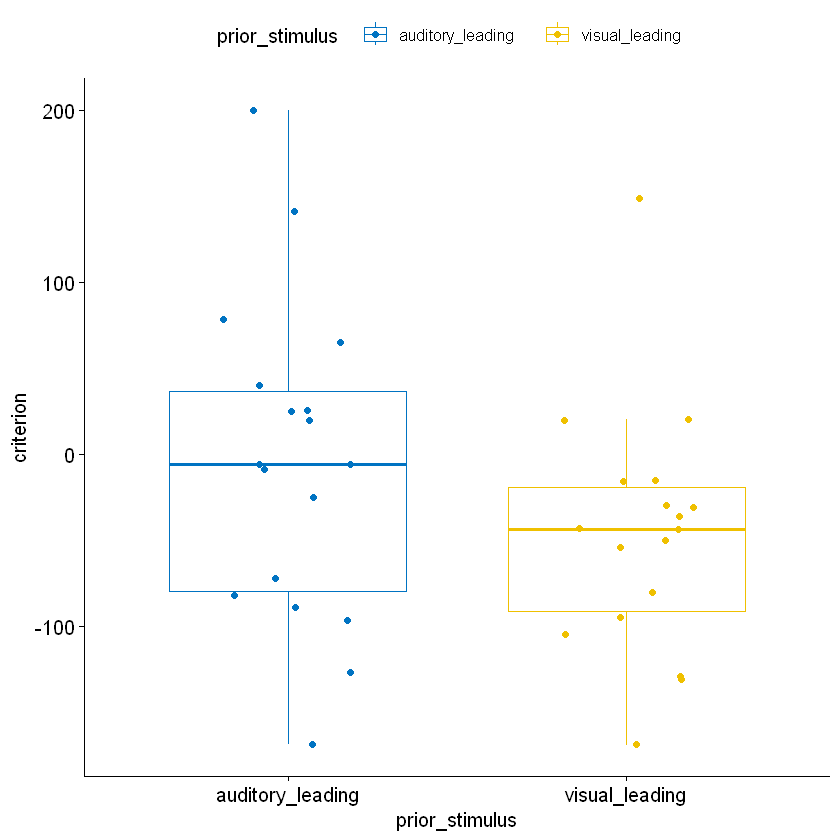

In [48]:
#plot
ggboxplot(
  psy_results, x = "prior_stimulus", y = "criterion",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

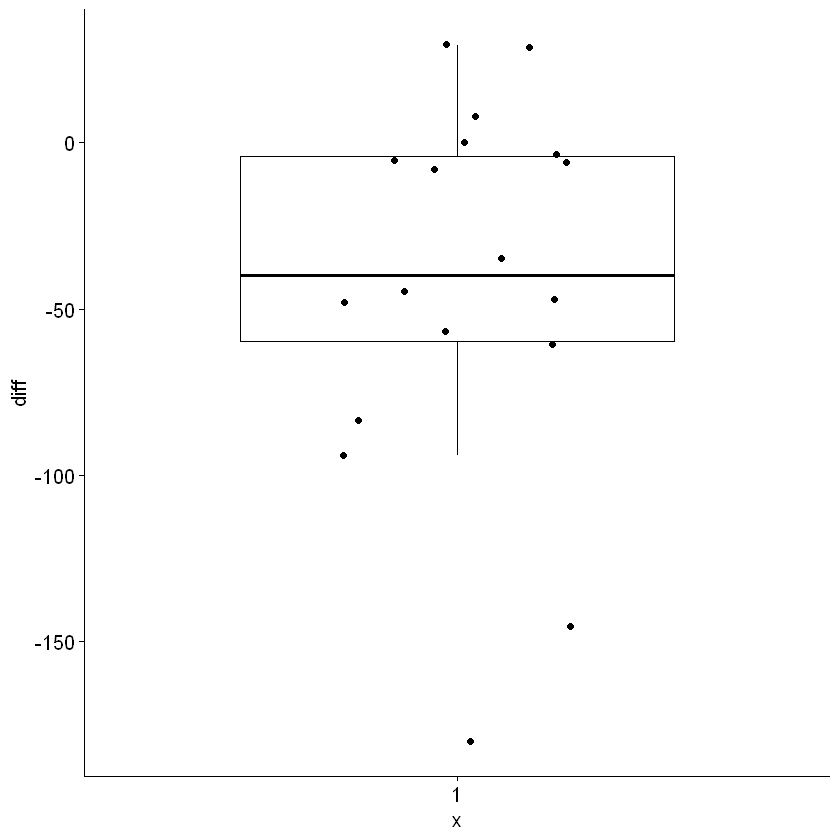

In [49]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [50]:
psy_results %>% t_test(criterion ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,41.80308,criterion,auditory_leading,visual_leading,18,18,3.135915,0.00602,17,13.67834,69.92782,T-test,two.sided


In [51]:
psy_results %>% cohens_d(criterion ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,criterion,auditory_leading,visual_leading,0.7391422,18,18,moderate


In [52]:
wilcox.test(psy_results$criterion[psy_results$prior_stimulus=='auditory_leading'], psy_results$criterion[psy_results$prior_stimulus=='visual_leading'], paired = TRUE, conf.int = TRUE)


	Wilcoxon signed rank exact test

data:  psy_results$criterion[psy_results$prior_stimulus == "auditory_leading"] and psy_results$criterion[psy_results$prior_stimulus == "visual_leading"]
V = 151, p-value = 0.002808
alternative hypothesis: true location shift is not equal to 0
95 percent confidence interval:
  8.941294 69.917913
sample estimates:
(pseudo)median 
      32.86715 


###############################################################\
###############################################################
# 3- Serial Dependence based on Prior Response
**List of contents:**\
3-1 Load data\
3-2 Fit psychometric model\
3-3 Check fits\
3-4 Plot group-level fits\
3-5 Statistical test of SD\
3-6 Statistical test of criterion

###############################################################
## 3-1 Load data

In [53]:
###############################################################
# Load TOJ dataset
###############################################################

data <- read_xlsx("files/TOJ_prior_response_data.xlsx")
head(data)

participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,a,-400,a,1.4540460
1,a,-400,a,1.5044811
1,a,-400,a,1.0698638
1,a,-400,a,1.3872484
1,a,-300,a,0.8524889
1,a,-300,a,1.3702865


In [54]:
###############################################################
# Prepare behavioral variables
###############################################################

data <- data %>%
  rename(
    ID = 1,
    Visual_first = 4,
    prior_response = 2
  ) %>%
  mutate(
    Visual_first = ifelse(Visual_first == "v", 1, 0),
    prior_response = recode(
      prior_response,
      "v" = "visual response",
      "a" = "auditory response"
    )
  )

###############################################################
## 3-2 Fit psychometric model

In [55]:
# model:
# P(visual first) = Φ(SOA | mean=criterion, sd=SD)

model <- function(data){
  loss_function <- function(params){
    SD <- params[1]
    criterion <- params[2]
    predicted <-  pnorm(data$SOA, mean = criterion, sd = SD)
    sum((predicted - data$Visual_first)^2)
  }

  DEoptim(
    loss_function,
    lower = c(.001, -500),
    upper = c(1200, 500)
  )
}

psy_results <- data.frame()

for(subj in unique(data$ID)){
    d1 <- data %>% filter(ID == subj)
    for(pr in unique(data$prior_response)){
        d2 <- d1 %>% filter(prior_response == pr)
        fit <- model(d2)$optim$bestmem

        psy_results <- rbind(
            psy_results,
            data.frame(
              ID = subj,
              prior_response = pr,
              SD = fit[1],
              criterion = fit[2]
    )
  )
}}

rownames(psy_results) <- NULL

Iteration: 1 bestvalit: 51.828082 bestmemit:  410.991486   42.330819
Iteration: 2 bestvalit: 51.828082 bestmemit:  410.991486   42.330819
Iteration: 3 bestvalit: 48.509049 bestmemit:  118.055035   30.377762
Iteration: 4 bestvalit: 47.689151 bestmemit:  215.714179   42.330819
Iteration: 5 bestvalit: 47.689151 bestmemit:  215.714179   42.330819
Iteration: 6 bestvalit: 47.689151 bestmemit:  215.714179   42.330819
Iteration: 7 bestvalit: 47.631451 bestmemit:  210.787065   42.568822
Iteration: 8 bestvalit: 47.631451 bestmemit:  210.787065   42.568822
Iteration: 9 bestvalit: 47.534755 bestmemit:  179.518325   53.116161
Iteration: 10 bestvalit: 47.534755 bestmemit:  179.518325   53.116161
Iteration: 11 bestvalit: 47.443151 bestmemit:  183.894949   40.262301
Iteration: 12 bestvalit: 47.443151 bestmemit:  183.894949   40.262301
Iteration: 13 bestvalit: 47.443151 bestmemit:  183.894949   40.262301
Iteration: 14 bestvalit: 47.433219 bestmemit:  175.663481   40.628020
Iteration: 15 bestvalit: 47.4

In [56]:
head(psy_results)

,ID,prior_response,SD,criterion
,<dbl>,<chr>,<dbl>,<dbl>
1,1,auditory response,177.2456,41.65522
2,1,visual response,231.3840,-106.95318
3,3,auditory response,273.2830,-83.61495
4,3,visual response,180.4212,-25.56019
5,5,auditory response,158.2461,-105.22898
6,5,visual response,204.6033,-107.44080


###############################################################
## 3-3 Check fits

In [57]:
# check if the data is complete
nrow(psy_results)

[1] 36

In [58]:
# check if the parameter range in fitting is appropriate
sort(psy_results$SD)
sort(psy_results$criterion)

[1]  80.43985  99.87245 106.19877 106.65745 119.30537 119.95264 125.47439
 [8] 130.68475 141.46656 158.24612 160.78262 173.98230 176.29903 177.24559
[15] 180.42119 182.80123 192.32371 193.27721 199.40140 203.30176 203.58530
[22] 204.60329 206.99541 231.38400 231.75058 231.82266 234.51812 259.42517
[29] 261.70906 264.27995 266.59886 273.28296 285.83512 291.95896 384.93445
[36] 431.00517

[1] -193.275242 -156.228269 -154.003268 -135.635446 -129.558018 -112.337371
 [7] -109.146698 -107.440800 -106.953181 -105.228975  -98.583669  -96.219098
[13]  -83.614946  -77.808423  -70.081821  -65.939626  -63.190738  -59.167944
[19]  -53.422105  -41.718040  -25.560195  -12.329023   -9.797044    3.712324
[25]    4.608297    6.619119   30.535447   41.655219   49.432255   84.245751
[31]   92.075877   92.977911  109.470898  126.808976  162.002812  225.286963

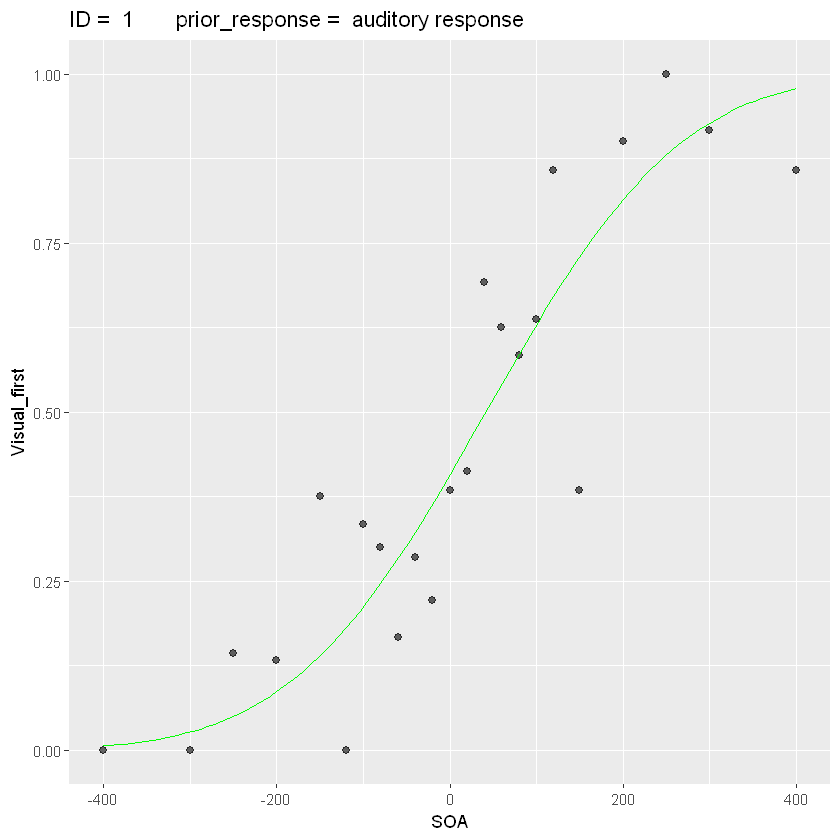

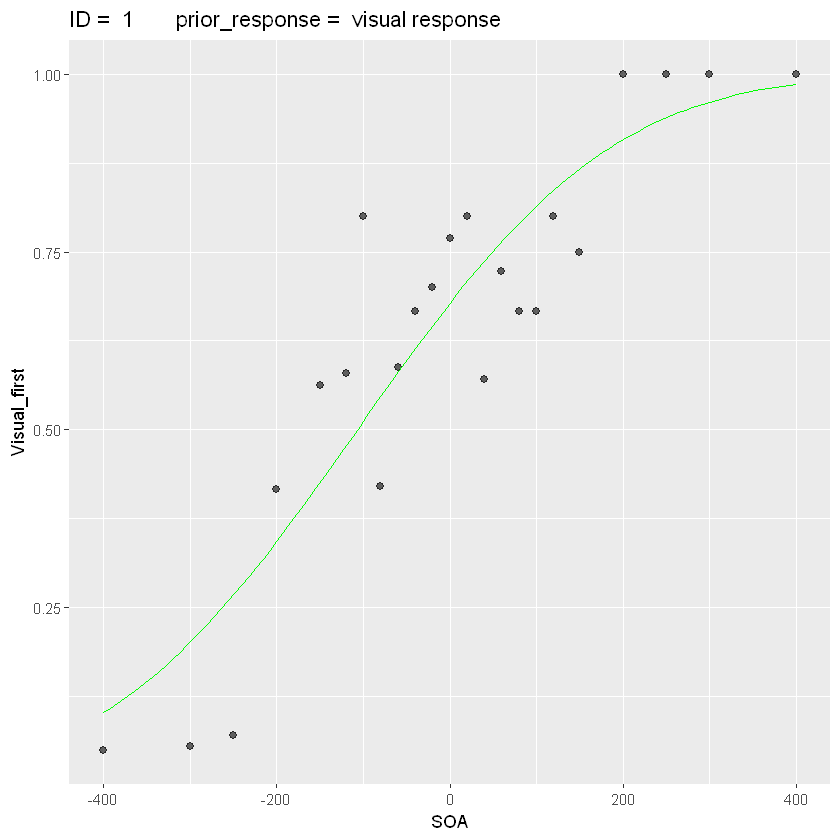

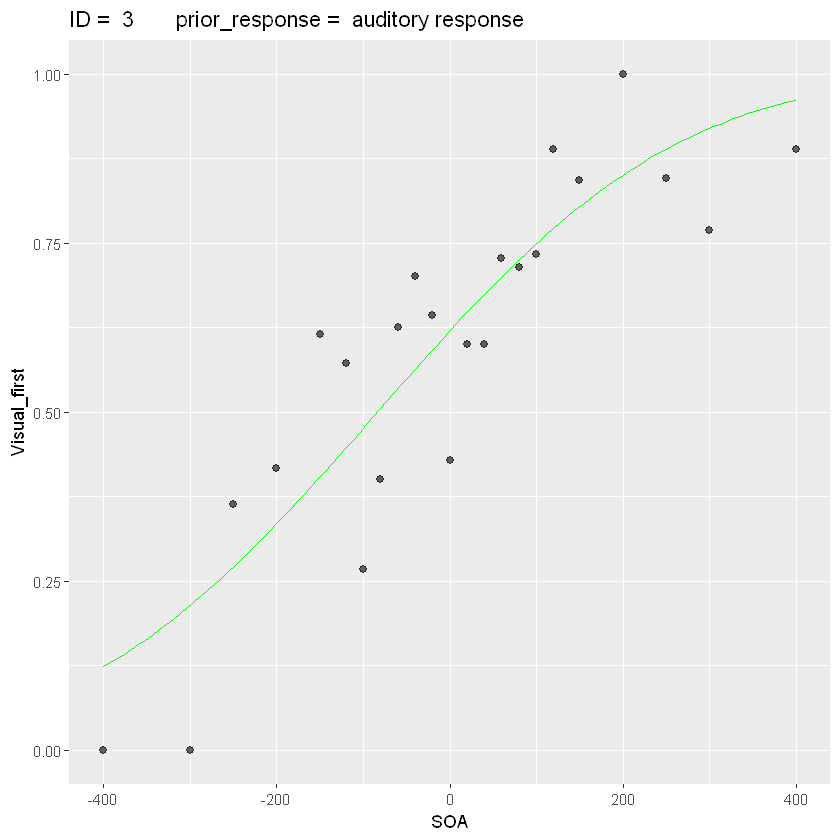

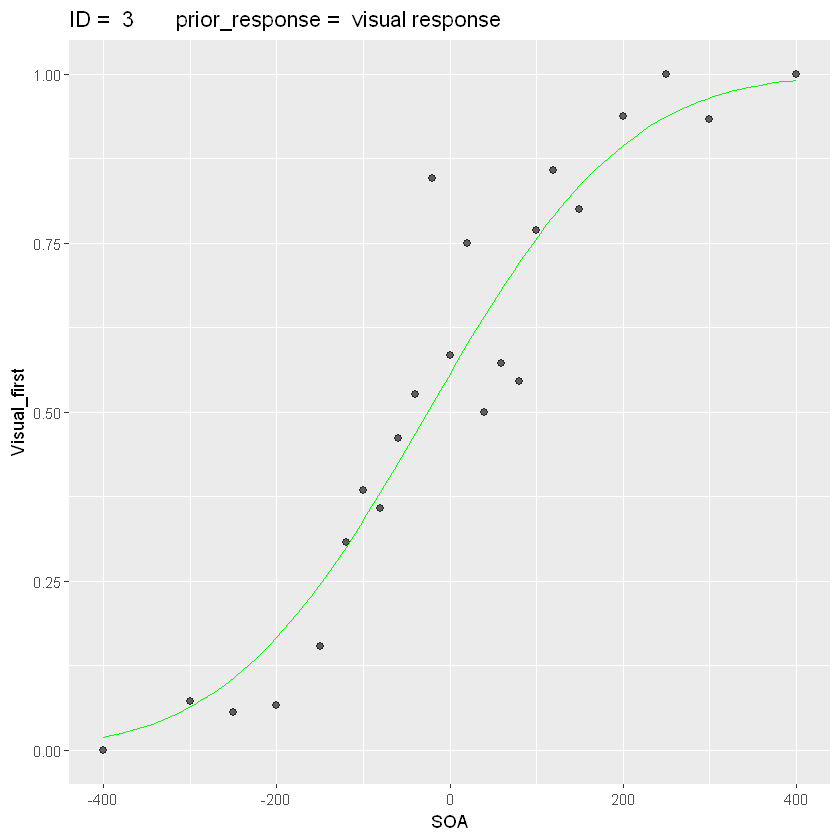

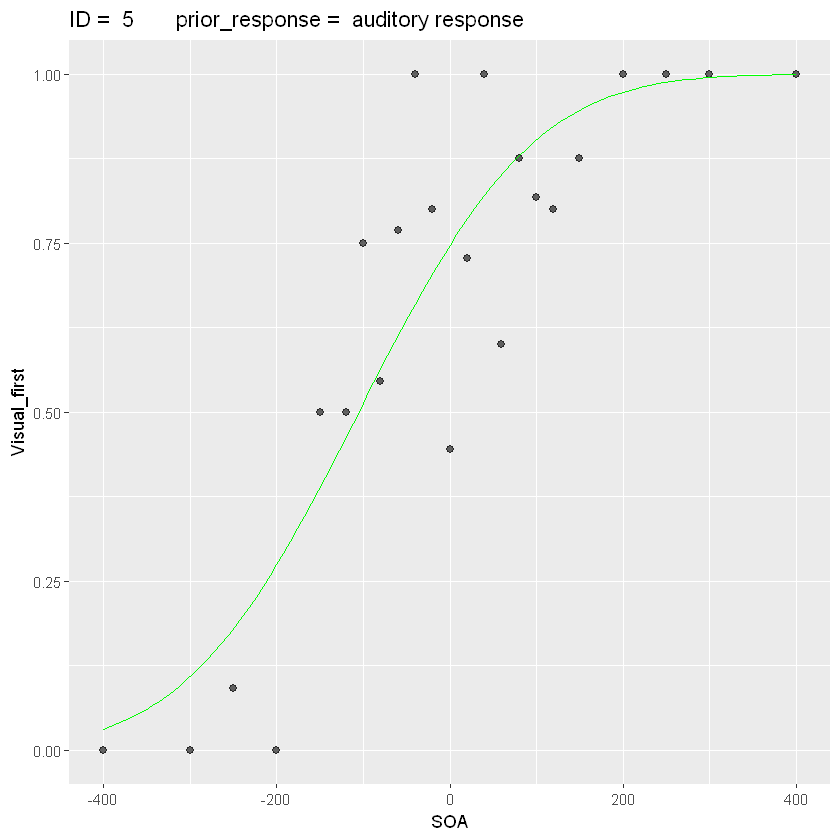

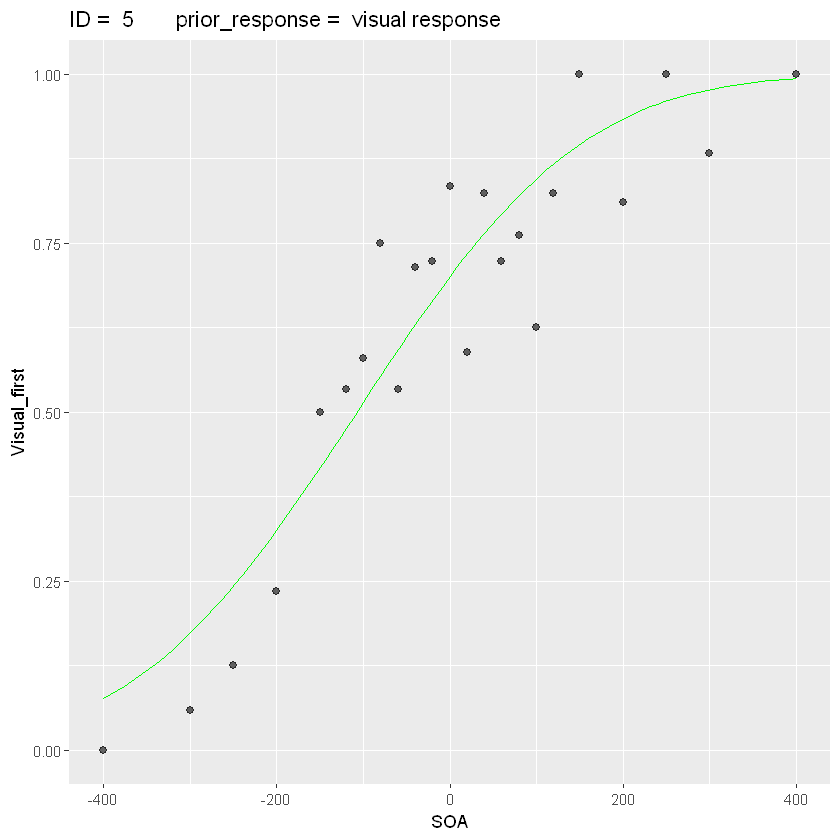

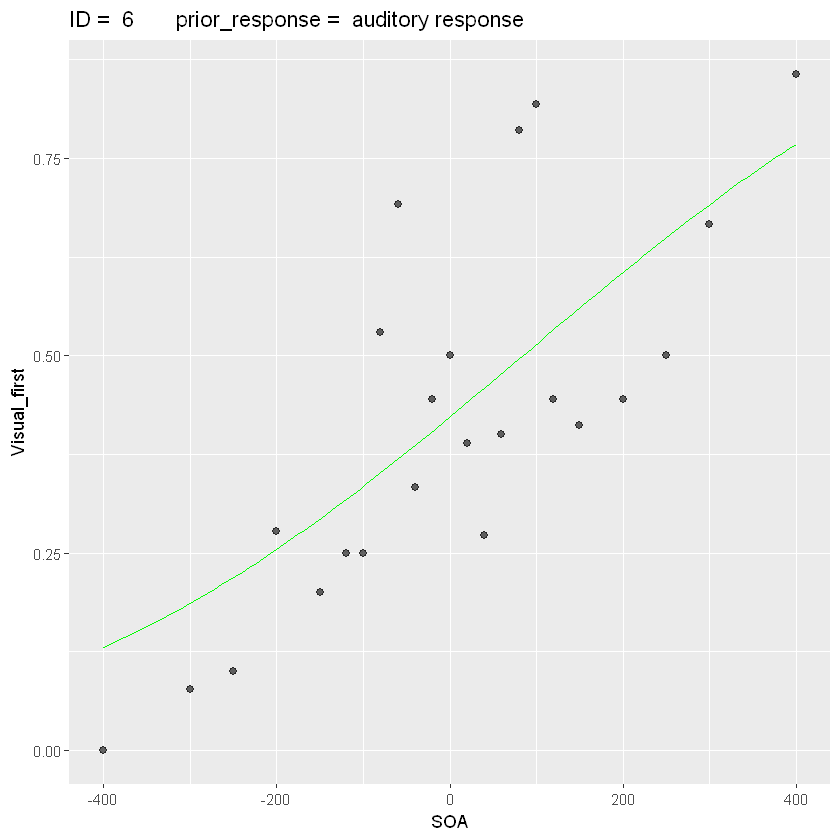

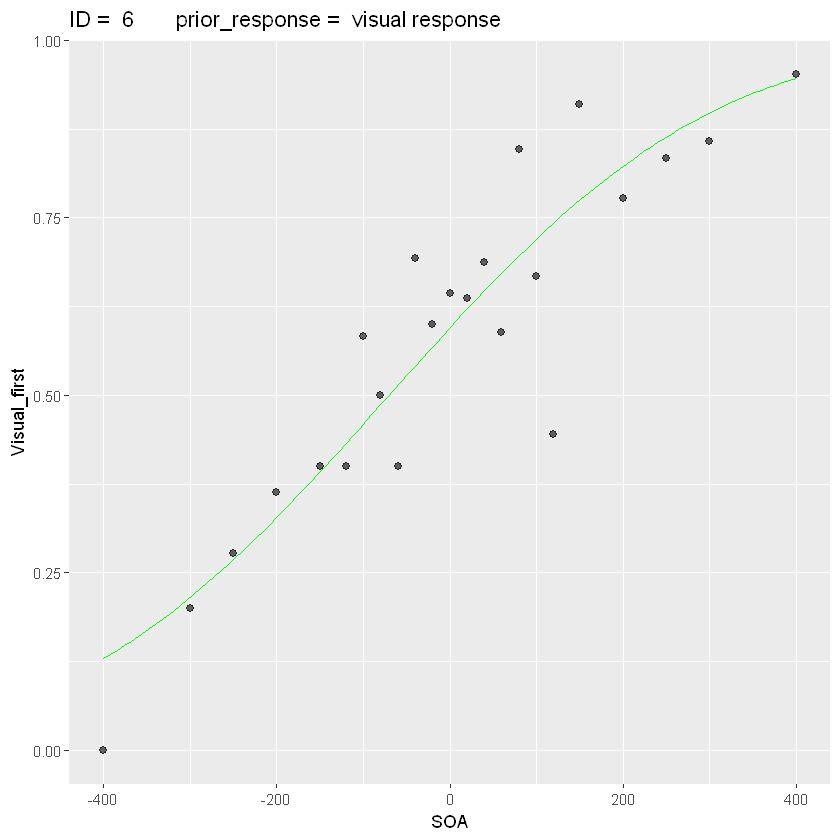

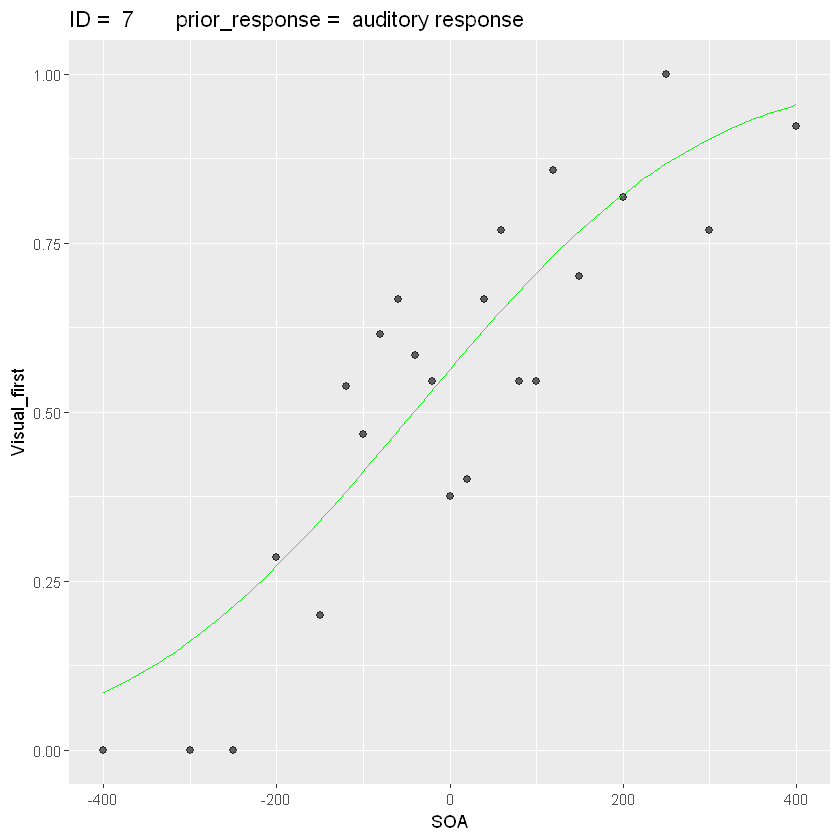

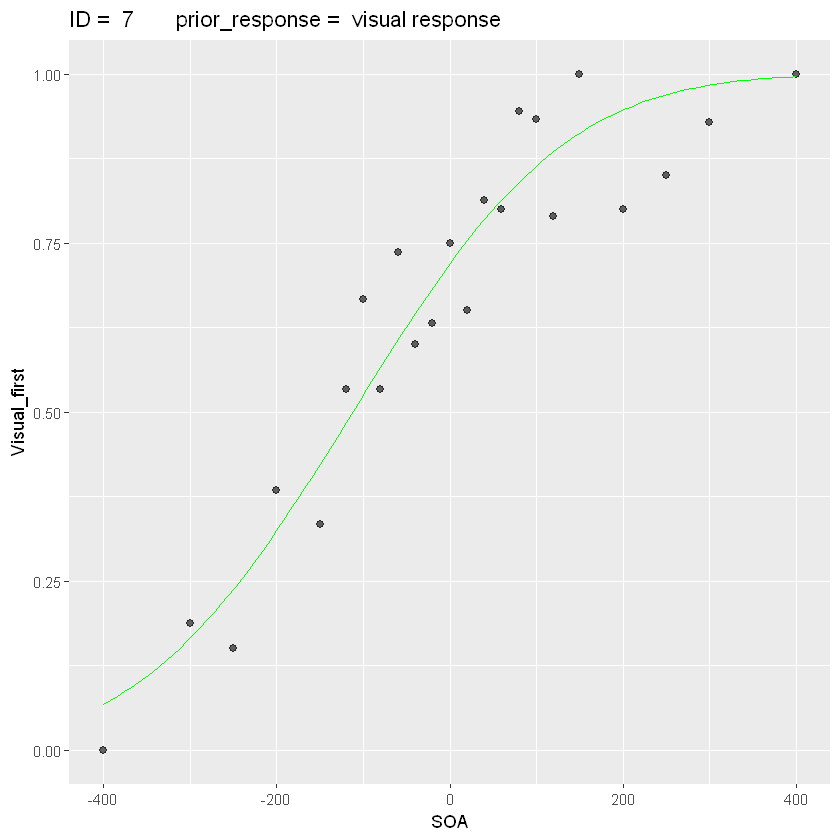

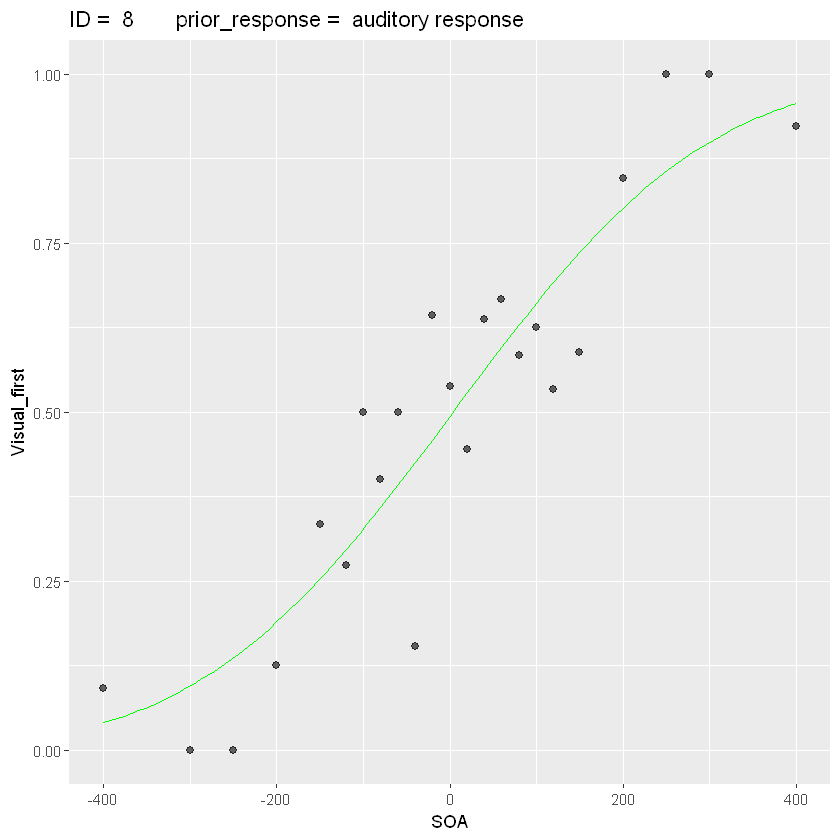

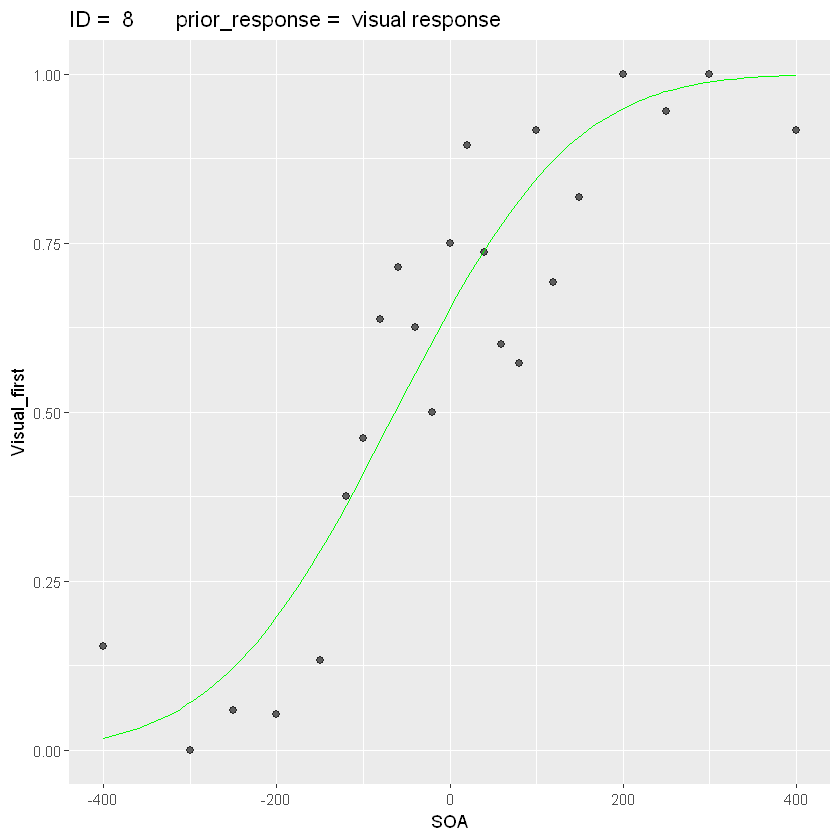

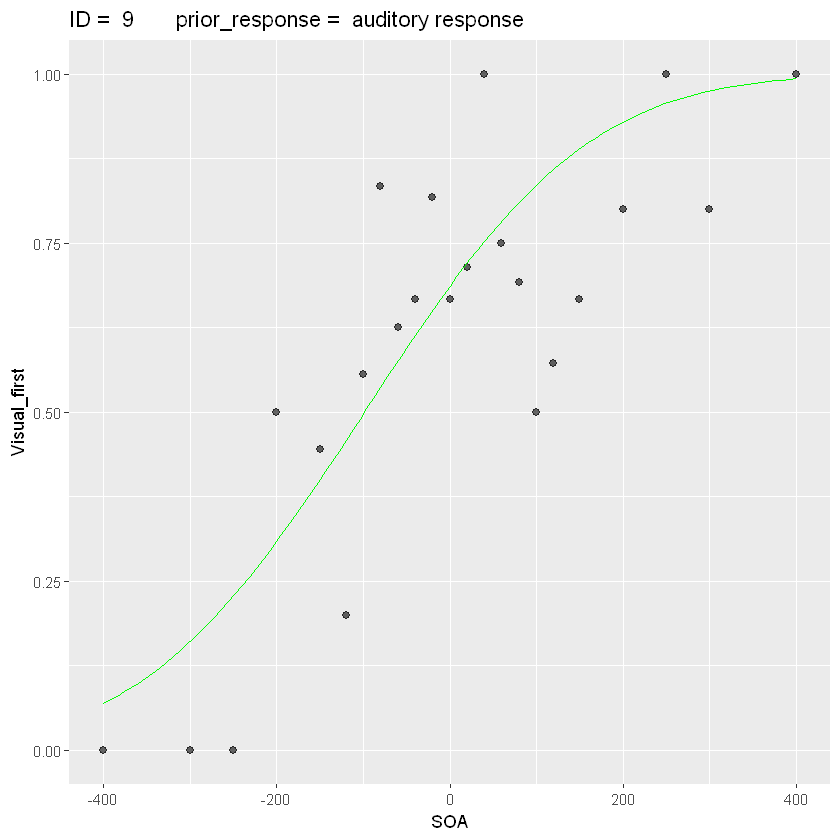

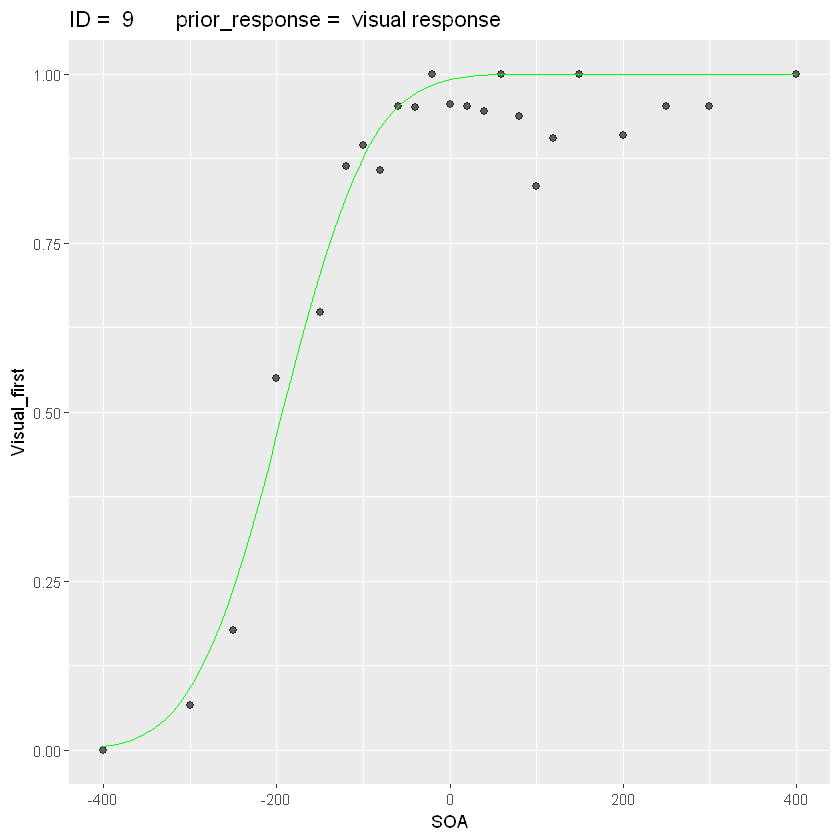

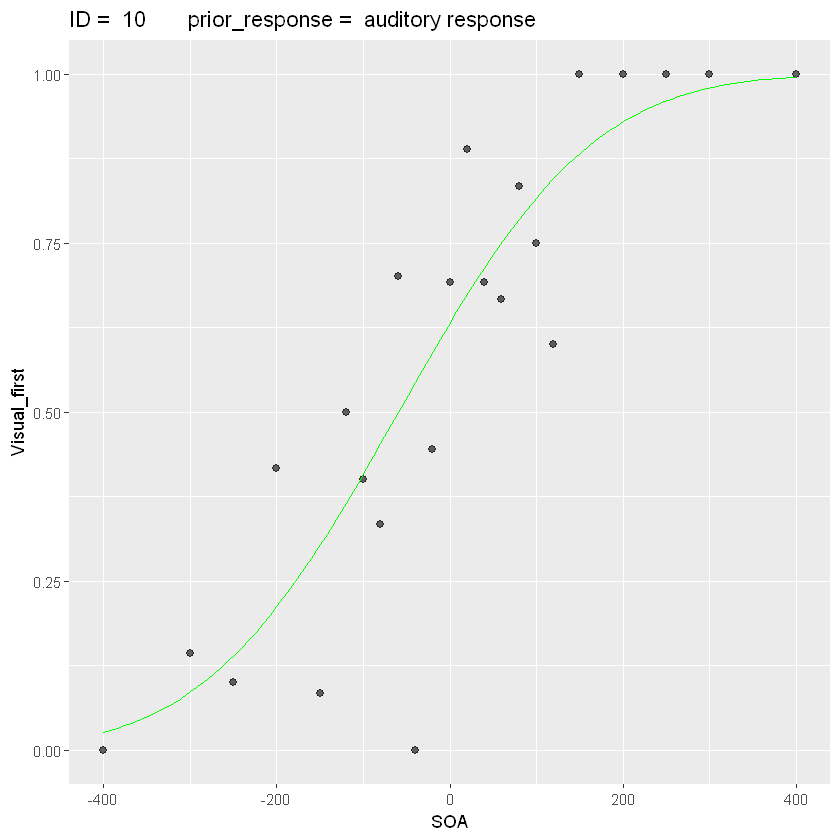

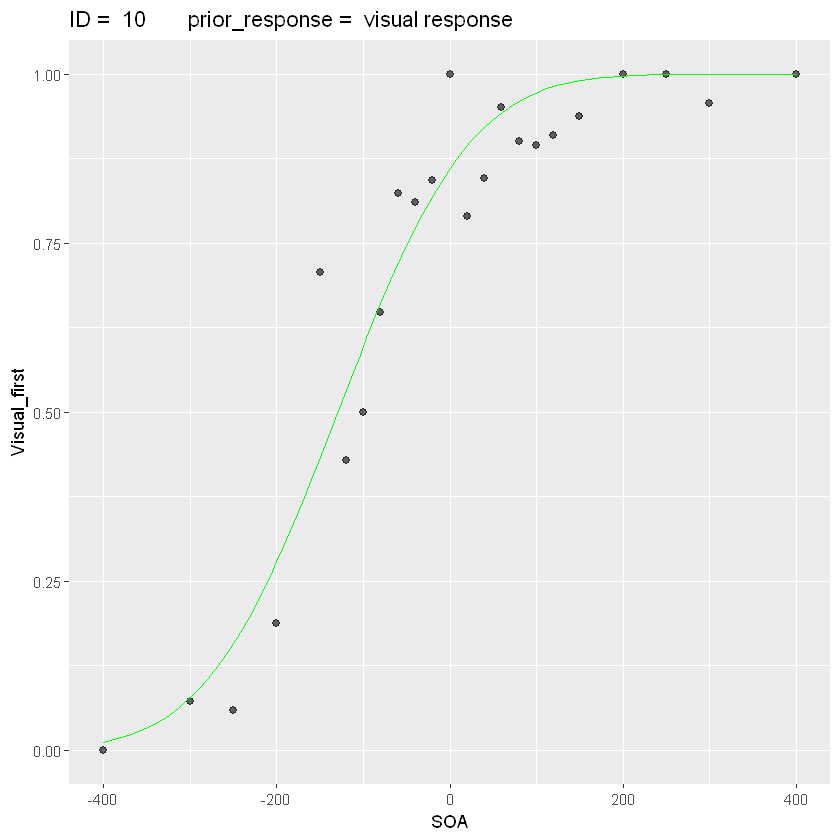

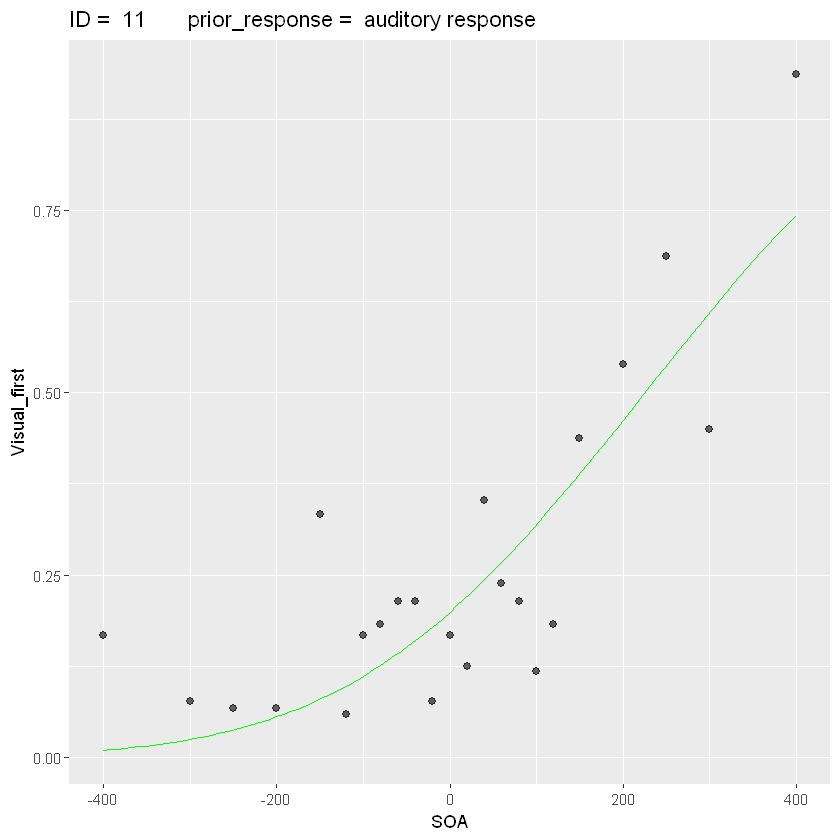

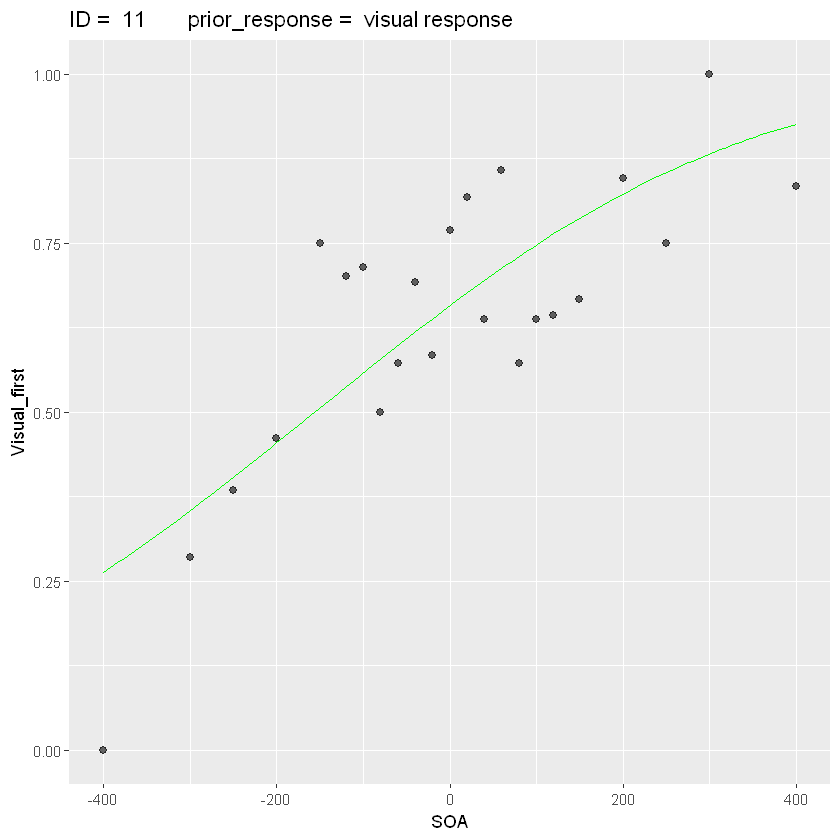

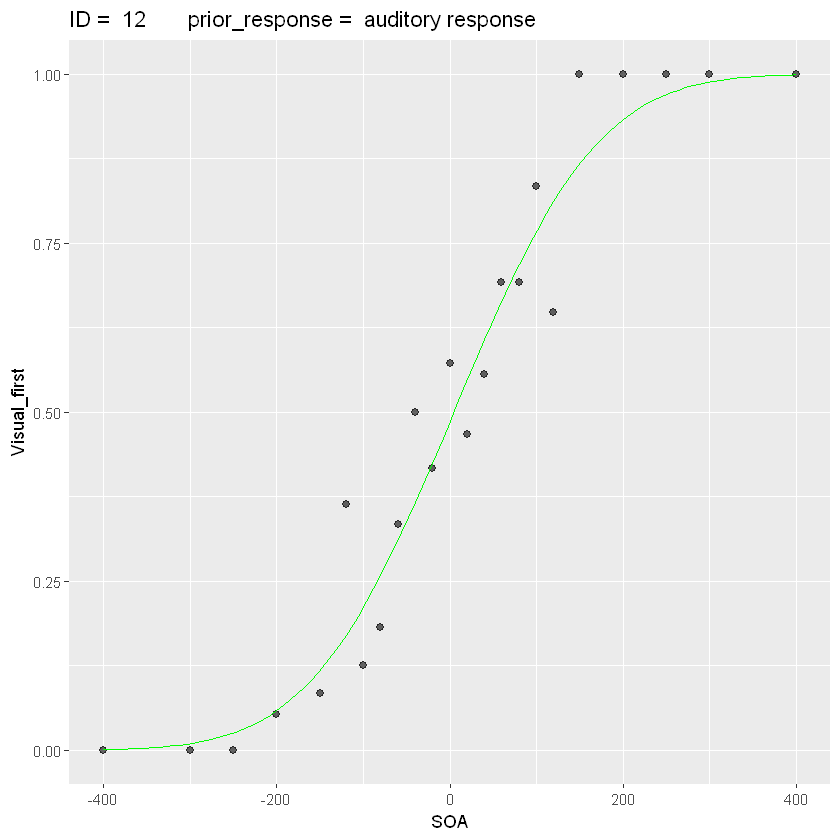

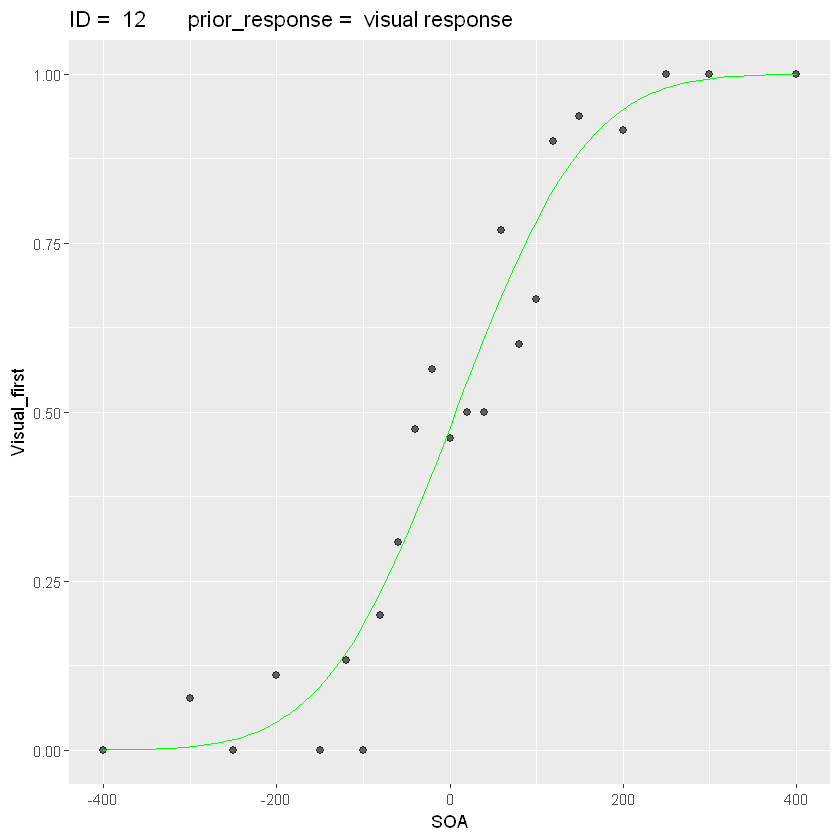

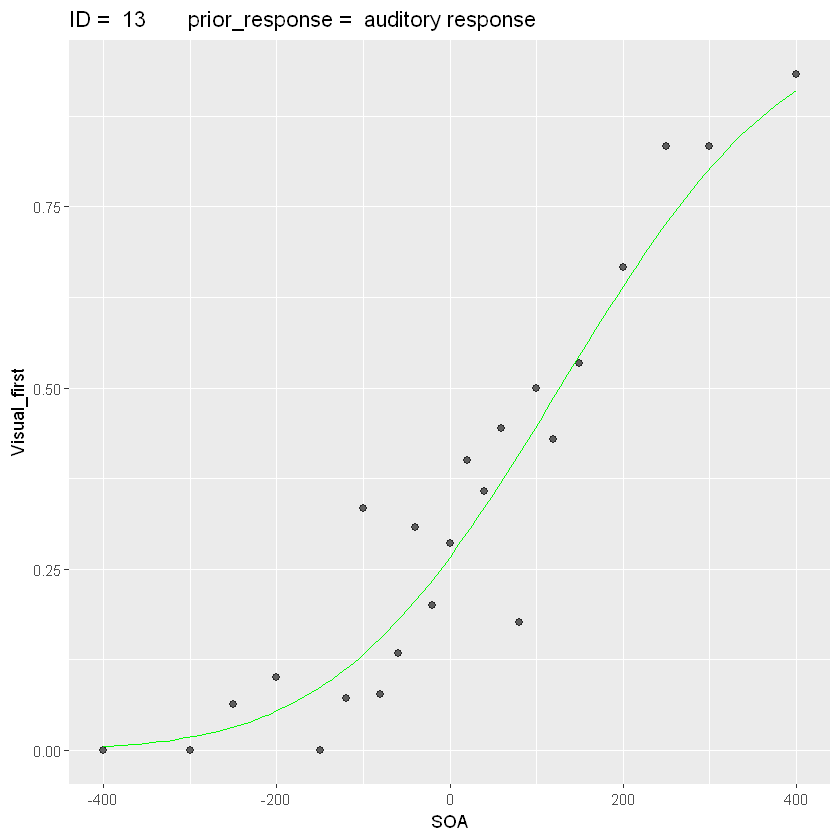

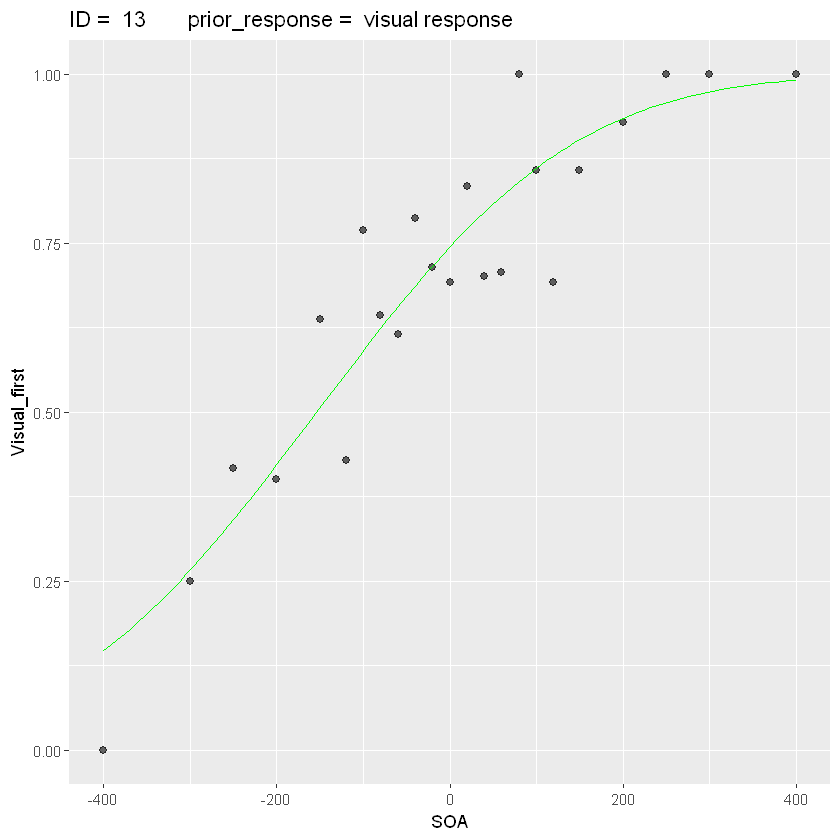

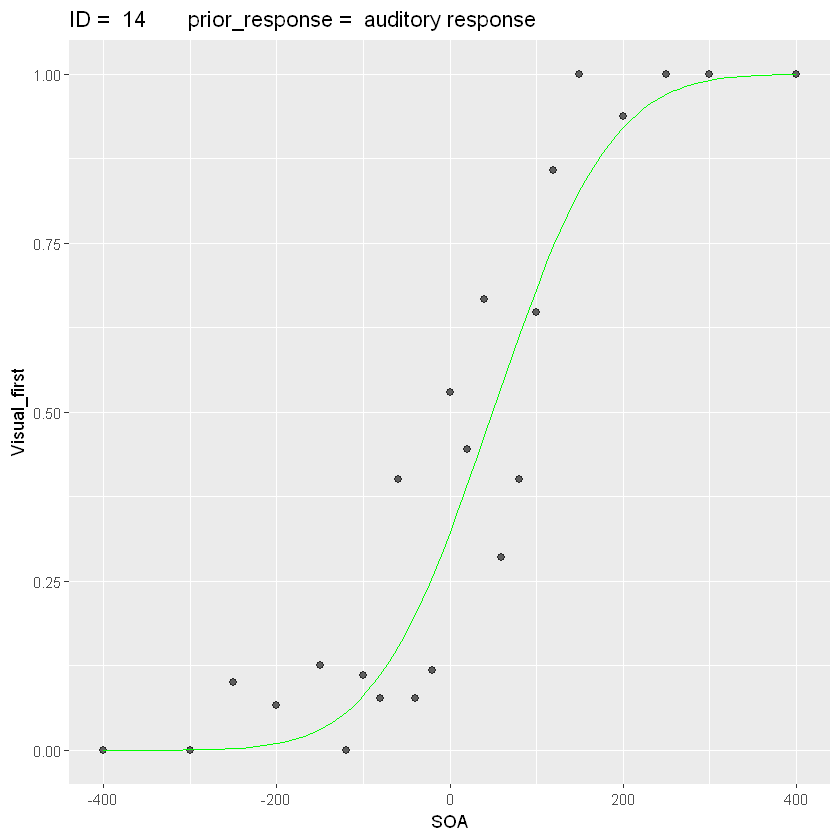

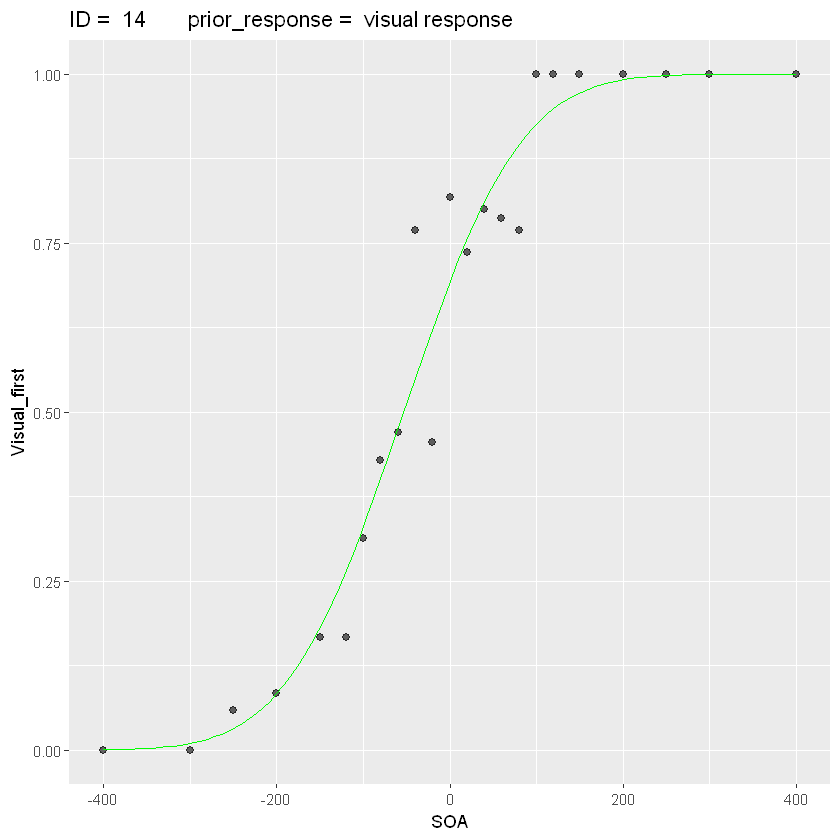

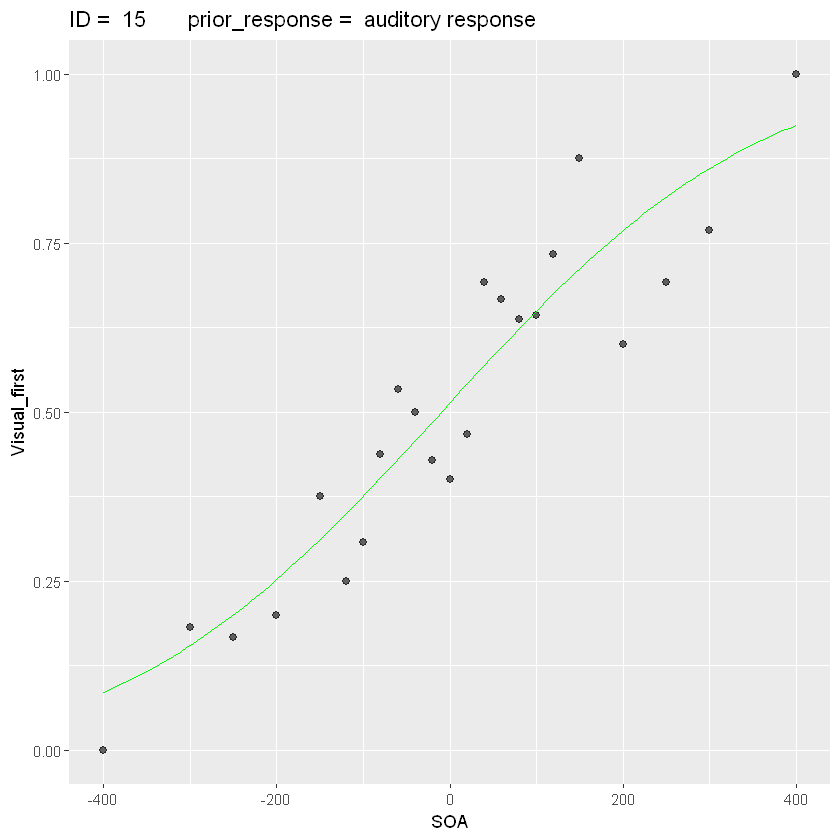

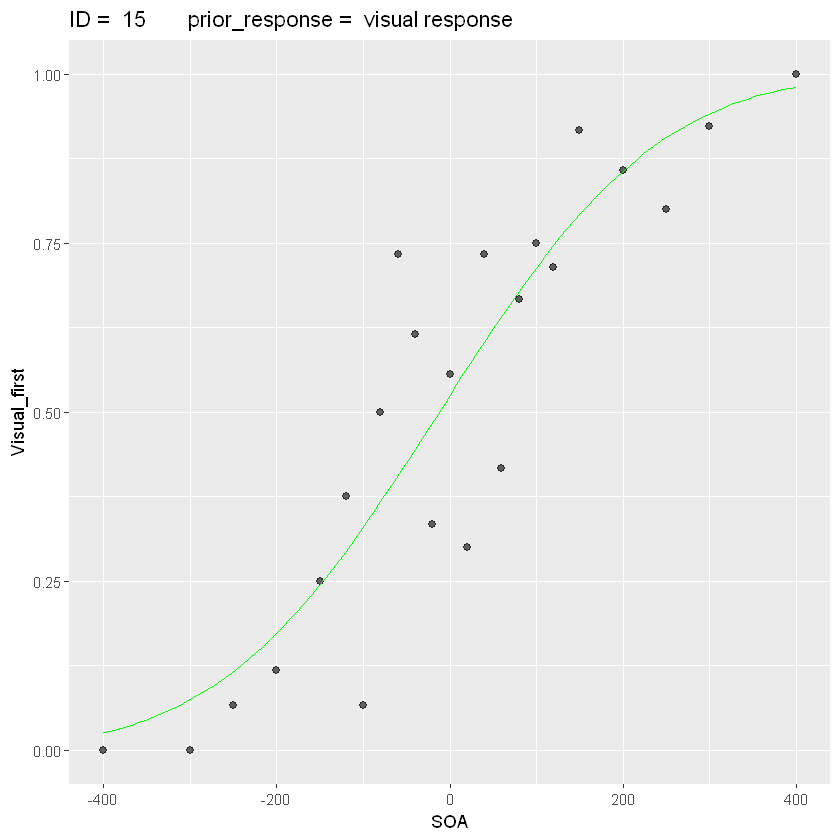

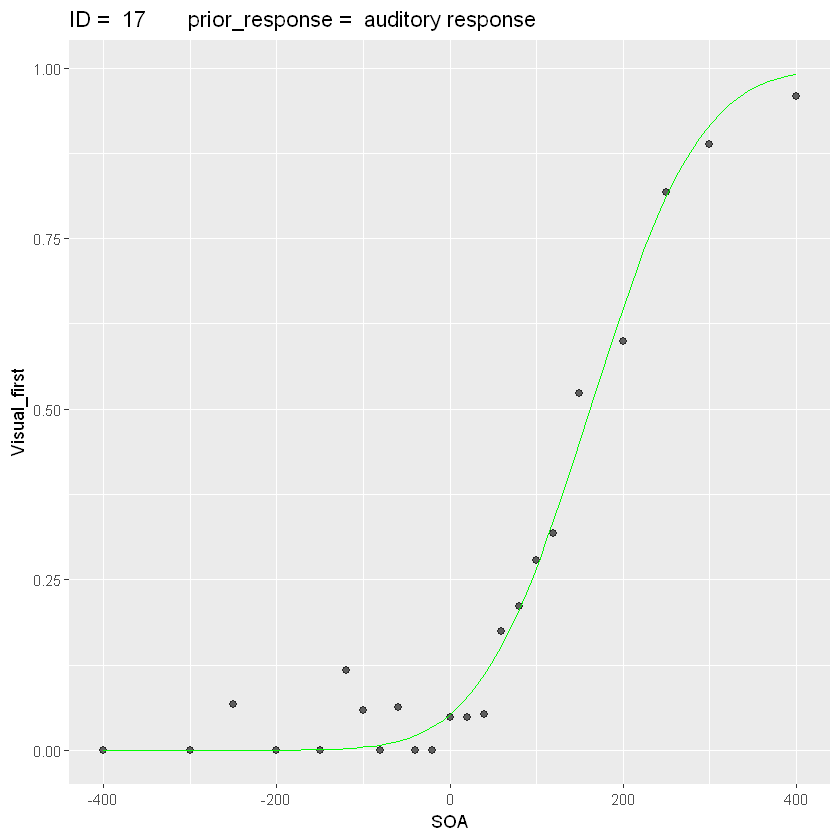

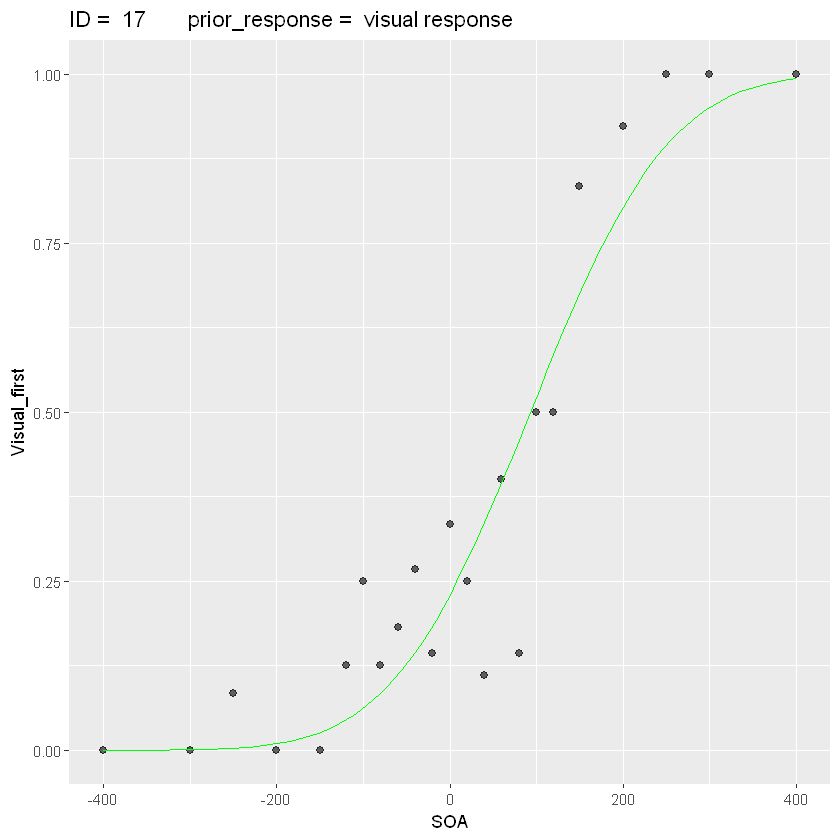

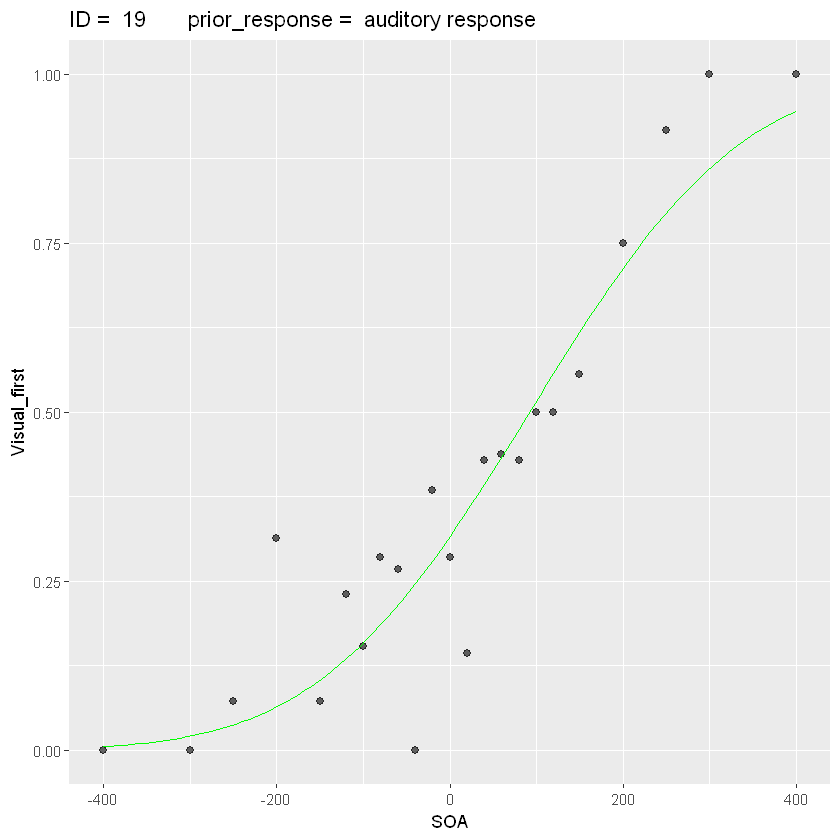

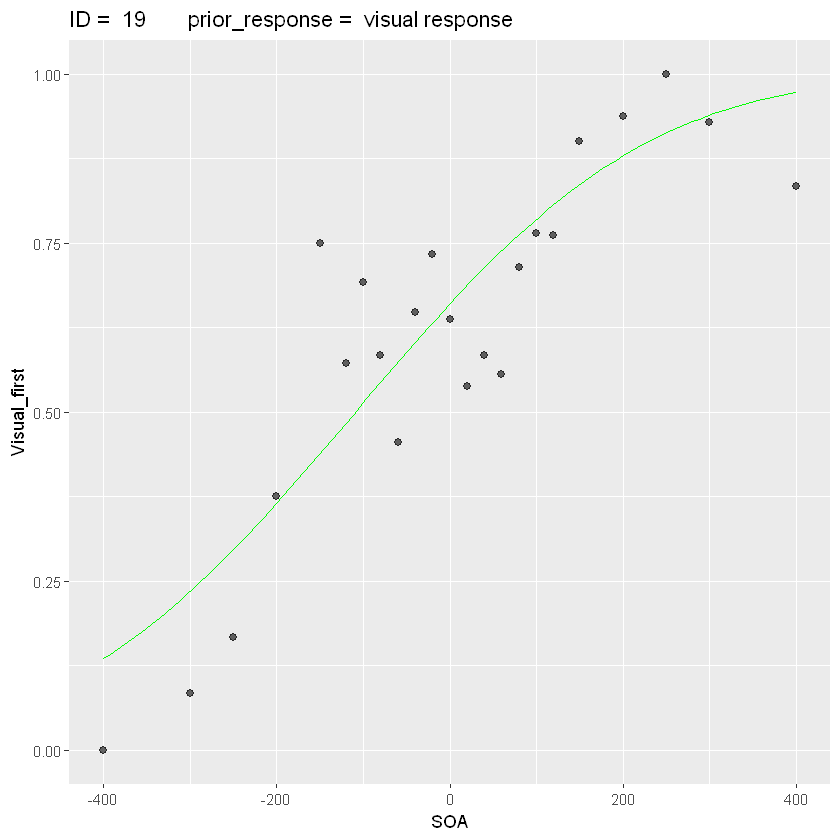

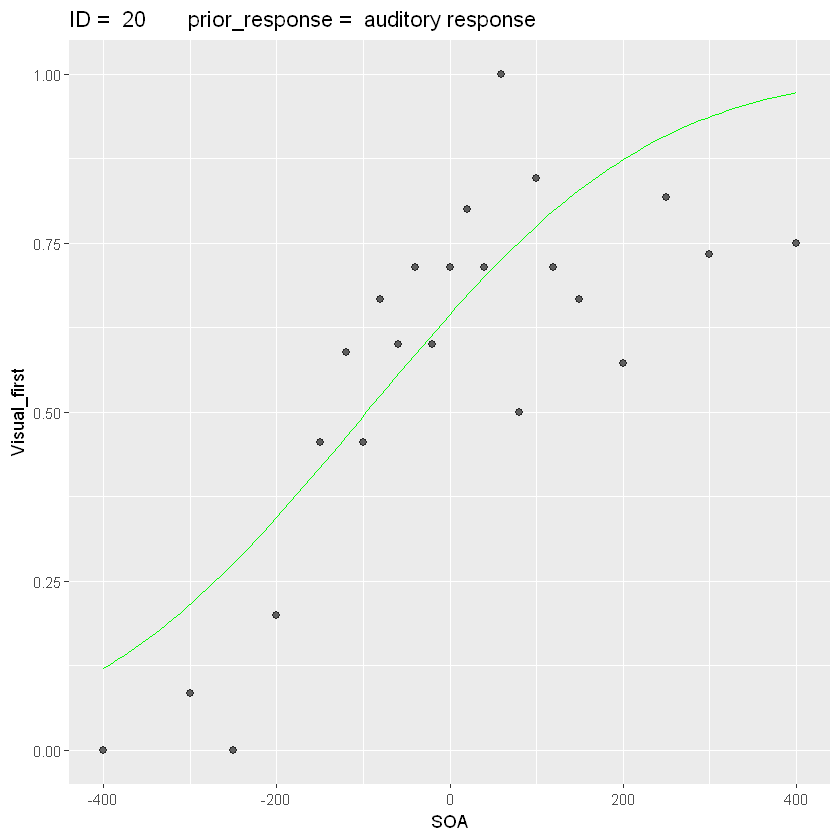

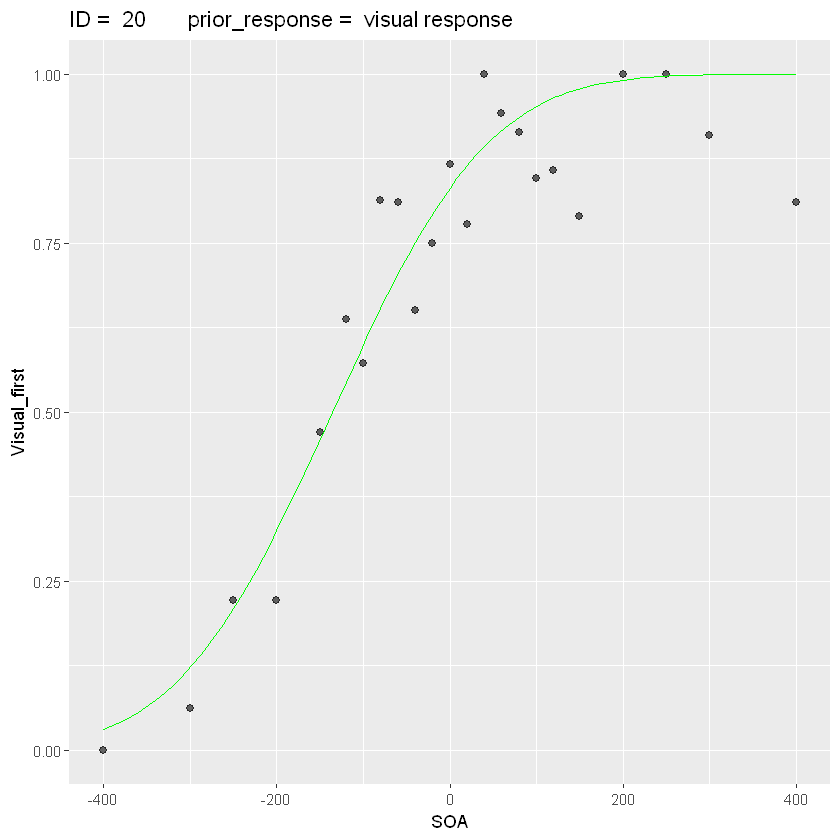

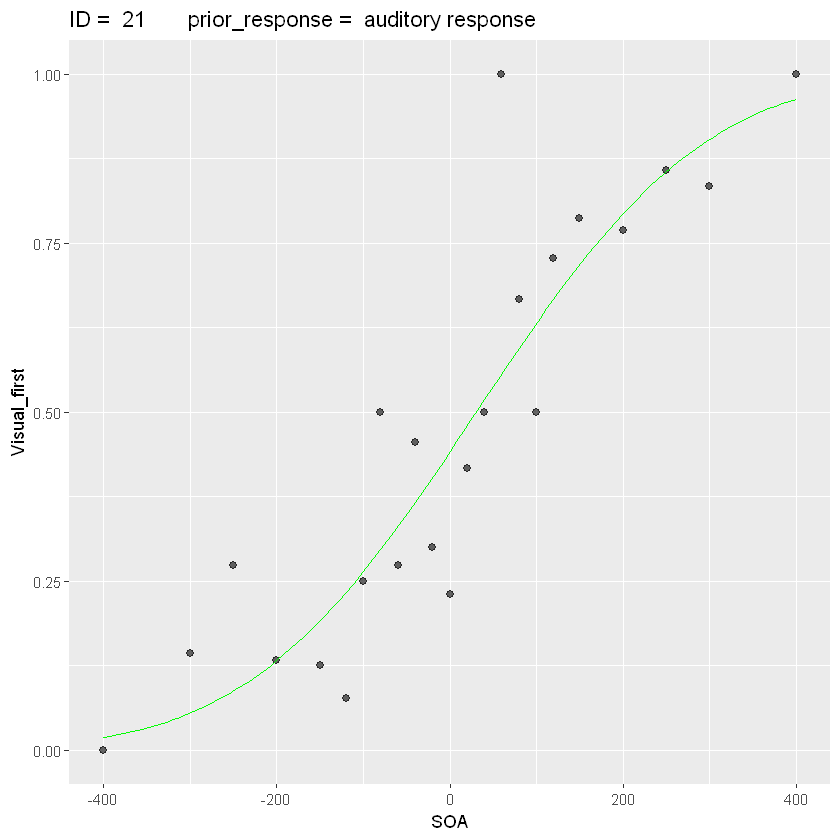

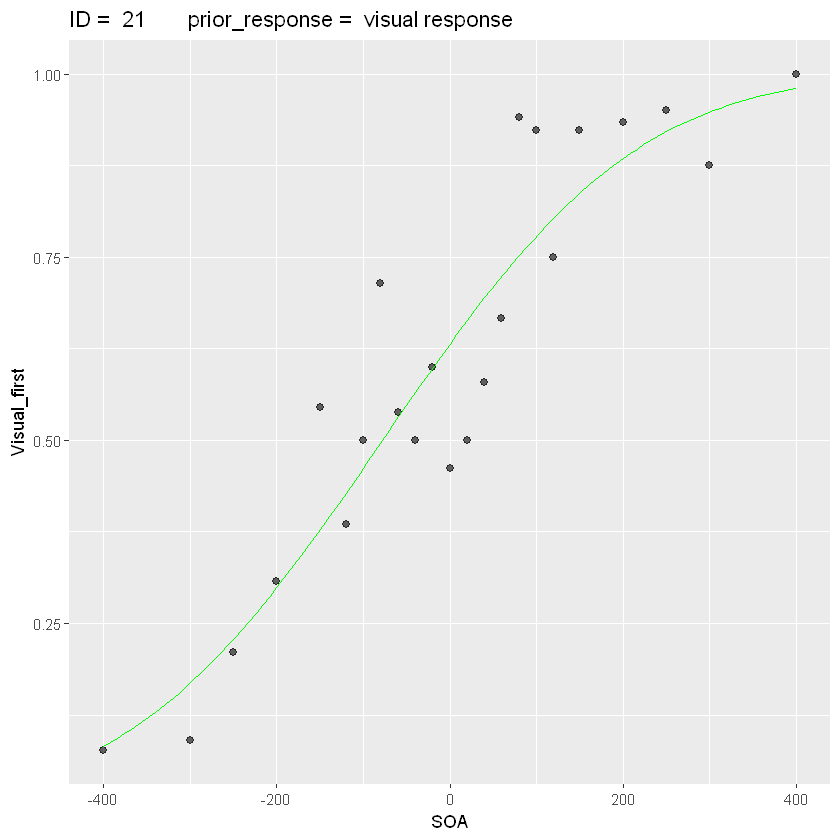

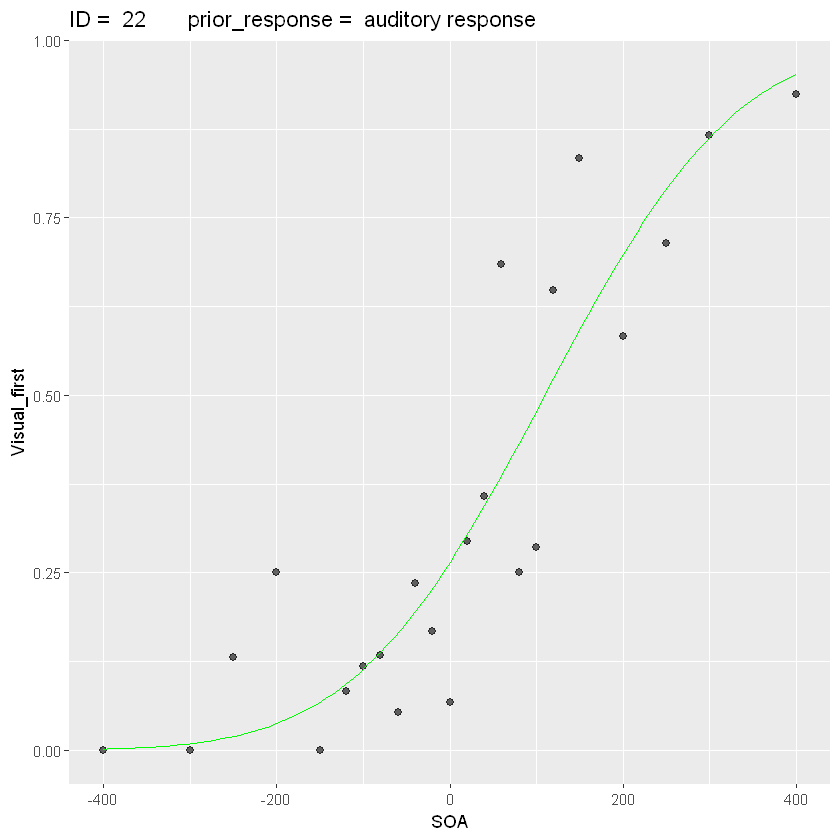

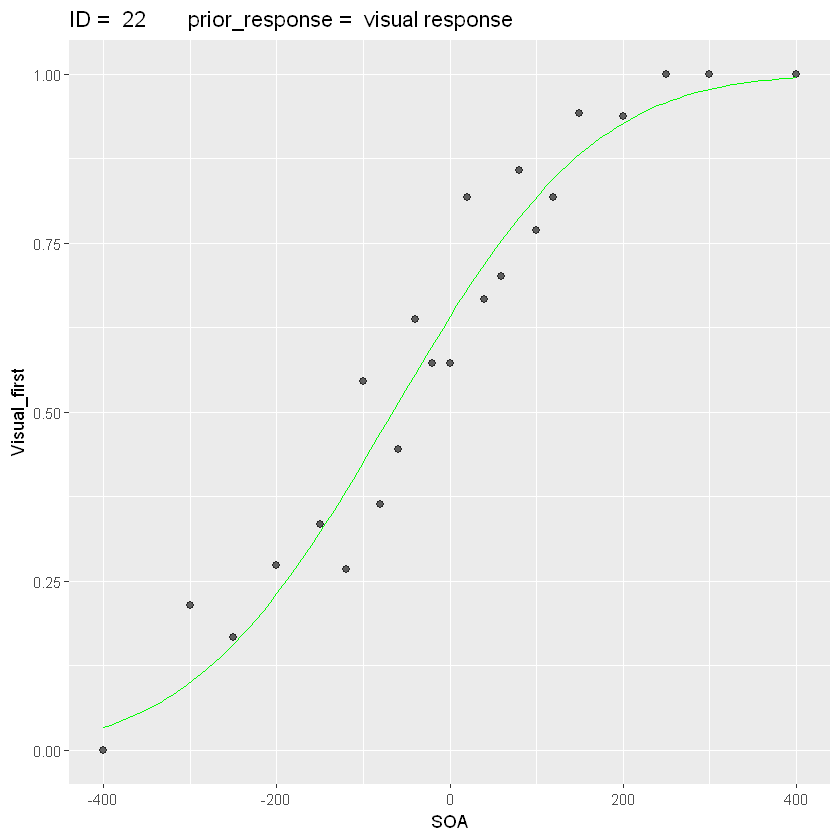

In [59]:
# plot of fits

ff <- function(x,SD,criterion){
    pnorm(x, mean = criterion, sd = SD)
}

df <- data %>% group_by(ID, prior_response, SOA) %>%   
    summarise(
                Visual_first = mean(Visual_first == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(data$ID)){

    d1 <- df %>% filter(ID == subj)
    for(pr in unique(data$prior_response)){
        d2 <- d1 %>% filter(prior_response == pr)

        sd <- (psy_results %>% filter(ID == subj) %>% filter(prior_response == pr))$SD
        cri <- (psy_results %>% filter(ID == subj) %>% filter(prior_response == pr))$criterion
        print(ggplot(d2, aes(x = SOA, y = Visual_first)) +
                geom_point(size = 2, alpha = 0.6) +
                geom_function(fun=ff, args = list(SD = sd, criterion = cri), color='green') +
                labs(title = paste('ID = ',subj,'      prior_response = ',pr)))
}}

In [60]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  return(1 - SS_res / SS_tot)
}

psy_results$R2 <- NA

for(i in 1:nrow(psy_results)){
  id <- psy_results$ID[i]
  pr <- psy_results$prior_response[i]
  subdata <- df %>% filter(ID == id) %>% filter(prior_response == pr)
  pred <- ff(subdata$SOA, psy_results$SD[i], psy_results$criterion[i])
  psy_results$R2[i] <- R2(subdata$Visual_first, pred)
}

head(psy_results)

,ID,prior_response,SD,criterion,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,1,auditory response,177.2456,41.65522,0.8233571
2,1,visual response,231.3840,-106.95318,0.8221904
3,3,auditory response,273.2830,-83.61495,0.7809663
4,3,visual response,180.4212,-25.56019,0.8974483
5,5,auditory response,158.2461,-105.22898,0.7959663
6,5,visual response,204.6033,-107.44080,0.8674410


In [61]:
# look at bad fits
psy_results %>% arrange(R2)

ID,prior_response,SD,criterion,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
6,auditory response,431.00517,84.245751,0.5683150
20,auditory response,259.42517,-96.219098,0.6395171
11,visual response,384.93445,-156.228269,0.6450529
9,auditory response,203.30176,-98.583669,0.6594253
11,auditory response,266.59886,225.286963,0.7092765
10,auditory response,176.29903,-59.167944,0.7579119
19,visual response,264.27995,-109.146698,0.7806628
3,auditory response,273.28296,-83.614946,0.7809663
7,auditory response,261.70906,-41.718040,0.7849486


In [116]:
# save parameter values
write_xlsx(
  psy_results,
  "files/TOJ_prior_response_observer_parameters.xlsx"
)

###############################################################
## 3-4 Plot group-level fits

In [12]:
model_results <- read_xlsx("files/TOJ_prior_response_observer_parameters.xlsx")
head(model_results)

ID,prior_response,SD,criterion
<dbl>,<chr>,<dbl>,<dbl>
1,auditory response,177.2456,41.65522
1,visual response,231.3840,-106.95318
3,auditory response,273.2830,-83.61495
3,visual response,180.4212,-25.56019
5,auditory response,158.2461,-105.22897
5,visual response,204.6033,-107.44080


In [13]:
# compute predicted psychometric curves

ff <- function(x,SD,criterion){
    pnorm(x, mean = criterion, sd = SD)
}

df_predicted <- data.frame()

for(subj in unique(model_results$ID)){
    for(pr in unique(model_results$prior_response)){
        sd <- (model_results %>% filter(ID == subj) %>% filter(prior_response == pr))$SD
        cri <- (model_results %>% filter(ID == subj) %>% filter(prior_response == pr))$criterion
        df <- data.frame(ID=subj, prior_response=pr, SOA = -400:400, visual_first=ff(-400:400,sd,cri))
        df_predicted <- rbind(df_predicted, df)
}}

df_predicted_summary <- df_predicted %>%
  group_by(prior_response, SOA) %>%
  summarise(
    mean_visual_first = mean(visual_first),
    se = sd(visual_first) / sqrt(n()),
    .groups = "drop"
  )

In [14]:
# Compute observed psychometric data

df_summary <- data %>%
  filter(!(ID %in% c(2,18))) %>%
  group_by(ID, prior_response, SOA) %>%
  summarise(
    mvf = mean(Visual_first),
    .groups = "drop"
  ) %>% group_by(prior_response, SOA) %>%
  summarise(
    mean_visual_first = mean(mvf),
    se = sd(mvf) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

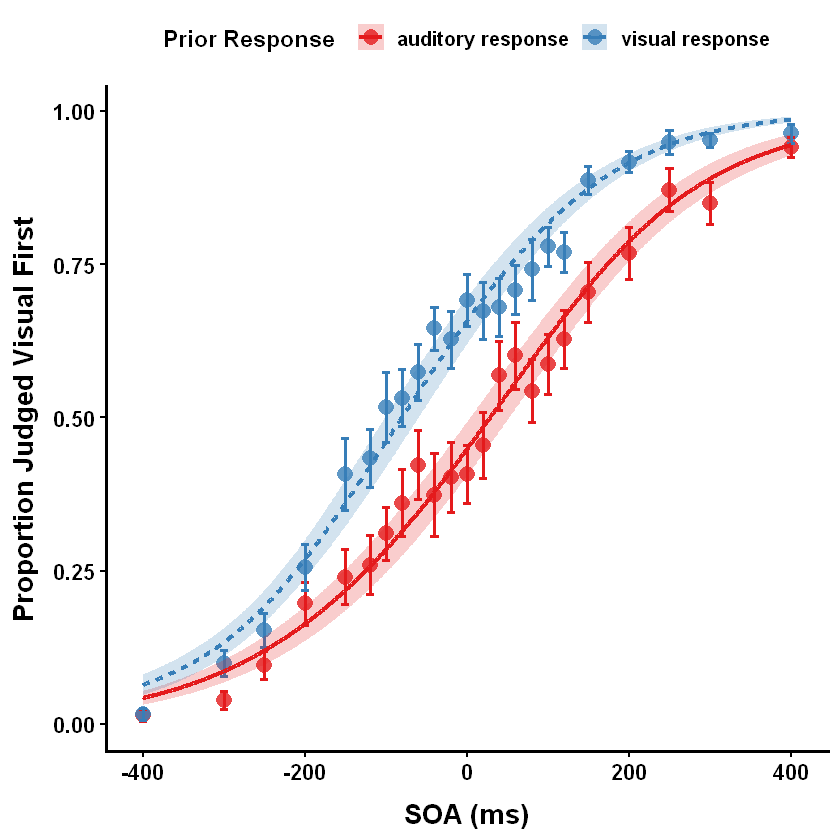

In [15]:
# =========================================================
# Summarize observed TOJ responses across SOAs as a function
# of prior response condition and display fitted probit curves.
# =========================================================

# save as PDF
pdf(file="figures/TOJ_prior_response_observer_response.pdf", width = 10, height = 8)  

# Create the plot with publication-style formatting
p_toj_prior_resp <- ggplot() +
  # Plot observed data points
  geom_point(
    data = df_summary,
    aes(x = SOA, y = mean_visual_first, color = prior_response),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +

  # Add error bars for observed data
  geom_errorbar(
    data = df_summary,
    aes(
      x = SOA,
      ymin = mean_visual_first - se,
      ymax = mean_visual_first + se,
      color = prior_response
    ),
    width = 10,
    linewidth = 1
  ) +

  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_visual_first - se,
      ymax = mean_visual_first + se,
      fill = prior_response,
      group = prior_response
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_visual_first,
      color = prior_response,
      linetype = prior_response,
      group = prior_response
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Proportion Judged Visual First",
    color = "Prior Response",
    linetype = "Prior Response",
    fill = "Prior Response"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_toj_prior_resp
dev.off()
# 3. Display the plot
print(p_toj_prior_resp)

###############################################################
## 3-5 Statistical test of SD

In [62]:
psy_results <- read_xlsx("files/TOJ_prior_response_observer_parameters.xlsx")
head(psy_results)

ID,prior_response,SD,criterion
<dbl>,<chr>,<dbl>,<dbl>
1,auditory response,177.2456,41.65522
1,visual response,231.3840,-106.95318
3,auditory response,273.2830,-83.61495
3,visual response,180.4212,-25.56019
5,auditory response,158.2461,-105.22897
5,visual response,204.6033,-107.44080


In [63]:
psy_results2 <- psy_results %>% group_by(ID) %>% summarise(
    diff = SD[prior_response == "visual response"] - SD[prior_response == "auditory response"],
    .groups = "drop"
  )
head(psy_results2)

ID,diff
<dbl>,<dbl>
1,54.13841
3,-92.86177
5,46.35716
6,-139.04622
7,-68.43185
8,-70.96796


In [64]:
#summary
psy_results %>% group_by(prior_response) %>%  get_summary_stats(SD)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory response,SD,18,99.872,431.005,203.444,174.561,261.138,86.577,75.004,213.267,77.797,18.337,38.688
visual response,SD,18,80.440,384.934,188.039,129.472,231.713,102.241,68.979,191.835,75.168,17.717,37.380


In [65]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-139.046,118.336,-5.919,-82.567,29.6,112.167,90.861,-21.432,75.053,17.69,37.323


In [66]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [67]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [68]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9566592,0.5386412


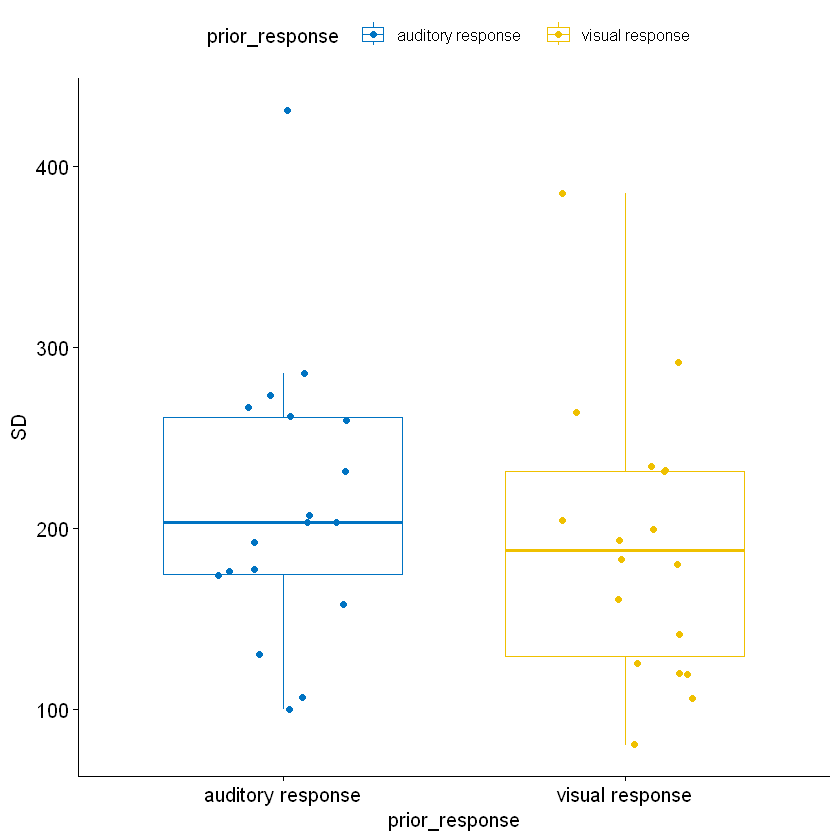

In [69]:
#plot
ggboxplot(
  psy_results, x = "prior_response", y = "SD",
  color = "prior_response", palette = "jco", add = "jitter"
  )

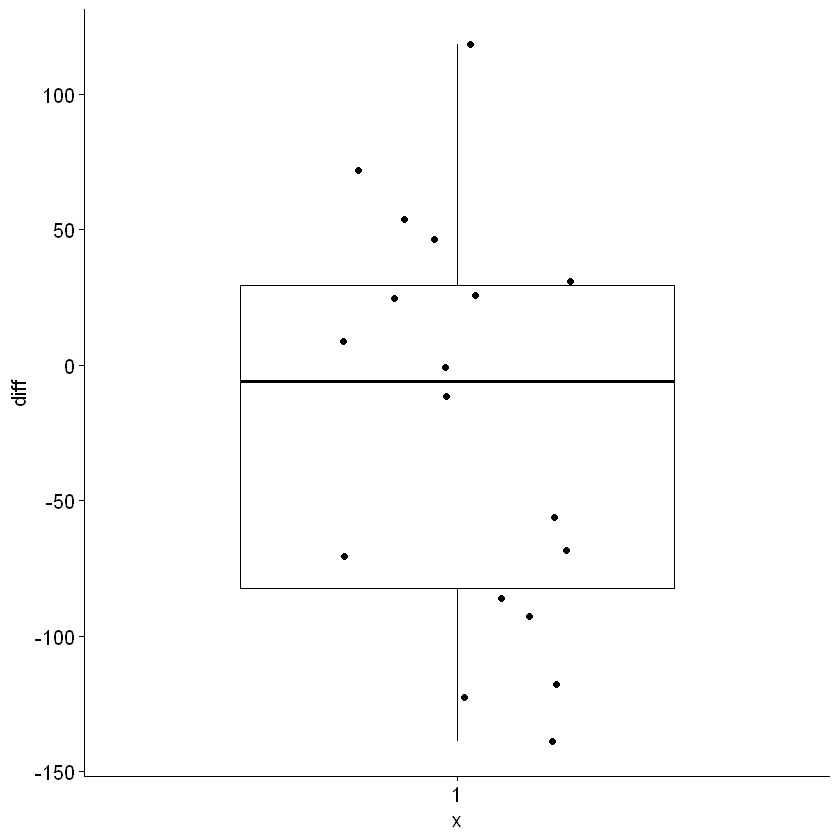

In [70]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [71]:
psy_results %>% t_test(SD ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,21.43212,SD,auditory response,visual response,18,18,1.211525,0.242,17,-15.89094,58.75518,T-test,two.sided


In [72]:
psy_results %>% cohens_d(SD ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,SD,auditory response,visual response,0.2855592,18,18,small


###############################################################
## 3-6 Statisttical test of criterion

In [74]:
psy_results <- read_xlsx("files/TOJ_prior_response_observer_parameters.xlsx")
head(psy_results)

ID,prior_response,SD,criterion
<dbl>,<chr>,<dbl>,<dbl>
1,auditory response,177.2456,41.65522
1,visual response,231.3840,-106.95318
3,auditory response,273.2830,-83.61495
3,visual response,180.4212,-25.56019
5,auditory response,158.2461,-105.22897
5,visual response,204.6033,-107.44080


In [75]:
psy_results2 <- psy_results %>% group_by(ID) %>% summarise(
    diff = criterion[prior_response == "visual response"] - criterion[prior_response == "auditory response"],
    .groups = "drop"
  )
head(psy_results2)

ID,diff
<dbl>,<dbl>
1,-148.608399
3,58.054752
5,-2.211826
6,-154.327570
7,-70.619332
8,-66.903062


In [76]:
#summary
psy_results %>% group_by(prior_response) %>%  get_summary_stats(criterion)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory response,criterion,18,-105.229,225.287,17.572,-54.805,90.118,144.924,112.117,24.195,96.292,22.696,47.885
visual response,criterion,18,-193.275,92.978,-92.381,-125.253,-55.864,69.389,56.440,-81.851,68.273,16.092,33.951


In [77]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-381.515,58.055,-82.655,-152.898,-46.288,106.61,102.021,-106.045,106.978,25.215,53.199


In [78]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
11,-381.5152,TRUE,FALSE


In [79]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [80]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9324099,0.214053


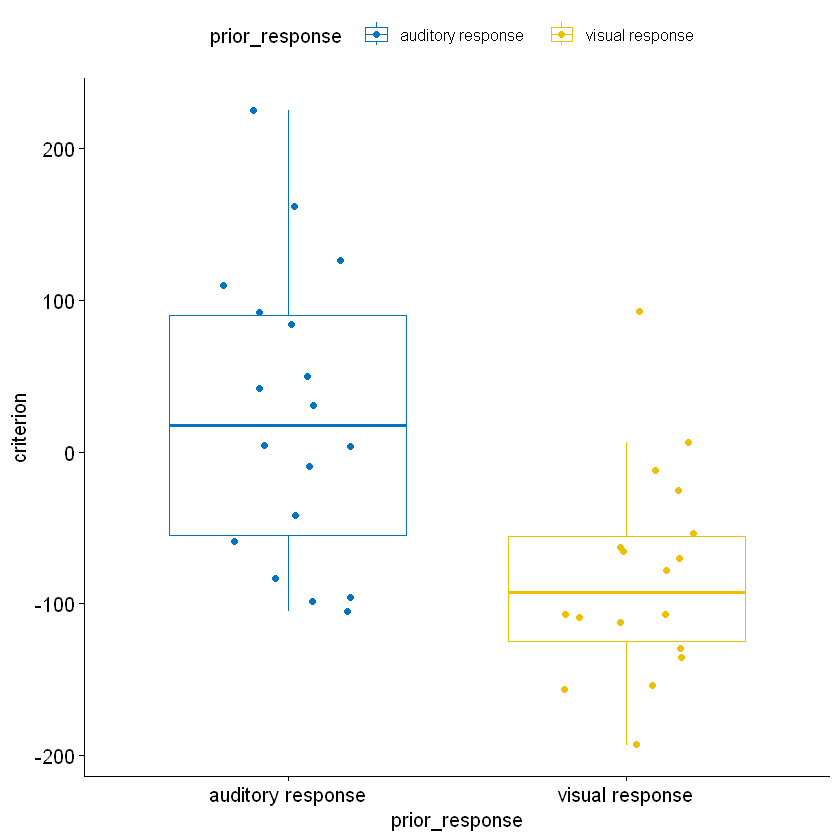

In [81]:
#plot
ggboxplot(
  psy_results, x = "prior_response", y = "criterion",
  color = "prior_response", palette = "jco", add = "jitter"
  )

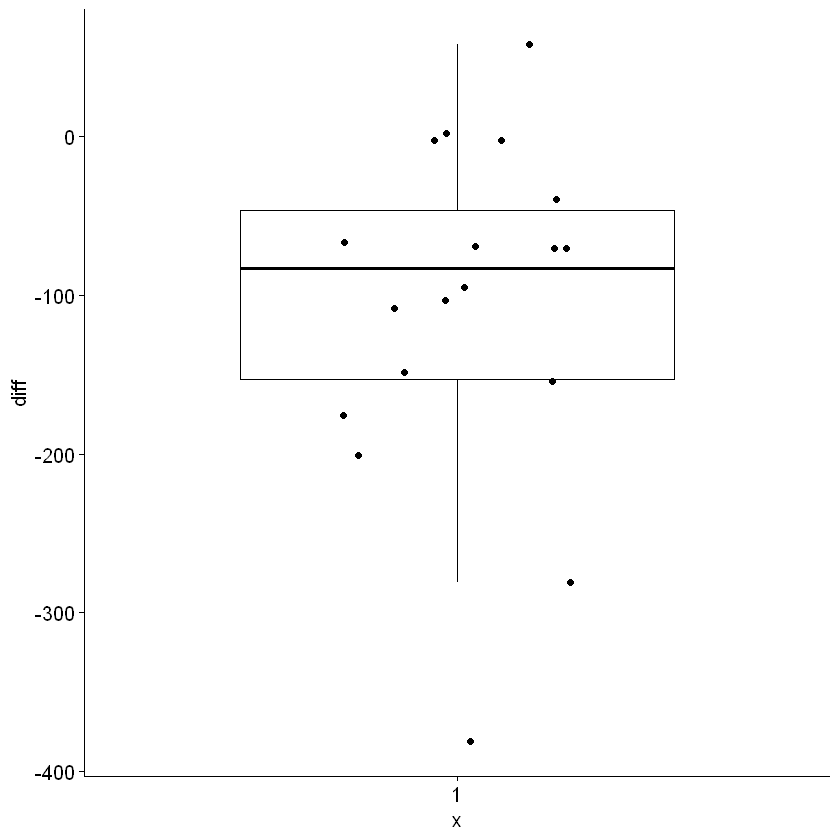

In [82]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [83]:
psy_results %>% t_test(criterion ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,106.0455,criterion,auditory response,visual response,18,18,4.205643,0.000594,17,52.84638,159.2445,T-test,two.sided


In [84]:
psy_results %>% cohens_d(criterion ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,criterion,auditory response,visual response,0.9912796,18,18,large


###############################################################\
###############################################################
# 4- Visualizing Serial Dependence Statistical Results

In [88]:
# =========================================================
# Read observer model parameter estimates
# =========================================================

prior_stimulus_psy_results = read_xlsx("files/TOJ_prior_stimulus_observer_parameters.xlsx")
prior_response_psy_results = read_xlsx("files/TOJ_prior_response_observer_parameters.xlsx")

colnames(prior_stimulus_psy_results)[3] <- "sigma"
colnames(prior_response_psy_results)[3] <- "sigma"
colnames(prior_stimulus_psy_results)[1] <- "participant"
colnames(prior_response_psy_results)[1] <- "participant"

In [89]:
# =========================================================
# Convert observer model results to long format
# =========================================================

stimulus_long <- prior_stimulus_psy_results %>%
  pivot_longer(
    cols = c(sigma, criterion),
    names_to = "parameter",
    values_to = "value"
  ) %>%
  mutate(
    trial_leading = "prior_stimulus",
    type = prior_stimulus
  ) %>%
  select(participant, trial_leading, type, parameter, value)

response_long <- prior_response_psy_results %>%
  pivot_longer(
    cols = c(sigma, criterion),
    names_to = "parameter",
    values_to = "value"
  ) %>%
  mutate(
    trial_leading = "prior_response",
    type = prior_response
  ) %>%
  select(participant, trial_leading, type, parameter, value)

In [90]:
# =========================================================
# Combine stimulus-driven and response-driven recalibration
# =========================================================

combined_results <- bind_rows(
  stimulus_long,
  response_long
) 

In [94]:
# =========================================================
# Clean and standardize labels
# =========================================================

combined_results <- combined_results %>%
  mutate(
    type = recode(type,
        "auditory_leading"="auditory leading",
        'visual_leading'='visual leading'
    ),
    trial_leading = recode(trial_leading,
      "prior_stimulus" = "Prior stimulus",
      "prior_response" = "Prior response"
    )
  ) %>%
  arrange(participant, trial_leading, type, parameter)

In [95]:
# =========================================================
# Remove outliers
# =========================================================

In [96]:
# =========================================================
# Compute group mean and standard error
# =========================================================

d <- combined_results %>%
  group_by(trial_leading, parameter, type) %>%
  summarise(
    mean = mean(value, na.rm = TRUE),
    sd = sd(value, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

In [101]:
# =========================================================
# Paired t-tests comparing recalibration conditions
# =========================================================

stat_test <- combined_results %>%
  group_by(trial_leading, parameter) %>%
  t_test(value ~ type, paired = TRUE) %>%
  add_significance()

stat_test <- stat_test %>%
  add_xy_position(x = "trial_leading", dodge = 0.8)

Warning message in geom_errorbar(data = d, aes(group = type, fill = c(), y = c(), :
"Ignoring unknown aesthetics: fill"


png 
  2

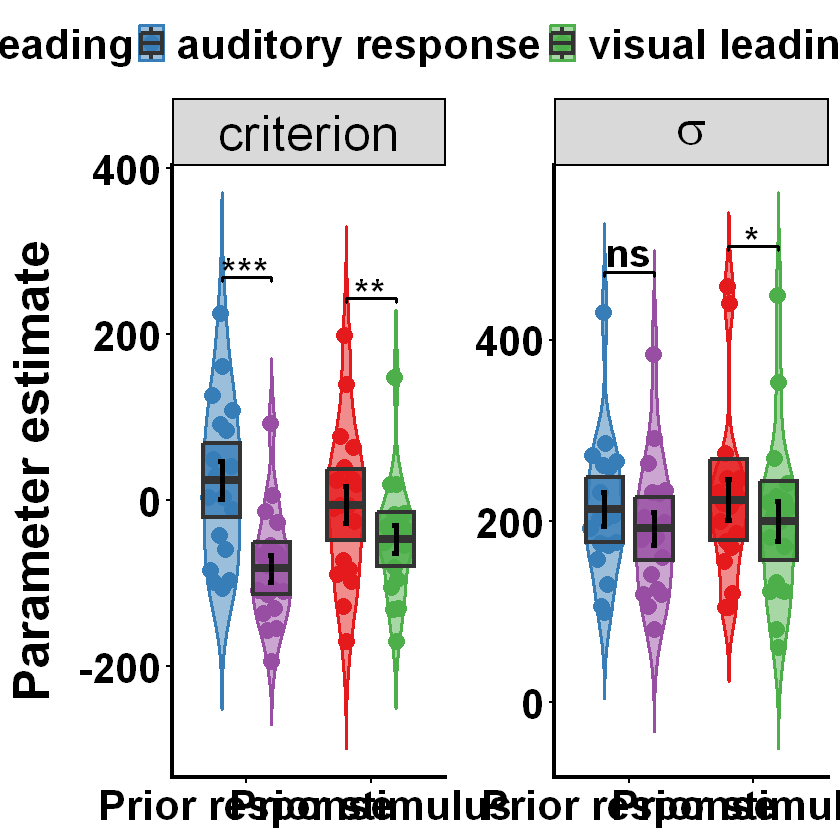

In [105]:
pdf(file="figures/TOJ_observer_params.pdf", width = 15, height = 8)

p <- ggplot(data=combined_results, mapping=aes(x=trial_leading, y=value)) +
    # Increased linewidth to 1 and alpha to 0.5 for a bolder, more vivid violin look
    geom_violin(trim = FALSE, alpha=.5, width=.6, scale='width', position=position_dodge(.8), aes(colour=type, fill = type), linewidth=1) +
    # Increased alpha to 1 and stroke to 1.2 so individual points stand out sharply
    geom_quasirandom(dodge.width=.8, aes(colour=type), width=.13, shape=16, stroke=1.2, size=4, alpha=1) +
    # Increased boxplot linewidth to 1.2 for better visibility inside the violin
    geom_boxplot(alpha=.8, data=d, aes(y=c(), ymin=mean-sd*1.96, lower=mean-sd*1.96, middle=mean, upper=mean+sd*1.96, ymax=mean+sd*1.96, fill=type),
                 stat = "identity", position=position_dodge(.8), width=0.6, linewidth = 1.2) +
    # Increased errorbar linewidth to 1.5 to make the SD bounds extra bold
    geom_errorbar(data=d, aes(group=type, fill=c(), y=c(), ymin=mean-sd, ymax=mean+sd), position=position_dodge(.8), width=.1, linewidth=1.5) +
    # Significance bars kept bold with your original size 8.5
    stat_pvalue_manual(stat_test, label = "p.adj.signif", tip.length = 0.01, size = 8.5, bracket.size = 1.1, fontface = "bold") +
    facet_wrap(vars(parameter), scales='free_y', nrow=1, labeller = label_parsed) + labs(x = NULL,y = "Parameter estimate",color = NULL,fill = NULL) + 
    scale_color_brewer(palette = "Set1") +
    scale_fill_brewer(palette = "Set1") +

    # Clean publication theme with enhanced line thickness and your exact custom text sizes
    theme_classic(base_size = 14) +
    theme(
      axis.title.x     = element_text(face = "bold", size = 18, margin = margin(t = 10)),
      axis.title.y     = element_text(face = "bold", size = 30, margin = margin(r = 12)),
      axis.text.x      = element_text(face = "bold", size = 25, color = "black"),
      axis.text.y      = element_text(face = "bold", size = 25, color = "black"),
      strip.text       = element_text(face = "bold", size = 30, color = "black"),
      # Made the facet frame borders bolder (linewidth = 1)
      strip.background = element_rect(fill = "gray85", color = "black", linewidth = 1),
      legend.title     = element_text(face = "bold", size = 25),
      legend.text      = element_text(face = "bold", size = 25),
      legend.position  = "top",
      # Made main axis lines bolder (linewidth = 1.2)
      axis.line        = element_line(linewidth = 1.2),
      panel.spacing    = unit(1.2, "lines")
    )
p
dev.off()
print(p)